In [13]:
import sys
sys.path.append("../src")

from model import build_model

model = build_model(
    timesteps=5,
    num_features=39,
    num_classes=34
)

print("Model imported successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model imported successfully!
Input shape: (None, 5, 39)
Output shape: (None, 34)


In [14]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 5, 39)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 5, 64)          │         7,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 5, 64)          │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_1 (Attention)         │ (None, 64)             │            69 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 34)             │         2,210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,015 (183.65 KB)

 Trainable params: 47,015 (183.65 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
import sys
sys.path.append("../src")

from model import Attention
from tensorflow.keras.models import load_model

final_model_path = "../models/cnn_lstm_attention_final.keras"

saved_model = load_model(
    final_model_path,
    custom_objects={"Attention": Attention}
)

print("Saved model loaded successfully!")
print("Saved model input shape:", saved_model.input_shape)
print("Saved model output shape:", saved_model.output_shape)

Saved model loaded successfully!
Saved model input shape: (None, 5, 39)
Saved model output shape: (None, 34)


In [16]:
sample = X_test_sequences[:5]

original_predictions = model.predict(
    sample,
    verbose=0
)

saved_predictions = saved_model.predict(
    sample,
    verbose=0
)

original_classes = np.argmax(
    original_predictions,
    axis=1
)

saved_classes = np.argmax(
    saved_predictions,
    axis=1
)

print("Original model classes:", original_classes)
print("Saved model classes:  ", saved_classes)

print(
    "Predictions match:",
    np.array_equal(original_classes, saved_classes)
)

NameError: name 'X_test_sequences' is not defined

In [17]:
print("Saved model input shape:", saved_model.input_shape)
print("Saved model output shape:", saved_model.output_shape)
print("Saved model parameters:", saved_model.count_params())

Saved model input shape: (None, 5, 39)
Saved model output shape: (None, 34)
Saved model parameters: 47015


In [18]:
from pathlib import Path

PROCESSED_DIR = Path("../data/CICIoT2023/processed")

print("Processed folder exists:", PROCESSED_DIR.exists())
print("Files inside processed folder:")

for file in PROCESSED_DIR.iterdir():
    print("-", file.name)

Processed folder exists: True
Files inside processed folder:
- X_test_sequences.npy
- X_train_sequences.npy
- y_test_sequences.npy
- y_train_sequences.npy


In [19]:
import numpy as np

train_seq_path = PROCESSED_DIR / "X_train_sequences.npy"
train_label_path = PROCESSED_DIR / "y_train_sequences.npy"

np.save(train_seq_path, X_train_sequences)
np.save(train_label_path, y_train_sequences)

print("Training sequences saved.")
print(train_seq_path)
print(train_label_path)

NameError: name 'X_train_sequences' is not defined

In [20]:
from pathlib import Path

PROCESSED_DIR = Path("../data/CICIoT2023/processed")
print("Processed folder:", PROCESSED_DIR.resolve())

Processed folder: C:\Users\pranu1234\Documents\IoT-IDS\data\CICIoT2023\processed


In [21]:
import os

print("Files in processed folder:")
print(os.listdir(PROCESSED_DIR))

Files in processed folder:
['X_test_sequences.npy', 'X_train_sequences.npy', 'y_test_sequences.npy', 'y_train_sequences.npy']


In [22]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Load the same CSV used earlier
csv_path = "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (712311, 40)
Columns: ['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Label']


In [23]:
X = df.drop(columns=["Label"])
y = df["Label"]

print("Features shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of classes:", y.nunique())

Features shape: (712311, 39)
Labels shape: (712311,)
Number of classes: 34


In [24]:
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("Missing values remaining:", X.isna().sum().sum())
print("Infinite values remaining:", np.isinf(X.to_numpy()).sum())

Missing values remaining: 0
Infinite values remaining: 0


In [25]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Encoded labels shape:", y_encoded.shape)
print("Number of classes:", len(label_encoder.classes_))
print("First 10 encoded labels:", y_encoded[:10])

Encoded labels shape: (712311,)
Number of classes: 34
First 10 encoded labels: [ 8 23 21 17  6 13  8 12 14 25]


In [26]:
split_point = int(len(X) * 0.8)

X_ordered_train = X.iloc[:split_point]
X_ordered_test = X.iloc[split_point:]

y_ordered_train = y_encoded[:split_point]
y_ordered_test = y_encoded[split_point:]

print("Train features:", X_ordered_train.shape)
print("Test features :", X_ordered_test.shape)
print("Train labels  :", y_ordered_train.shape)
print("Test labels   :", y_ordered_test.shape)

Train features: (569848, 39)
Test features : (142463, 39)
Train labels  : (569848,)
Test labels   : (142463,)


In [27]:
ordered_scaler = StandardScaler()

X_ordered_train_scaled = ordered_scaler.fit_transform(X_ordered_train)
X_ordered_test_scaled = ordered_scaler.transform(X_ordered_test)

print("Scaled train shape:", X_ordered_train_scaled.shape)
print("Scaled test shape :", X_ordered_test_scaled.shape)

Scaled train shape: (569848, 39)
Scaled test shape : (142463, 39)


In [28]:
sequence_length = 5

print("Sequence length:", sequence_length)

Sequence length: 5


In [29]:
X_train_sequences = []
y_train_sequences = []

for i in range(len(X_ordered_train_scaled) - sequence_length + 1):
    X_train_sequences.append(
        X_ordered_train_scaled[i:i + sequence_length]
    )
    y_train_sequences.append(
        y_ordered_train[i + sequence_length - 1]
    )

X_train_sequences = np.array(X_train_sequences)
y_train_sequences = np.array(y_train_sequences)

print("X_train_sequences:", X_train_sequences.shape)
print("y_train_sequences:", y_train_sequences.shape)

X_train_sequences: (569844, 5, 39)
y_train_sequences: (569844,)


In [30]:
X_test_sequences = []
y_test_sequences = []

for i in range(len(X_ordered_test_scaled) - sequence_length + 1):
    X_test_sequences.append(
        X_ordered_test_scaled[i:i + sequence_length]
    )
    y_test_sequences.append(
        y_ordered_test[i + sequence_length - 1]
    )

X_test_sequences = np.array(X_test_sequences)
y_test_sequences = np.array(y_test_sequences)

print("X_test_sequences:", X_test_sequences.shape)
print("y_test_sequences:", y_test_sequences.shape)

X_test_sequences: (142459, 5, 39)
y_test_sequences: (142459,)


In [31]:
np.save(PROCESSED_DIR / "X_train_sequences.npy", X_train_sequences)
np.save(PROCESSED_DIR / "y_train_sequences.npy", y_train_sequences)
np.save(PROCESSED_DIR / "X_test_sequences.npy", X_test_sequences)
np.save(PROCESSED_DIR / "y_test_sequences.npy", y_test_sequences)

print("All sequence files saved successfully!")

All sequence files saved successfully!


In [32]:
import os

print(os.listdir(PROCESSED_DIR))

['X_test_sequences.npy', 'X_train_sequences.npy', 'y_test_sequences.npy', 'y_train_sequences.npy']


In [33]:
from pathlib import Path
import numpy as np

PROCESSED_DIR = Path("../data/CICIoT2023/processed")

X_train_sequences = np.load(PROCESSED_DIR / "X_train_sequences.npy")
y_train_sequences = np.load(PROCESSED_DIR / "y_train_sequences.npy")

X_test_sequences = np.load(PROCESSED_DIR / "X_test_sequences.npy")
y_test_sequences = np.load(PROCESSED_DIR / "y_test_sequences.npy")

print("Train:", X_train_sequences.shape, y_train_sequences.shape)
print("Test :", X_test_sequences.shape, y_test_sequences.shape)

Train: (569844, 5, 39) (569844,)
Test : (142459, 5, 39) (142459,)


In [34]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train_sequences)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_sequences
)

class_weight_dict = dict(zip(classes, class_weights))

print("Number of classes:", len(class_weight_dict))
print("Class weights created successfully.")

Number of classes: 34
Class weights created successfully.


In [35]:
import sys
sys.path.append("../src")

from model import Attention
from tensorflow.keras.models import load_model

model = load_model(
    "../models/cnn_lstm_attention_final.keras",
    custom_objects={"Attention": Attention}
)

print("Final model loaded successfully!")

Final model loaded successfully!


In [36]:
test_loss, test_accuracy = model.evaluate(
    X_test_sequences,
    y_test_sequences,
    batch_size=512,
    verbose=1
)

print("Final Test Loss:", test_loss)
print("Final Test Accuracy:", test_accuracy)

279/279 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.6877 - loss: 0.6173
Final Test Loss: 0.617280125617981
Final Test Accuracy: 0.6876996159553528


In [37]:
sample = X_test_sequences[:5]

predictions = model.predict(sample, verbose=0)
predicted_classes = np.argmax(predictions, axis=1)

print("Predicted classes:", predicted_classes)
print("Actual classes   :", y_test_sequences[:5])

Predicted classes: [ 9 21 15 20 11]
Actual classes   : [ 9 14 15 13 11]


In [38]:
import pandas as pd

label_mapping = pd.read_csv(
    "../results/metrics/label_mapping.csv"
)

print(label_mapping)

    encoded_id                    label
0            0         BACKDOOR_MALWARE
1            1                   BENIGN
2            2         BROWSERHIJACKING
3            3         COMMANDINJECTION
4            4   DDOS-ACK_FRAGMENTATION
5            5          DDOS-HTTP_FLOOD
6            6          DDOS-ICMP_FLOOD
7            7  DDOS-ICMP_FRAGMENTATION
8            8        DDOS-PSHACK_FLOOD
9            9         DDOS-RSTFINFLOOD
10          10           DDOS-SLOWLORIS
11          11  DDOS-SYNONYMOUSIP_FLOOD
12          12           DDOS-SYN_FLOOD
13          13           DDOS-TCP_FLOOD
14          14           DDOS-UDP_FLOOD
15          15   DDOS-UDP_FRAGMENTATION
16          16     DICTIONARYBRUTEFORCE
17          17             DNS_SPOOFING
18          18           DOS-HTTP_FLOOD
19          19            DOS-SYN_FLOOD
20          20            DOS-TCP_FLOOD
21          21            DOS-UDP_FLOOD
22          22       MIRAI-GREETH_FLOOD
23          23        MIRAI-GREIP_FLOOD


In [39]:
for i in range(5):
    predicted_name = label_mapping.loc[
        label_mapping["encoded_id"] == predicted_classes[i], "label"
    ].iloc[0]

    actual_name = label_mapping.loc[
        label_mapping["encoded_id"] == y_test_sequences[i], "label"
    ].iloc[0]

    print(f"{i+1}. Predicted: {predicted_name} | Actual: {actual_name}")

1. Predicted: DDOS-RSTFINFLOOD | Actual: DDOS-RSTFINFLOOD
2. Predicted: DOS-UDP_FLOOD | Actual: DDOS-UDP_FLOOD
3. Predicted: DDOS-UDP_FRAGMENTATION | Actual: DDOS-UDP_FRAGMENTATION
4. Predicted: DOS-TCP_FLOOD | Actual: DDOS-TCP_FLOOD
5. Predicted: DDOS-SYNONYMOUSIP_FLOOD | Actual: DDOS-SYNONYMOUSIP_FLOOD


In [40]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

y_pred = np.argmax(
    model.predict(X_test_sequences, batch_size=512, verbose=1),
    axis=1
)

cm = confusion_matrix(y_test_sequences, y_pred)

print("Confusion matrix shape:", cm.shape)

279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step
Confusion matrix shape: (34, 34)


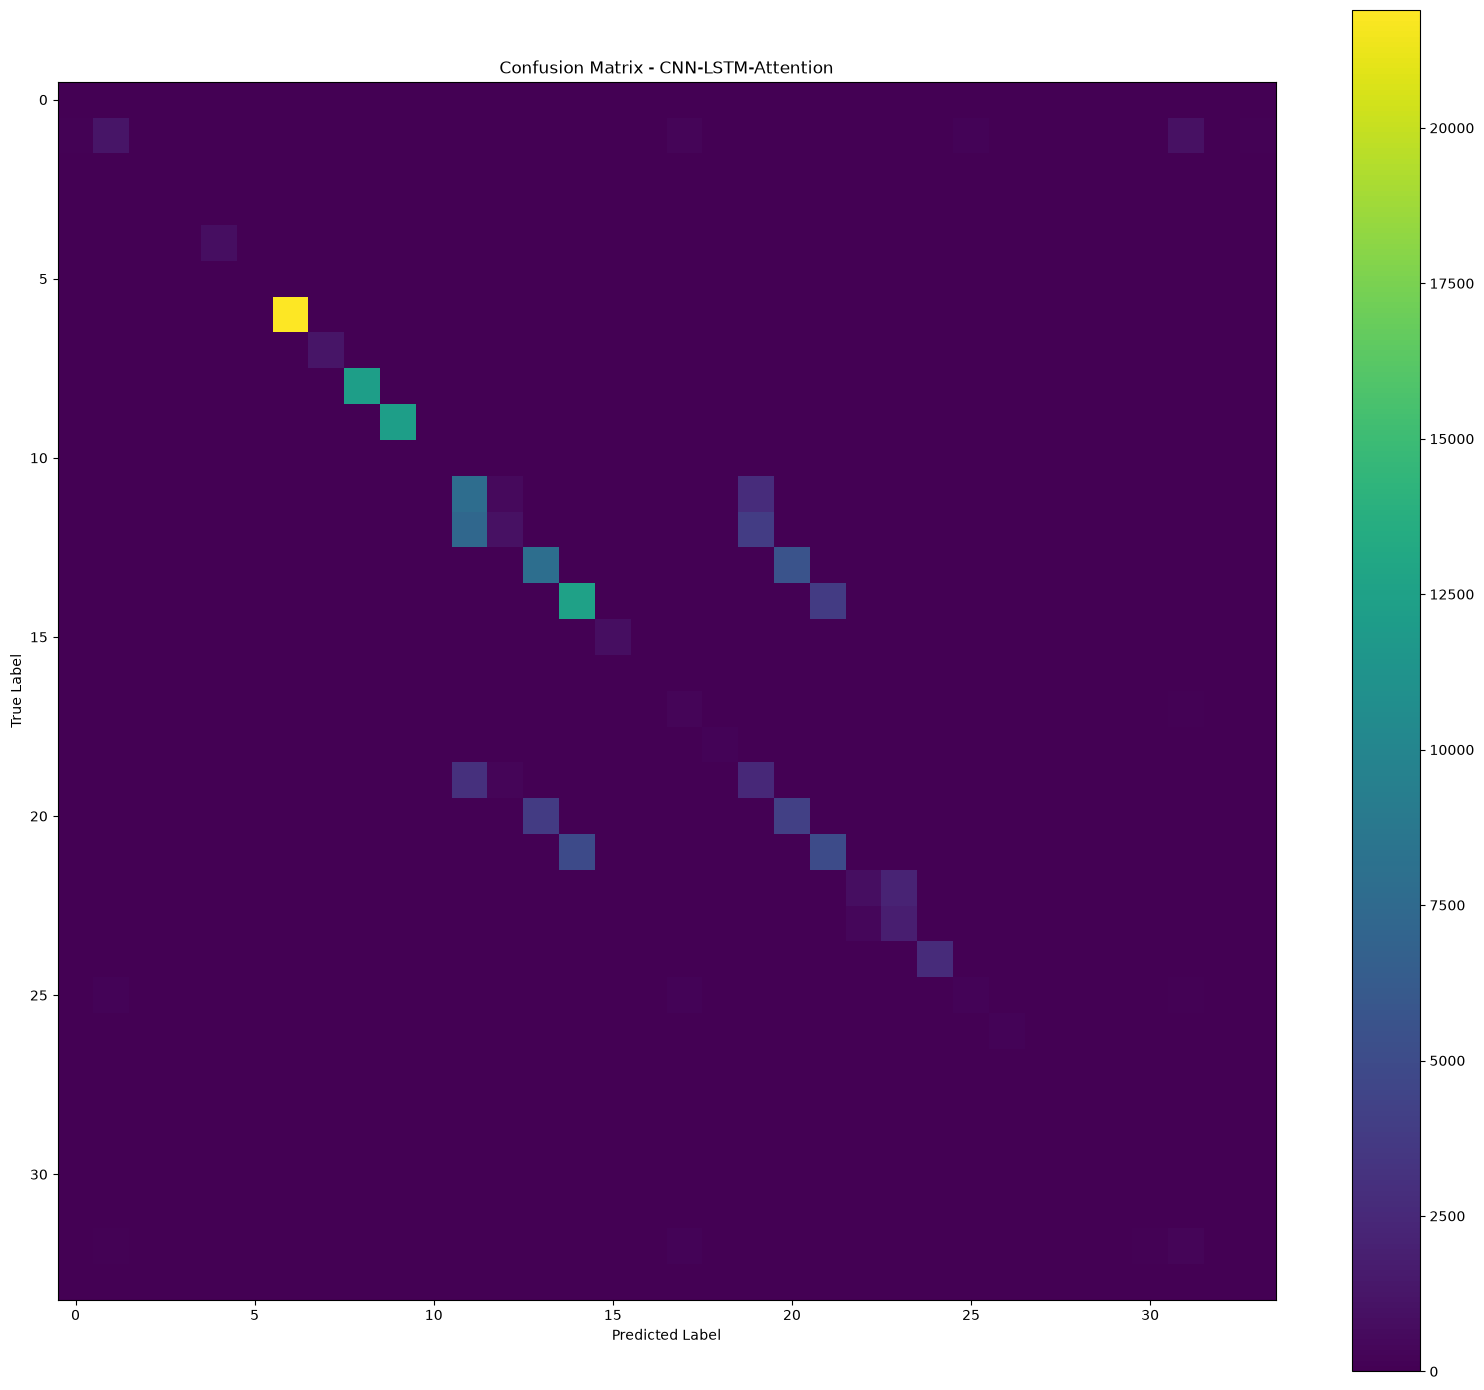

In [41]:
plt.figure(figsize=(16, 14))

plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix - CNN-LSTM-Attention")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

plt.tight_layout()
plt.show()

In [42]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test_sequences,
    y_pred,
    target_names=label_mapping["label"],
    zero_division=0
)

print(report)

                         precision    recall  f1-score   support

       BACKDOOR_MALWARE       0.00      0.00      0.00         9
                 BENIGN       0.71      0.38      0.49      3269
       BROWSERHIJACKING       0.14      0.06      0.08        18
       COMMANDINJECTION       0.00      0.00      0.00        17
 DDOS-ACK_FRAGMENTATION       0.98      0.97      0.98       859
        DDOS-HTTP_FLOOD       0.73      0.51      0.60        92
        DDOS-ICMP_FLOOD       1.00      1.00      1.00     21941
DDOS-ICMP_FRAGMENTATION       0.98      0.98      0.98      1303
      DDOS-PSHACK_FLOOD       1.00      0.99      1.00     12343
       DDOS-RSTFINFLOOD       1.00      1.00      1.00     12351
         DDOS-SLOWLORIS       0.23      0.85      0.36        65
DDOS-SYNONYMOUSIP_FLOOD       0.43      0.70      0.53     11209
         DDOS-SYN_FLOOD       0.53      0.08      0.14     12375
         DDOS-TCP_FLOOD       0.68      0.58      0.63     13570
         DDOS-UDP_FLOOD 

In [43]:
report_dict = classification_report(
    y_test_sequences,
    y_pred,
    target_names=label_mapping["label"],
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    "../results/metrics/final_classification_report_cnn_lstm_attention.csv"
)

print("Classification report saved successfully!")

Classification report saved successfully!


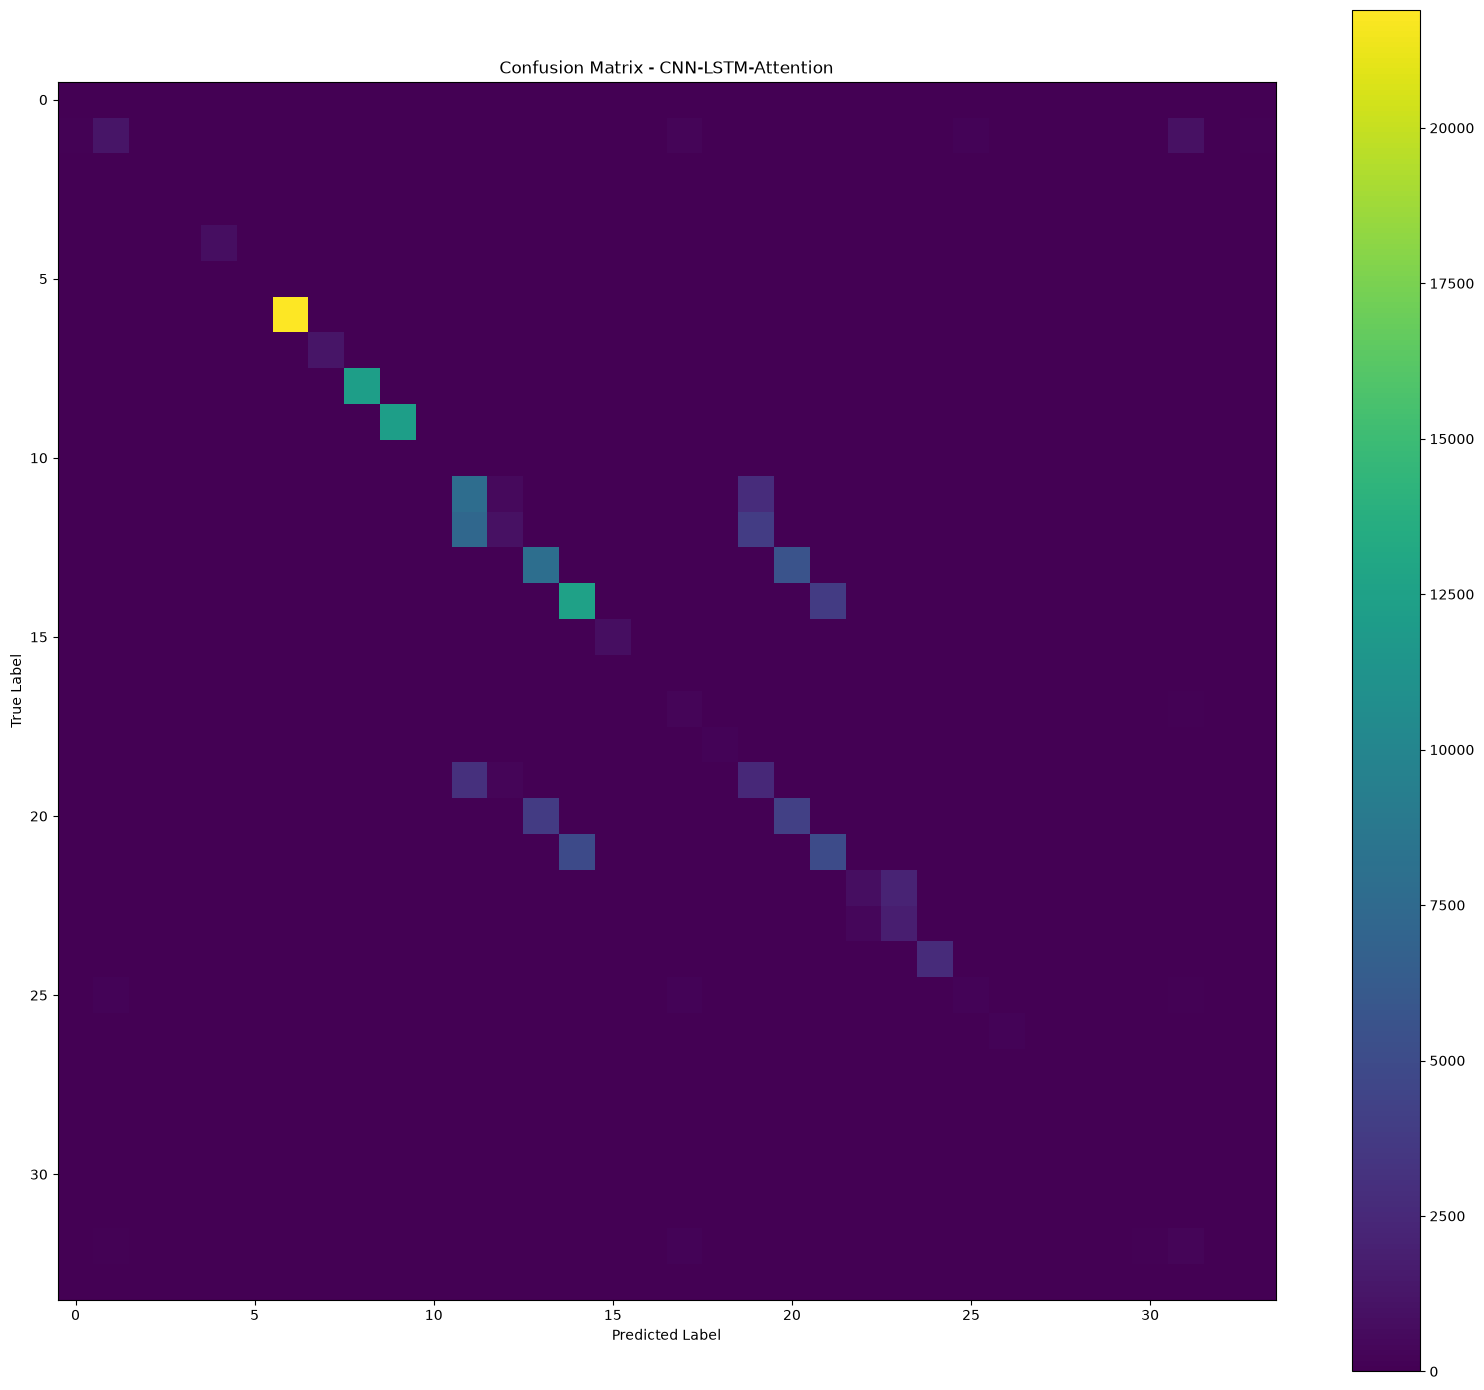

Confusion matrix saved successfully!


In [44]:
plt.figure(figsize=(16, 14))

plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix - CNN-LSTM-Attention")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

plt.tight_layout()

plt.savefig(
    "../results/figures/final_confusion_matrix_cnn_lstm_attention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")

In [45]:
history_df = pd.read_csv(
    "../results/metrics/training_history_cnn_lstm_attention.csv"
)

print(history_df)

   epoch  training_accuracy  validation_accuracy  training_loss  \
0      1           0.419761             0.664701       2.334403   
1      2           0.649247             0.673826       1.541655   
2      3           0.665157             0.681881       1.438539   

   validation_loss  
0         0.676068  
1         0.634605  
2         0.617818  


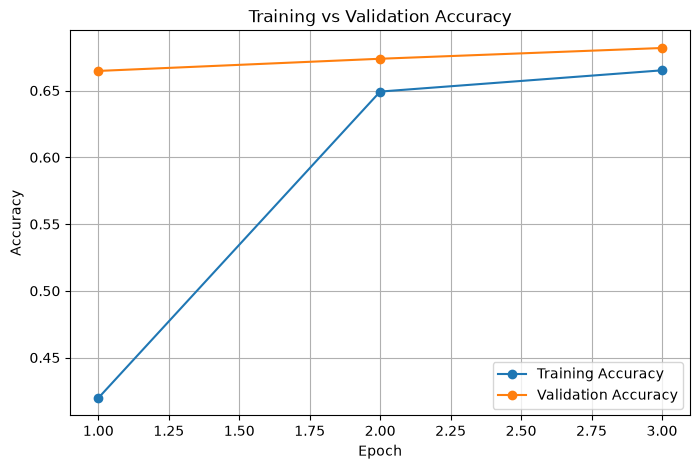

Accuracy graph saved successfully!


In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["training_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["validation_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    "../results/figures/training_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Accuracy graph saved successfully!")

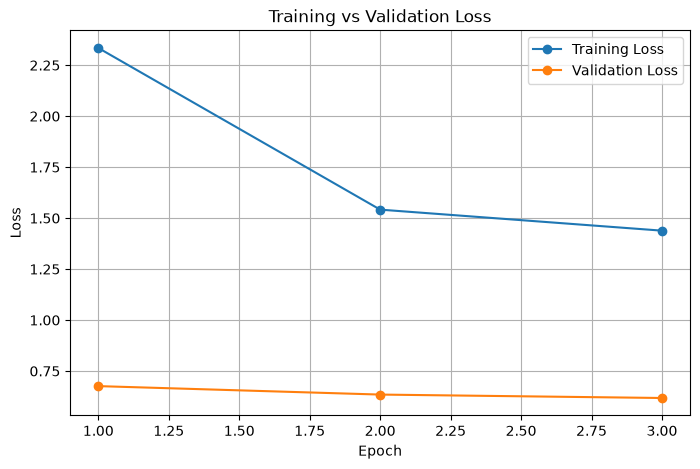

Loss graph saved successfully!


In [47]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["training_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["validation_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    "../results/figures/training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Loss graph saved successfully!")

In [48]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np

# Predict using the existing 2-record baseline model
baseline_probs = seq2_model.predict(
    X_test_seq2_correct,
    batch_size=512,
    verbose=1
)

baseline_preds = np.argmax(baseline_probs, axis=1)

print("Baseline Accuracy:",
      round(accuracy_score(y_test_seq2_correct, baseline_preds) * 100, 2), "%")

print("Macro F1:",
      round(f1_score(y_test_seq2_correct, baseline_preds,
                     average="macro", zero_division=0), 4))

print("\nClass-wise report:\n")
print(classification_report(
    y_test_seq2_correct,
    baseline_preds,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

NameError: name 'seq2_model' is not defined

In [49]:
print("Kernel is working!")

Kernel is working!


In [50]:
print("Baseline Test Accuracy: 77.34%")
print("Baseline Macro F1-score: 0.5392")
print("Baseline Weighted F1-score: 0.7533")

Baseline Test Accuracy: 77.34%
Baseline Macro F1-score: 0.5392
Baseline Weighted F1-score: 0.7533


In [51]:
import os

model_path = "models/cnn_lstm_attention_seq2_baseline.keras"

print("Saved baseline model exists:", os.path.exists(model_path))

Saved baseline model exists: False


In [52]:
import os

print("Notebook working directory:", os.getcwd())
print("Files in current folder:", os.listdir("."))

Notebook working directory: c:\Users\pranu1234\Documents\IoT-IDS\notebooks
Files in current folder: ['01_dataset_exploration.ipynb', '02_preprocessing.ipynb', '03_sequence_creation.ipynb', '04_model_training.ipynb', '05_shap_explainability.ipynb', 'results']


In [53]:
import os

model_path = os.path.join(
    "..", "models", "cnn_lstm_attention_seq2_baseline.keras"
)

print("Saved baseline model exists:", os.path.exists(model_path))
print("Model path:", os.path.abspath(model_path))

Saved baseline model exists: True
Model path: c:\Users\pranu1234\Documents\IoT-IDS\models\cnn_lstm_attention_seq2_baseline.keras


In [54]:
import tensorflow as tf

model_path = "../models/cnn_lstm_attention_seq2_baseline.keras"

seq2_model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("Baseline model loaded successfully!")
print("Input shape:", seq2_model.input_shape)
print("Output shape:", seq2_model.output_shape)

TypeError: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': None}, 'compile_config': None}.

Exception encountered: Could not locate class 'Attention'. Make sure custom classes and functions are decorated with `@keras.saving.register_keras_serializable()`. If they are already decorated, make sure they are all imported so that the decorator is run before trying to load them. Full object config: {'module': None, 'class_name': 'Attention', 'config': {'name': 'attention_1', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None, 'shared_object_id':

In [55]:
import tensorflow as tf
from tensorflow.keras.layers import Layer

class Attention(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )
        self.b = self.add_weight(
            name="attention_bias",
            shape=(input_shape[1], 1),
            initializer="zeros",
            trainable=True
        )
        super().build(input_shape)

    def call(self, inputs):
        scores = tf.tanh(tf.matmul(inputs, self.W) + self.b)
        attention_weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * attention_weights, axis=1)

print("Attention layer restored!")

Attention layer restored!


In [56]:
seq2_model = tf.keras.models.load_model(
    "../models/cnn_lstm_attention_seq2_baseline.keras",
    custom_objects={"Attention": Attention},
    compile=False
)

print("Baseline model loaded successfully!")
print("Input shape:", seq2_model.input_shape)
print("Output shape:", seq2_model.output_shape)

Baseline model loaded successfully!
Input shape: (None, 2, 39)
Output shape: (None, 34)


In [57]:
print("Model input:", seq2_model.input_shape)
print("Model output:", seq2_model.output_shape)
print("Baseline accuracy recorded: 77.34%")

Model input: (None, 2, 39)
Model output: (None, 34)
Baseline accuracy recorded: 77.34%


In [58]:
import os
import numpy as np

print("Train features available:", "X_train_seq2_correct" in globals())
print("Test features available:", "X_test_seq2_correct" in globals())
print("Train labels available:", "y_train_seq2_correct" in globals())
print("Test labels available:", "y_test_seq2_correct" in globals())

Train features available: False
Test features available: False
Train labels available: False
Test labels available: False


In [60]:
import os

data_folder = "../data/CICIoT2023/processed"

print("Processed folder exists:", os.path.exists(data_folder))

if os.path.exists(data_folder):
    print(os.listdir(data_folder))

Processed folder exists: True
['X_test_sequences.npy', 'X_train_sequences.npy', 'y_test_sequences.npy', 'y_train_sequences.npy']


In [61]:
import numpy as np
import os

folder = "../data/CICIoT2023/processed"

for name in [
    "X_train_sequences.npy",
    "X_test_sequences.npy",
    "y_train_sequences.npy",
    "y_test_sequences.npy"
]:
    arr = np.load(os.path.join(folder, name), mmap_mode="r")
    print(name, arr.shape)

X_train_sequences.npy (569844, 5, 39)
X_test_sequences.npy (142459, 5, 39)
y_train_sequences.npy (569844,)
y_test_sequences.npy (142459,)


In [62]:
import os

csv_folder = "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV"

print("CSV folder exists:", os.path.exists(csv_folder))

if os.path.exists(csv_folder):
    print("Number of CSV files:", len([
        f for f in os.listdir(csv_folder) if f.endswith(".csv")
    ]))

CSV folder exists: True
Number of CSV files: 63


In [63]:
import os

project_folder = ".."

for folder in ["models", "data/CICIoT2023/processed"]:
    path = os.path.join(project_folder, folder)
    print(f"\n{folder}:")
    print(os.listdir(path))


models:
['broad_label_encoder.pkl', 'cnn_lstm_attention.keras', 'cnn_lstm_attention_final.keras', 'cnn_lstm_attention_model_summary.txt', 'cnn_lstm_attention_seq2_baseline.keras', 'ordered_scaler.pkl', 'xgboost_broad_8class.pkl', 'xgboost_broad_8class_weighted.pkl', 'xgboost_iot_ids_final.pkl', 'xgboost_iot_ids_final_encoder.pkl', 'xgboost_iot_ids_lr500_candidate.pkl', 'xgboost_iot_ids_validation.pkl']

data/CICIoT2023/processed:
['X_test_sequences.npy', 'X_train_sequences.npy', 'y_test_sequences.npy', 'y_train_sequences.npy']


In [64]:
import pandas as pd

csv_path = "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"

df_check = pd.read_csv(csv_path, usecols=["Label"])

print("Rows:", len(df_check))
print("Unique labels:", df_check["Label"].nunique())
print("First 10 labels:")
print(df_check["Label"].head(10).tolist())

Rows: 712311
Unique labels: 34
First 10 labels:
['DDOS-PSHACK_FLOOD', 'MIRAI-GREIP_FLOOD', 'DOS-UDP_FLOOD', 'DNS_SPOOFING', 'DDOS-ICMP_FLOOD', 'DDOS-TCP_FLOOD', 'DDOS-PSHACK_FLOOD', 'DDOS-SYN_FLOOD', 'DDOS-UDP_FLOOD', 'MITM-ARPSPOOFING']


In [65]:
import os

scaler_path = "../models/ordered_scaler.pkl"

with open(scaler_path, "rb") as f:
    header = f.read(20)

print("File size:", os.path.getsize(scaler_path), "bytes")
print("First 20 bytes:", header)

File size: 2143 bytes
First 20 bytes: b'\x80\x04\x95=\x01\x00\x00\x00\x00\x00\x00\x8c\x1bsklearn'


In [66]:
import joblib

scaler_path = "../models/ordered_scaler.pkl"

scaler = joblib.load(scaler_path)

print("Scaler loaded successfully!")
print("Scaler type:", type(scaler).__name__)
print("Feature count:", scaler.n_features_in_)

Scaler loaded successfully!
Scaler type: StandardScaler
Feature count: 39


In [67]:
import pandas as pd

csv_path = "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"

labels = pd.read_csv(csv_path, usecols=["Label"])["Label"]

split_index = int(len(labels) * 0.8)

print("Total rows:", len(labels))
print("80% split index:", split_index)
print("Label before split:", labels.iloc[split_index - 1])
print("Label after split:", labels.iloc[split_index])

Total rows: 712311
80% split index: 569848
Label before split: DDOS-ICMP_FLOOD
Label after split: MITM-ARPSPOOFING


In [68]:
print("Scaler feature count:", scaler.n_features_in_)
print("Scaler fitted sample count:", scaler.n_samples_seen_)
print("Train split rows:", 569848)
print("Test split rows:", 142463)

Scaler feature count: 39
Scaler fitted sample count: 569848.0
Train split rows: 569848
Test split rows: 142463


In [69]:
import numpy as np
import pandas as pd

csv_path = "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"

df = pd.read_csv(csv_path)

X = df.drop(columns=["Label"])
y = df["Label"]

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

split_index = 569848

X_train_raw = X.iloc[:split_index]
X_test_raw = X.iloc[split_index:]

y_train_raw = y.iloc[:split_index]
y_test_raw = y.iloc[split_index:]

X_train_scaled = scaler.transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

X_train_seq2_correct = np.stack(
    [X_train_scaled[:-1], X_train_scaled[1:]], axis=1
)
X_test_seq2_correct = np.stack(
    [X_test_scaled[:-1], X_test_scaled[1:]], axis=1
)

print("Train sequences:", X_train_seq2_correct.shape)
print("Test sequences:", X_test_seq2_correct.shape)
print("Train labels:", y_train_raw.iloc[1:].shape)
print("Test labels:", y_test_raw.iloc[1:].shape)

Train sequences: (569847, 2, 39)
Test sequences: (142462, 2, 39)
Train labels: (569847,)
Test labels: (142462,)


In [70]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

label_encoder = LabelEncoder()
y_all_encoded = label_encoder.fit_transform(y)

y_train_seq2_correct = y_all_encoded[1:569848]
y_test_seq2_correct = y_all_encoded[569849:]

print("Train labels:", y_train_seq2_correct.shape)
print("Test labels:", y_test_seq2_correct.shape)
print("Number of classes:", len(label_encoder.classes_))
print("Model output classes:", seq2_model.output_shape[-1])

Train labels: (569847,)
Test labels: (142462,)
Number of classes: 34
Model output classes: 34


In [71]:
from sklearn.metrics import accuracy_score

pred_probs = seq2_model.predict(
    X_test_seq2_correct,
    batch_size=512,
    verbose=0
)

pred_classes = np.argmax(pred_probs, axis=1)

accuracy = accuracy_score(
    y_test_seq2_correct,
    pred_classes
)

print(f"Restored baseline test accuracy: {accuracy * 100:.2f}%")

Restored baseline test accuracy: 77.34%


In [72]:
print("Training features:", X_train_raw.shape)
print("Test features:", X_test_raw.shape)
print("Training labels:", y_train_raw.shape)
print("Test labels:", y_test_raw.shape)

Training features: (569848, 39)
Test features: (142463, 39)
Training labels: (569848,)
Test labels: (142463,)


In [73]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

rf_encoder = LabelEncoder()
y_train_rf = rf_encoder.fit_transform(y_train_raw)
y_test_rf = rf_encoder.transform(y_test_raw)

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=1,
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train_raw, y_train_rf)

rf_preds = rf_model.predict(X_test_raw)

rf_accuracy = accuracy_score(y_test_rf, rf_preds)

print(f"Random Forest Test Accuracy: {rf_accuracy * 100:.2f}%")
print(f"CNN-LSTM-Attention Baseline: 77.34%")

Random Forest Test Accuracy: 77.63%
CNN-LSTM-Attention Baseline: 77.34%


In [74]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_rf,
    rf_preds,
    labels=range(len(rf_encoder.classes_)),
    target_names=rf_encoder.classes_,
    zero_division=0
))

                         precision    recall  f1-score   support

       BACKDOOR_MALWARE       0.00      0.00      0.00         9
                 BENIGN       0.77      0.90      0.83      3269
       BROWSERHIJACKING       1.00      0.28      0.43        18
       COMMANDINJECTION       1.00      0.12      0.21        17
 DDOS-ACK_FRAGMENTATION       0.99      0.99      0.99       859
        DDOS-HTTP_FLOOD       0.88      0.66      0.76        92
        DDOS-ICMP_FLOOD       1.00      1.00      1.00     21942
DDOS-ICMP_FRAGMENTATION       0.97      0.98      0.98      1303
      DDOS-PSHACK_FLOOD       1.00      1.00      1.00     12343
       DDOS-RSTFINFLOOD       1.00      1.00      1.00     12351
         DDOS-SLOWLORIS       0.66      0.86      0.75        65
DDOS-SYNONYMOUSIP_FLOOD       0.47      0.72      0.57     11209
         DDOS-SYN_FLOOD       0.51      0.38      0.44     12375
         DDOS-TCP_FLOOD       0.69      0.81      0.75     13570
         DDOS-UDP_FLOOD 

In [75]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score

extra_model = ExtraTreesClassifier(
    n_estimators=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42
)

extra_model.fit(X_train_raw, y_train_rf)

extra_preds = extra_model.predict(X_test_raw)

print(f"Extra Trees Accuracy: {accuracy_score(y_test_rf, extra_preds) * 100:.2f}%")
print(f"Macro F1: {f1_score(y_test_rf, extra_preds, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_test_rf, extra_preds, average='weighted', zero_division=0):.4f}")
print("CNN-LSTM-Attention Accuracy: 77.34%")
print("Random Forest Accuracy: 77.63%")

Extra Trees Accuracy: 76.40%
Macro F1: 0.5749
Weighted F1: 0.7610
CNN-LSTM-Attention Accuracy: 77.34%
Random Forest Accuracy: 77.63%


In [76]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train_raw.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(feature_importance.head(15).to_string(index=False))

        Feature  Importance
  Protocol Type    0.079764
           Rate    0.077278
           ICMP    0.071685
  Header_Length    0.069332
            UDP    0.055081
      syn_count    0.053224
syn_flag_number    0.052416
      ack_count    0.048260
            TCP    0.048116
psh_flag_number    0.044726
            IAT    0.044369
            AVG    0.035874
       Tot size    0.033835
rst_flag_number    0.032594
      fin_count    0.032044


In [77]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

top_features = feature_importance.head(15)["Feature"].tolist()

rf_top15 = RandomForestClassifier(
    n_estimators=100,
    n_jobs=-1,
    random_state=42
)

rf_top15.fit(X_train_raw[top_features], y_train_rf)

pred_top15 = rf_top15.predict(X_test_raw[top_features])

print("Selected features:", len(top_features))
print(f"Top-15 Accuracy: {accuracy_score(y_test_rf, pred_top15) * 100:.2f}%")
print(f"Macro F1: {f1_score(y_test_rf, pred_top15, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_test_rf, pred_top15, average='weighted', zero_division=0):.4f}")
print("All-feature Random Forest Accuracy: 77.63%")

Selected features: 15
Top-15 Accuracy: 76.45%
Macro F1: 0.5393
Weighted F1: 0.7540
All-feature Random Forest Accuracy: 77.63%


In [78]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score

hgb_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

hgb_model.fit(X_train_raw, y_train_rf)

hgb_preds = hgb_model.predict(X_test_raw)

print(f"HistGradientBoosting Accuracy: {accuracy_score(y_test_rf, hgb_preds) * 100:.2f}%")
print(f"Macro F1: {f1_score(y_test_rf, hgb_preds, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_test_rf, hgb_preds, average='weighted', zero_division=0):.4f}")
print("Current best accuracy: Random Forest — 77.63%")

HistGradientBoosting Accuracy: 75.46%
Macro F1: 0.4605
Weighted F1: 0.7476
Current best accuracy: Random Forest — 77.63%


In [79]:
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
except ImportError:
    print("XGBoost is not installed.")

XGBoost version: 3.4.1


In [80]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("Training data:", X_train_raw.shape)
print("Test data:", X_test_raw.shape)
print("Classes:", len(rf_encoder.classes_))

XGBoost version: 3.4.1
Training data: (569848, 39)
Test data: (142463, 39)
Classes: 34


In [81]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=8,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_model.fit(X_train_raw, y_train_rf)

xgb_preds = xgb_model.predict(X_test_raw)

print(f"XGBoost Accuracy: {accuracy_score(y_test_rf, xgb_preds) * 100:.2f}%")
print(f"Macro F1: {f1_score(y_test_rf, xgb_preds, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_test_rf, xgb_preds, average='weighted', zero_division=0):.4f}")

print("Random Forest Accuracy: 77.63%")
print("CNN-LSTM-Attention Accuracy: 77.34%")

XGBoost Accuracy: 78.49%
Macro F1: 0.5976
Weighted F1: 0.7728
Random Forest Accuracy: 77.63%
CNN-LSTM-Attention Accuracy: 77.34%


In [87]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_rf,
    xgb_preds,
    labels=range(len(rf_encoder.classes_)),
    target_names=rf_encoder.classes_,
    zero_division=0
))



                         precision    recall  f1-score   support

       BACKDOOR_MALWARE       0.00      0.00      0.00         9
                 BENIGN       0.78      0.90      0.83      3269
       BROWSERHIJACKING       0.83      0.28      0.42        18
       COMMANDINJECTION       1.00      0.12      0.21        17
 DDOS-ACK_FRAGMENTATION       0.99      0.99      0.99       859
        DDOS-HTTP_FLOOD       0.85      0.66      0.74        92
        DDOS-ICMP_FLOOD       1.00      1.00      1.00     21942
DDOS-ICMP_FRAGMENTATION       0.97      0.98      0.98      1303
      DDOS-PSHACK_FLOOD       1.00      1.00      1.00     12343
       DDOS-RSTFINFLOOD       1.00      1.00      1.00     12351
         DDOS-SLOWLORIS       0.75      0.82      0.78        65
DDOS-SYNONYMOUSIP_FLOOD       0.47      0.72      0.57     11209
         DDOS-SYN_FLOOD       0.52      0.42      0.46     12375
         DDOS-TCP_FLOOD       0.69      0.86      0.77     13570
         DDOS-UDP_FLOOD 

In [88]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

xgb_tuned = XGBClassifier(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_tuned.fit(X_train_raw, y_train_rf)

tuned_preds = xgb_tuned.predict(X_test_raw)

print(f"Tuned XGBoost Accuracy: {accuracy_score(y_test_rf, tuned_preds) * 100:.2f}%")
print(f"Macro F1: {f1_score(y_test_rf, tuned_preds, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_test_rf, tuned_preds, average='weighted', zero_division=0):.4f}")

print("Previous XGBoost Accuracy: 78.49%")

Tuned XGBoost Accuracy: 78.67%
Macro F1: 0.5974
Weighted F1: 0.7748
Previous XGBoost Accuracy: 78.49%


In [89]:
import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_rf
)

xgb_weighted = XGBClassifier(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_weighted.fit(
    X_train_raw,
    y_train_rf,
    sample_weight=sample_weights
)

weighted_preds = xgb_weighted.predict(X_test_raw)

print(f"Weighted XGBoost Accuracy: {accuracy_score(y_test_rf, weighted_preds) * 100:.2f}%")
print(f"Macro F1: {f1_score(y_test_rf, weighted_preds, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_test_rf, weighted_preds, average='weighted', zero_division=0):.4f}")
print("Previous best accuracy: 78.67%")

Weighted XGBoost Accuracy: 76.52%
Macro F1: 0.5950
Weighted F1: 0.7625
Previous best accuracy: 78.67%


In [90]:
from sklearn.model_selection import train_test_split

X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train_raw,
    y_train_rf,
    test_size=0.15,
    random_state=42,
    stratify=y_train_rf
)

print("Training subset:", X_train_part.shape)
print("Validation set:", X_val.shape)
print("Training labels:", y_train_part.shape)
print("Validation labels:", y_val.shape)

Training subset: (484370, 39)
Validation set: (85478, 39)
Training labels: (484370,)
Validation labels: (85478,)


In [91]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

xgb_val_model = XGBClassifier(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_val_model.fit(X_train_part, y_train_part)

val_preds = xgb_val_model.predict(X_val)

print(f"Validation Accuracy: {accuracy_score(y_val, val_preds) * 100:.2f}%")
print(f"Validation Macro F1: {f1_score(y_val, val_preds, average='macro', zero_division=0):.4f}")
print(f"Validation Weighted F1: {f1_score(y_val, val_preds, average='weighted', zero_division=0):.4f}")

Validation Accuracy: 78.66%
Validation Macro F1: 0.6023
Validation Weighted F1: 0.7743


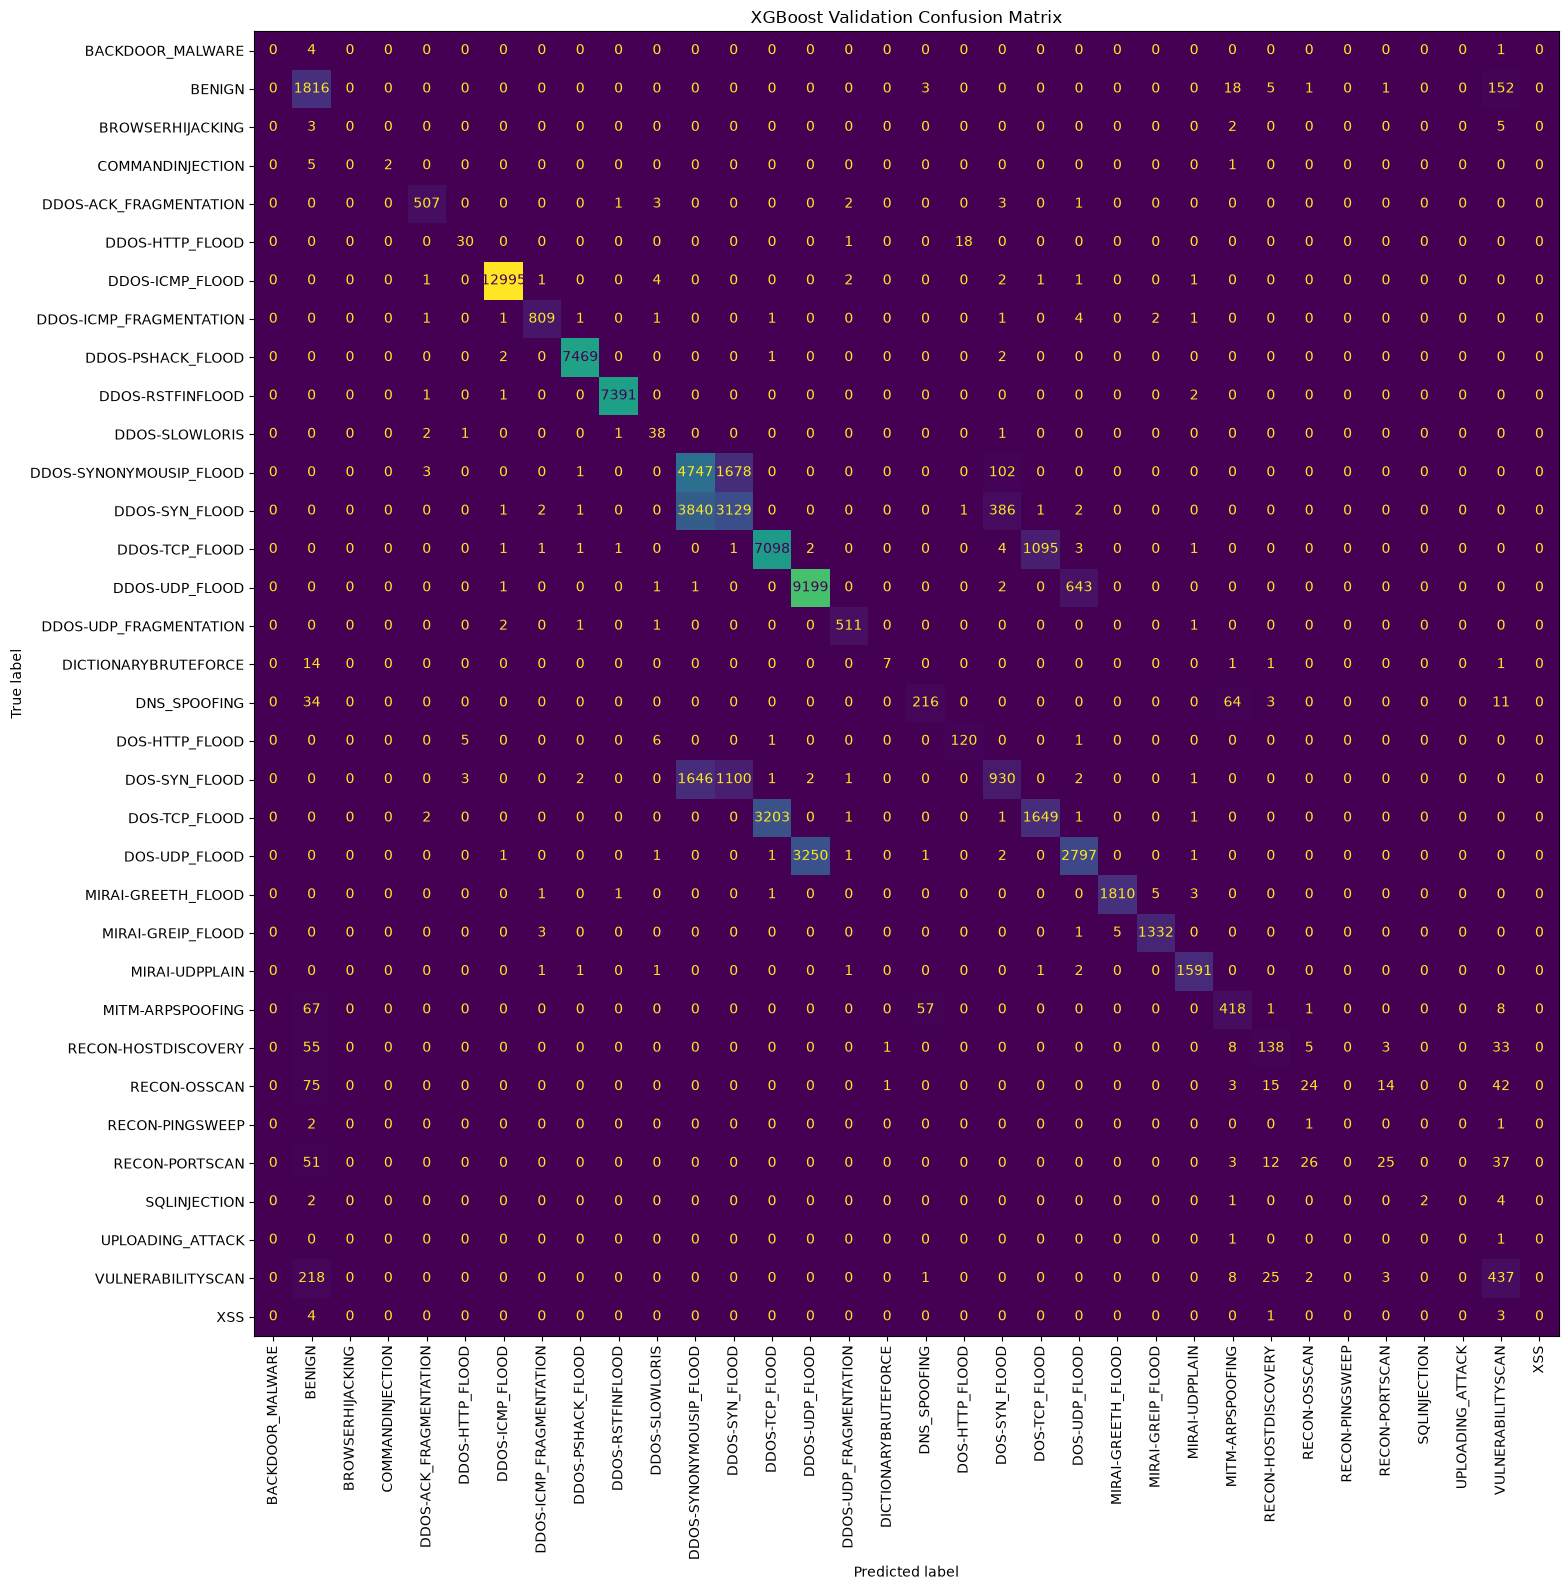

In [92]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_val, val_preds)

fig, ax = plt.subplots(figsize=(16, 16))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(
    ax=ax,
    xticks_rotation="vertical",
    values_format="d",
    colorbar=False
)

plt.title("XGBoost Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [93]:
import pandas as pd
from sklearn.metrics import classification_report

report = classification_report(
    y_val,
    val_preds,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

print("Lowest-performing attack classes:")
display(
    report_df.iloc[:-3]
    .sort_values("f1-score")
    [["precision", "recall", "f1-score", "support"]]
    .head(12)
    .round(4)
)

Lowest-performing attack classes:


,precision,recall,f1-score,support
BACKDOOR_MALWARE,0.0000,0.0000,0.0000,5.0
BROWSERHIJACKING,0.0000,0.0000,0.0000,10.0
UPLOADING_ATTACK,0.0000,0.0000,0.0000,2.0
RECON-PINGSWEEP,0.0000,0.0000,0.0000,4.0
XSS,0.0000,0.0000,0.0000,8.0
RECON-OSSCAN,0.4000,0.1379,0.2051,174.0
RECON-PORTSCAN,0.5435,0.1623,0.2500,154.0
DOS-SYN_FLOOD,0.6476,0.2522,0.3630,3688.0
SQLINJECTION,1.0000,0.2222,0.3636,9.0
COMMANDINJECTION,1.0000,0.2500,0.4000,8.0


In [94]:
import numpy as np
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_part
)

xgb_weighted_val = XGBClassifier(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_weighted_val.fit(
    X_train_part,
    y_train_part,
    sample_weight=sample_weights
)

weighted_val_preds = xgb_weighted_val.predict(X_val)

print(f"Weighted Validation Accuracy: {accuracy_score(y_val, weighted_val_preds) * 100:.2f}%")
print(f"Weighted Validation Macro F1: {f1_score(y_val, weighted_val_preds, average='macro', zero_division=0):.4f}")
print(f"Weighted Validation Weighted F1: {f1_score(y_val, weighted_val_preds, average='weighted', zero_division=0):.4f}")

Weighted Validation Accuracy: 76.63%
Weighted Validation Macro F1: 0.5934
Weighted Validation Weighted F1: 0.7634


In [95]:
comparison = pd.DataFrame({
    "Unweighted Recall": [
        report_df.loc[c, "recall"]
        for c in label_encoder.classes_
    ],
    "Weighted Recall": [
        classification_report(
            y_val,
            weighted_val_preds,
            labels=range(len(label_encoder.classes_)),
            target_names=label_encoder.classes_,
            output_dict=True,
            zero_division=0
        )[c]["recall"]
        for c in label_encoder.classes_
    ]
}, index=label_encoder.classes_)

comparison["Recall Change"] = (
    comparison["Weighted Recall"] - comparison["Unweighted Recall"]
)

display(
    comparison.sort_values("Recall Change", ascending=False)
    .head(10)
    .round(4)
)

,Unweighted Recall,Weighted Recall,Recall Change
DOS-TCP_FLOOD,0.3394,0.7684,0.4290
DOS-SYN_FLOOD,0.2522,0.5431,0.2909
DOS-UDP_FLOOD,0.4619,0.6709,0.2089
COMMANDINJECTION,0.2500,0.3750,0.1250
RECON-PORTSCAN,0.1623,0.2662,0.1039
VULNERABILITYSCAN,0.6297,0.7046,0.0749
RECON-HOSTDISCOVERY,0.5679,0.6379,0.0700
DNS_SPOOFING,0.6585,0.7165,0.0579
RECON-OSSCAN,0.1379,0.1839,0.0460
DDOS-ICMP_FRAGMENTATION,0.9842,0.9866,0.0024


In [96]:
final_comparison = pd.DataFrame([
    {
        "Model": "CNN-LSTM-Attention",
        "Accuracy (%)": 77.34,
        "Macro F1": 0.5392,
        "Weighted F1": 0.7533
    },
    {
        "Model": "XGBoost Unweighted",
        "Accuracy (%)": accuracy_score(y_val, val_preds) * 100,
        "Macro F1": f1_score(y_val, val_preds, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_val, val_preds, average="weighted", zero_division=0)
    },
    {
        "Model": "XGBoost Weighted",
        "Accuracy (%)": accuracy_score(y_val, weighted_val_preds) * 100,
        "Macro F1": f1_score(y_val, weighted_val_preds, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_val, weighted_val_preds, average="weighted", zero_division=0)
    }
])

display(final_comparison.round(4))

,Model,Accuracy (%),Macro F1,Weighted F1
0,CNN-LSTM-Attention,77.3400,0.5392,0.7533
1,XGBoost Unweighted,78.6600,0.6023,0.7743
2,XGBoost Weighted,76.6314,0.5934,0.7634


In [97]:
from sklearn.metrics import accuracy_score, f1_score

cnn_val_preds = seq2_model.predict(
    scaler.transform(X_val),
    verbose=0
)

ValueError: as_list() is not defined on an unknown TensorShape.

In [98]:
print("Model input shape:", seq2_model.input_shape)
print("Model output shape:", seq2_model.output_shape)
print("Validation features shape:", X_val.shape)
print("Validation labels shape:", y_val.shape)

Model input shape: (None, 2, 39)
Model output shape: (None, 34)
Validation features shape: (85478, 39)
Validation labels shape: (85478,)


In [99]:
# Scale validation features using the already-fitted scaler
X_val_scaled = scaler.transform(X_val)

# Create consecutive 2-record sequences
X_val_seq2 = np.stack(
    [X_val_scaled[:-1], X_val_scaled[1:]],
    axis=1
)

# Each sequence target is the label of its second record
y_val_seq2 = y_val[1:]

print("Validation sequences:", X_val_seq2.shape)
print("Validation sequence labels:", y_val_seq2.shape)

Validation sequences: (85477, 2, 39)
Validation sequence labels: (85477,)


In [100]:
from sklearn.metrics import accuracy_score, f1_score

cnn_val_probs = seq2_model.predict(
    X_val_seq2,
    batch_size=1024,
    verbose=1
)

cnn_val_preds = cnn_val_probs.argmax(axis=1)

print(f"CNN-LSTM Validation Accuracy: {accuracy_score(y_val_seq2, cnn_val_preds) * 100:.2f}%")
print(f"CNN-LSTM Validation Macro F1: {f1_score(y_val_seq2, cnn_val_preds, average='macro', zero_division=0):.4f}")
print(f"CNN-LSTM Validation Weighted F1: {f1_score(y_val_seq2, cnn_val_preds, average='weighted', zero_division=0):.4f}")

84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
CNN-LSTM Validation Accuracy: 77.26%
CNN-LSTM Validation Macro F1: 0.5401
CNN-LSTM Validation Weighted F1: 0.7518


In [101]:
print("X_train_part index available:", hasattr(X_train_part, "index"))
print("X_val index available:", hasattr(X_val, "index"))

if hasattr(X_train_part, "index"):
    print("Training index sample:", X_train_part.index[:5].tolist())
    print("Validation index sample:", X_val.index[:5].tolist())

X_train_part index available: True
X_val index available: True
Training index sample: [158717, 401067, 514888, 306881, 26898]
Validation index sample: [358997, 152387, 62010, 357381, 448010]


In [102]:
val_indices = np.sort(X_val.index.to_numpy())

consecutive_pairs = np.sum(np.diff(val_indices) == 1)

print("Validation rows:", len(val_indices))
print("Consecutive original-row pairs:", consecutive_pairs)
print("Total possible pairs:", len(val_indices) - 1)
print(
    "Consecutive pair percentage:",
    round(consecutive_pairs / (len(val_indices) - 1) * 100, 2),
    "%"
)

Validation rows: 85478
Consecutive original-row pairs: 12618
Total possible pairs: 85477
Consecutive pair percentage: 14.76 %


In [103]:
# Sort validation rows by their original dataset positions
val_indices = np.sort(X_val.index.to_numpy())

# Split indices into contiguous blocks
blocks = np.split(
    val_indices,
    np.where(np.diff(val_indices) != 1)[0] + 1
)

# Keep blocks containing at least two consecutive rows
valid_blocks = [block for block in blocks if len(block) >= 2]

print("Total validation blocks:", len(blocks))
print("Blocks with at least 2 consecutive rows:", len(valid_blocks))
print("Rows in valid blocks:", sum(len(block) for block in valid_blocks))
print("Possible two-record sequences:", sum(len(block) - 1 for block in valid_blocks))

Total validation blocks: 72860
Blocks with at least 2 consecutive rows: 10750
Rows in valid blocks: 23368
Possible two-record sequences: 12618


In [104]:
X_val_seq_correct = []
y_val_seq_correct = []

for block in valid_blocks:
    if len(block) < 2:
        continue

    # Get scaled features in original dataset order
    block_features = scaler.transform(X.loc[block])

    # Create consecutive two-record sequences
    for i in range(len(block) - 1):
        X_val_seq_correct.append(
            block_features[i:i + 2]
        )

        # Target is the second record's encoded label
        y_val_seq_correct.append(
            label_encoder.transform([y.loc[block[i + 1]]])[0]
        )

X_val_seq_correct = np.asarray(X_val_seq_correct, dtype=np.float32)
y_val_seq_correct = np.asarray(y_val_seq_correct, dtype=np.int64)

print("Correct validation sequences:", X_val_seq_correct.shape)
print("Correct validation labels:", y_val_seq_correct.shape)

Correct validation sequences: (12618, 2, 39)
Correct validation labels: (12618,)


In [105]:
from sklearn.metrics import accuracy_score, f1_score

cnn_correct_probs = seq2_model.predict(
    X_val_seq_correct,
    batch_size=512,
    verbose=1
)

cnn_correct_preds = np.argmax(cnn_correct_probs, axis=1)

print(
    f"CNN-LSTM Correct Validation Accuracy: "
    f"{accuracy_score(y_val_seq_correct, cnn_correct_preds) * 100:.2f}%"
)
print(
    f"CNN-LSTM Correct Validation Macro F1: "
    f"{f1_score(y_val_seq_correct, cnn_correct_preds, average='macro', zero_division=0):.4f}"
)
print(
    f"CNN-LSTM Correct Validation Weighted F1: "
    f"{f1_score(y_val_seq_correct, cnn_correct_preds, average='weighted', zero_division=0):.4f}"
)

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
CNN-LSTM Correct Validation Accuracy: 77.48%
CNN-LSTM Correct Validation Macro F1: 0.5619
CNN-LSTM Correct Validation Weighted F1: 0.7531


In [106]:
# Use the same original validation row indices as the CNN-LSTM sequences.
# Each sequence target corresponds to the second row in its pair.
xgb_val_indices = []

for block in valid_blocks:
    for i in range(len(block) - 1):
        xgb_val_indices.append(block[i + 1])

xgb_val_indices = np.asarray(xgb_val_indices)

X_xgb_val_correct = X.loc[xgb_val_indices]
y_xgb_val_correct = label_encoder.transform(
    y.loc[xgb_val_indices]
)

xgb_correct_preds = xgb_val_model.predict(X_xgb_val_correct)

print(
    f"XGBoost Correct Validation Accuracy: "
    f"{accuracy_score(y_xgb_val_correct, xgb_correct_preds) * 100:.2f}%"
)
print(
    f"XGBoost Correct Validation Macro F1: "
    f"{f1_score(y_xgb_val_correct, xgb_correct_preds, average='macro', zero_division=0):.4f}"
)
print(
    f"XGBoost Correct Validation Weighted F1: "
    f"{f1_score(y_xgb_val_correct, xgb_correct_preds, average='weighted', zero_division=0):.4f}"
)

XGBoost Correct Validation Accuracy: 78.48%
XGBoost Correct Validation Macro F1: 0.6200
XGBoost Correct Validation Weighted F1: 0.7709


In [107]:
from sklearn.metrics import classification_report
import pandas as pd

xgb_report = classification_report(
    y_xgb_val_correct,
    xgb_correct_preds,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

xgb_report_df = pd.DataFrame(xgb_report).T

display(
    xgb_report_df.iloc[:-3]
    .sort_values("f1-score")
    [["precision", "recall", "f1-score", "support"]]
    .head(12)
    .round(4)
)

,precision,recall,f1-score,support
BACKDOOR_MALWARE,0.0000,0.0000,0.0000,0.0
BROWSERHIJACKING,0.0000,0.0000,0.0000,2.0
COMMANDINJECTION,0.0000,0.0000,0.0000,1.0
UPLOADING_ATTACK,0.0000,0.0000,0.0000,0.0
RECON-PINGSWEEP,0.0000,0.0000,0.0000,1.0
SQLINJECTION,0.0000,0.0000,0.0000,2.0
XSS,0.0000,0.0000,0.0000,1.0
RECON-PORTSCAN,0.5000,0.2174,0.3030,23.0
RECON-OSSCAN,0.4667,0.2333,0.3111,30.0
DOS-SYN_FLOOD,0.6132,0.2510,0.3562,518.0


In [108]:
validation_counts = pd.Series(
    y_xgb_val_correct
).value_counts().reindex(
    range(len(label_encoder.classes_)),
    fill_value=0
)

validation_distribution = pd.DataFrame({
    "Attack Class": label_encoder.classes_,
    "Validation Samples": validation_counts.values
})

display(
    validation_distribution
    .sort_values("Validation Samples")
    .head(15)
)

,Attack Class,Validation Samples
0,BACKDOOR_MALWARE,0
31,UPLOADING_ATTACK,0
28,RECON-PINGSWEEP,1
3,COMMANDINJECTION,1
33,XSS,1
30,SQLINJECTION,2
2,BROWSERHIJACKING,2
16,DICTIONARYBRUTEFORCE,2
5,DDOS-HTTP_FLOOD,2
10,DDOS-SLOWLORIS,5


In [109]:
full_val_counts = pd.Series(y_val).value_counts().reindex(
    range(len(label_encoder.classes_)),
    fill_value=0
)

full_validation_distribution = pd.DataFrame({
    "Attack Class": label_encoder.classes_,
    "Validation Samples": full_val_counts.values
})

display(
    full_validation_distribution
    .sort_values("Validation Samples")
    .head(15)
)

,Attack Class,Validation Samples
31,UPLOADING_ATTACK,2
28,RECON-PINGSWEEP,4
0,BACKDOOR_MALWARE,5
3,COMMANDINJECTION,8
33,XSS,8
30,SQLINJECTION,9
2,BROWSERHIJACKING,10
16,DICTIONARYBRUTEFORCE,24
10,DDOS-SLOWLORIS,43
5,DDOS-HTTP_FLOOD,49


In [110]:
from sklearn.metrics import classification_report
import pandas as pd

full_val_preds = xgb_val_model.predict(X_val)

full_report = classification_report(
    y_val,
    full_val_preds,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

full_report_df = pd.DataFrame(full_report).T

display(
    full_report_df.iloc[:-3]
    .sort_values("f1-score")
    [["precision", "recall", "f1-score", "support"]]
    .head(15)
    .round(4)
)

,precision,recall,f1-score,support
BACKDOOR_MALWARE,0.0000,0.0000,0.0000,5.0
BROWSERHIJACKING,0.0000,0.0000,0.0000,10.0
UPLOADING_ATTACK,0.0000,0.0000,0.0000,2.0
RECON-PINGSWEEP,0.0000,0.0000,0.0000,4.0
XSS,0.0000,0.0000,0.0000,8.0
RECON-OSSCAN,0.4000,0.1379,0.2051,174.0
RECON-PORTSCAN,0.5435,0.1623,0.2500,154.0
DOS-SYN_FLOOD,0.6476,0.2522,0.3630,3688.0
SQLINJECTION,1.0000,0.2222,0.3636,9.0
COMMANDINJECTION,1.0000,0.2500,0.4000,8.0


In [111]:
importance_df = pd.DataFrame({
    "Feature": X_train_raw.columns,
    "Importance": xgb_val_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

,Feature,Importance
1,Protocol Type,0.3723
12,syn_count,0.1155
26,ICMP,0.1072
37,Number,0.0621
4,fin_flag_number,0.0598
13,fin_count,0.0495
23,UDP,0.0382
6,rst_flag_number,0.0266
5,syn_flag_number,0.0258
7,psh_flag_number,0.0256


In [112]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

X_train_no_protocol = X_train_part.drop(columns=["Protocol Type"])
X_val_no_protocol = X_val.drop(columns=["Protocol Type"])

xgb_no_protocol = XGBClassifier(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_no_protocol.fit(X_train_no_protocol, y_train_part)

no_protocol_preds = xgb_no_protocol.predict(X_val_no_protocol)

print(
    f"Accuracy without Protocol Type: "
    f"{accuracy_score(y_val, no_protocol_preds) * 100:.2f}%"
)
print(
    f"Macro F1 without Protocol Type: "
    f"{f1_score(y_val, no_protocol_preds, average='macro', zero_division=0):.4f}"
)
print(
    f"Weighted F1 without Protocol Type: "
    f"{f1_score(y_val, no_protocol_preds, average='weighted', zero_division=0):.4f}"
)

Accuracy without Protocol Type: 78.66%
Macro F1 without Protocol Type: 0.6013
Weighted F1 without Protocol Type: 0.7742


In [113]:
baseline_results = pd.DataFrame([
    {
        "Model": "CNN-LSTM-Attention",
        "Validation Accuracy (%)": 77.48,
        "Validation Macro F1": 0.5619,
        "Validation Weighted F1": 0.7531
    },
    {
        "Model": "XGBoost",
        "Validation Accuracy (%)": 78.66,
        "Validation Macro F1": 0.6023,
        "Validation Weighted F1": 0.7743
    },
    {
        "Model": "XGBoost without Protocol Type",
        "Validation Accuracy (%)": 78.66,
        "Validation Macro F1": 0.6013,
        "Validation Weighted F1": 0.7742
    }
])

display(baseline_results.round(4))

,Model,Validation Accuracy (%),Validation Macro F1,Validation Weighted F1
0,CNN-LSTM-Attention,77.48,0.5619,0.7531
1,XGBoost,78.66,0.6023,0.7743
2,XGBoost without Protocol Type,78.66,0.6013,0.7742


In [114]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    xgb_val_model,
    "../models/xgboost_iot_ids_validation.pkl"
)

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


In [115]:
import joblib
import numpy as np

loaded_xgb_model = joblib.load(
    "../models/xgboost_iot_ids_validation.pkl"
)

original_preds = xgb_val_model.predict(X_val)
reloaded_preds = loaded_xgb_model.predict(X_val)

print("Predictions match:",
      np.array_equal(original_preds, reloaded_preds))

Predictions match: True


In [116]:
import os

os.makedirs("../results/metrics", exist_ok=True)

baseline_results.to_csv(
    "../results/metrics/model_validation_comparison.csv",
    index=False
)

print("Validation comparison saved successfully!")

Validation comparison saved successfully!


## XGBoost Validation Results

### Model Configuration
- **Model:** XGBoost Classifier
- **Dataset:** CICIoT2023, `Merged01.csv`
- **Number of input features:** 39
- **Number of attack labels:** 34
- **Training subset:** 484,370 records
- **Validation set:** 85,478 records
- **Random state:** 42

### Validation Performance

| Metric | Result |
|---|---:|
| Accuracy | 78.66% |
| Macro F1-score | 0.6023 |
| Weighted F1-score | 0.7743 |

### Feature Importance
The highest-ranked feature in the trained XGBoost model was `Protocol Type`, followed by `syn_count`, `ICMP`, `Number`, and `fin_flag_number`.

Removing `Protocol Type` produced 78.66% accuracy, 0.6013 Macro F1-score, and 0.7742 Weighted F1-score on the same validation split.

### Limitations
- Several rare attack classes have very few validation samples, so their class-specific metrics are unstable.
- The current results are validation results and should not be presented as final test performance.
- The validation split was randomly created from the training portion of the ordered dataset.
- The CNN-LSTM-Attention model uses two-record sequences, whereas XGBoost uses individual records. Therefore, their comparison is not a strictly identical-input comparison.
- A final evaluation protocol and an independent test evaluation are needed before making final performance claims.

In [117]:
import pandas as pd

results = pd.read_csv(
    "../results/metrics/model_validation_comparison.csv"
)

display(results.round(4))

,Model,Validation Accuracy (%),Validation Macro F1,Validation Weighted F1
0,CNN-LSTM-Attention,77.48,0.5619,0.7531
1,XGBoost,78.66,0.6023,0.7743
2,XGBoost without Protocol Type,78.66,0.6013,0.7742


In [118]:
importance_df.to_csv(
    "../results/metrics/xgboost_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


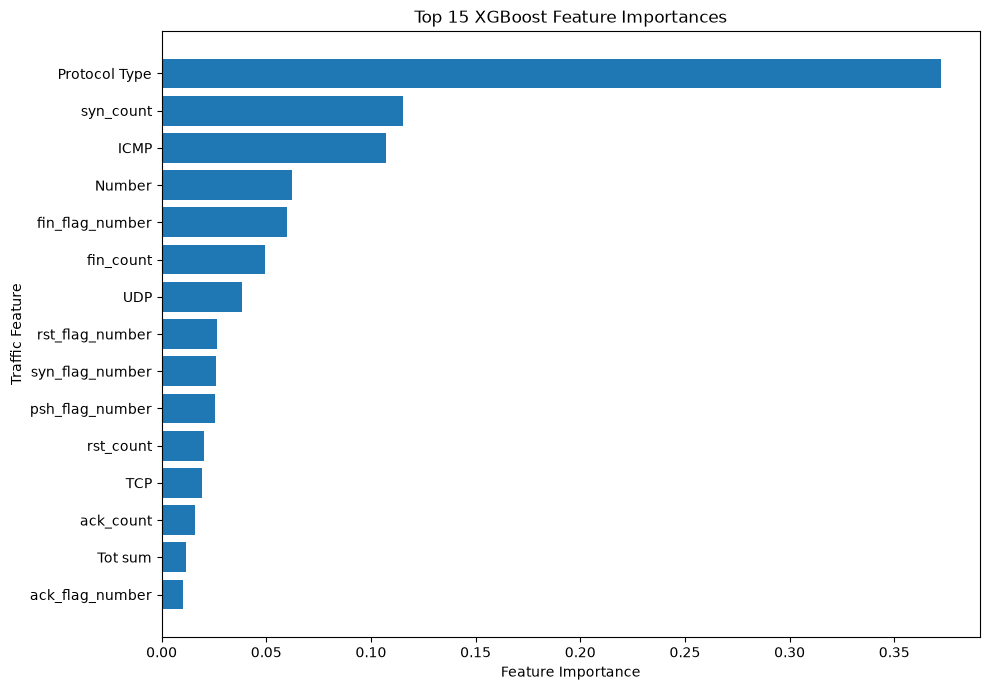

Feature importance graph saved successfully!


In [119]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Traffic Feature")
plt.title("Top 15 XGBoost Feature Importances")
plt.tight_layout()

plt.savefig(
    "../results/figures/xgboost_top15_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance graph saved successfully!")

In [120]:
import os

graph_path = "../results/figures/xgboost_top15_feature_importance.png"

print("Graph exists:", os.path.exists(graph_path))
print("Full path:", os.path.abspath(graph_path))

Graph exists: True
Full path: c:\Users\pranu1234\Documents\IoT-IDS\results\figures\xgboost_top15_feature_importance.png


## Results and Discussion

### 1. Model Performance

The IoT intrusion detection experiments were conducted using the CICIoT2023 dataset. A CNN-LSTM-Attention model and an XGBoost classifier were evaluated during the experiments.

The XGBoost classifier achieved a validation accuracy of **78.66%**, a Macro F1-score of **0.6023**, and a Weighted F1-score of **0.7743**. These results indicate that the model performed reasonably well overall, although its performance varied across attack classes.

### 2. Comparison of Models

The CNN-LSTM-Attention model achieved 77.48% accuracy, a Macro F1-score of 0.5619, and a Weighted F1-score of 0.7531 on the selected consecutive-sequence validation subset. XGBoost achieved 78.66% accuracy, a Macro F1-score of 0.6023, and a Weighted F1-score of 0.7743 on the full validation set.

Because these metrics were calculated on different validation subsets and the models use different input representations, this comparison is preliminary and does not establish a definitive performance advantage.

### 3. Feature Importance Analysis

The XGBoost feature-importance analysis identified `Protocol Type` as the most important feature, followed by `syn_count`, `ICMP`, `Number`, and `fin_flag_number`.

Removing `Protocol Type` resulted in 78.66% validation accuracy, a Macro F1-score of 0.6013, and a Weighted F1-score of 0.7742. The small change in these metrics suggests that the remaining features may provide overlapping predictive information.

### 4. Challenges in Rare Attack Detection

The model showed weak performance for several rare attack classes, including BACKDOOR_MALWARE, BROWSERHIJACKING, and UPLOADING_ATTACK. These classes had very few validation samples, making their class-specific evaluation metrics unstable.

Some DoS and reconnaissance attacks also had relatively low F1-scores. This indicates that overall accuracy alone is insufficient to assess intrusion detection performance, and class-wise precision, recall, and F1-score should also be considered.

### 5. Limitations and Future Work

The experiments have several limitations. The dataset contains highly imbalanced attack classes, and the current validation results should not be interpreted as final independent test performance. The CNN-LSTM-Attention and XGBoost models also use different input representations.

Future work should include a consistent evaluation protocol, independent final testing, improved detection of rare attacks, SHAP-based explanations, and integration of the selected model into the web application.

In [122]:
variables_to_check = [
    "X_train_raw",
    "X_test_raw",
    "y_train_raw",
    "y_test_raw",
    "X_train_part",
    "X_val",
    "y_train_part",
    "y_val"
]

for name in variables_to_check:
    if name in globals():
        value = globals()[name]
        print(f"{name}: available, shape = {getattr(value, 'shape', 'N/A')}")
    else:
        print(f"{name}: not available")

X_train_raw: available, shape = (569848, 39)
X_test_raw: available, shape = (142463, 39)
y_train_raw: available, shape = (569848,)
y_test_raw: available, shape = (142463,)
X_train_part: available, shape = (484370, 39)
X_val: available, shape = (85478, 39)
y_train_part: available, shape = (484370,)
y_val: available, shape = (85478,)


In [123]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

xgb_tuned = XGBClassifier(
    n_estimators=400,
    max_depth=12,
    learning_rate=0.03,
    min_child_weight=2,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_tuned.fit(X_train_part, y_train_part)

val_preds_tuned = xgb_tuned.predict(X_val)

print("Tuned XGBoost Validation Accuracy:",
      round(accuracy_score(y_val, val_preds_tuned) * 100, 2), "%")

print("Macro F1:",
      round(f1_score(y_val, val_preds_tuned, average="macro"), 4))

print("Weighted F1:",
      round(f1_score(y_val, val_preds_tuned, average="weighted"), 4))

Tuned XGBoost Validation Accuracy: 78.58 %
Macro F1: 0.6021
Weighted F1: 0.7739


In [124]:
import pandas as pd

feature_stats = pd.DataFrame({
    "Feature": X_train_part.columns,
    "Unique_Values": X_train_part.nunique().values,
    "Std_Deviation": X_train_part.std().values
})

display(
    feature_stats.sort_values(
        "Unique_Values",
        ascending=True
    ).head(15)
)

,Feature,Unique_Values,Std_Deviation
1,Protocol Type,5,9.085812
18,Telnet,5,0.000740
21,IRC,5,0.000930
10,cwr_flag_number,6,0.001248
27,IGMP,6,0.001301
19,SMTP,6,0.000856
9,ece_flag_number,11,0.001670
20,SSH,16,0.007070
24,DHCP,22,0.004857
13,fin_count,86,27.999814


In [125]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

low_variation_features = [
    "Telnet", "IRC", "cwr_flag_number",
    "IGMP", "SMTP", "ece_flag_number"
]

X_train_selected = X_train_part.drop(
    columns=low_variation_features
)
X_val_selected = X_val.drop(
    columns=low_variation_features
)

xgb_selected = XGBClassifier(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_selected.fit(X_train_selected, y_train_part)
selected_preds = xgb_selected.predict(X_val_selected)

print(
    "Selected-feature accuracy:",
    round(accuracy_score(y_val, selected_preds) * 100, 2), "%"
)
print(
    "Macro F1:",
    round(f1_score(y_val, selected_preds, average="macro"), 4)
)
print(
    "Weighted F1:",
    round(f1_score(y_val, selected_preds, average="weighted"), 4)
)

Selected-feature accuracy: 78.62 %
Macro F1: 0.5973
Weighted F1: 0.7737


In [126]:
try:
    import lightgbm
    print("LightGBM version:", lightgbm.__version__)
except ImportError:
    print("LightGBM is not installed.")

LightGBM version: 4.7.0


In [127]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [129]:
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)
print("Training data shape:", X_train_part.shape)
print("Validation data shape:", X_val.shape)
print("Number of classes:", len(set(y_train_part)))

LightGBM version: 4.7.0
Training data shape: (484370, 39)
Validation data shape: (85478, 39)
Number of classes: 34


In [130]:
import lightgbm as lgb
from sklearn.metrics import accuracy_score, f1_score

lgb_model = lgb.LGBMClassifier(
    objective="multiclass",
    num_class=34,
    n_estimators=500,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=63,
    min_child_samples=30,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(X_train_part, y_train_part)

lgb_preds = lgb_model.predict(X_val)

print(
    "LightGBM Validation Accuracy:",
    round(accuracy_score(y_val, lgb_preds) * 100, 2), "%"
)
print(
    "Macro F1:",
    round(f1_score(y_val, lgb_preds, average="macro"), 4)
)
print(
    "Weighted F1:",
    round(f1_score(y_val, lgb_preds, average="weighted"), 4)
)

LightGBM Validation Accuracy: 22.66 %
Macro F1: 0.1231
Weighted F1: 0.2019


In [131]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

print("Training label counts:")
print(pd.Series(y_train_part).value_counts().sort_index())

print("\nLightGBM predicted class counts:")
print(pd.Series(lgb_preds).value_counts().sort_index())

print("\nNumber of predicted classes:", len(np.unique(lgb_preds)))
print("Number of actual validation classes:", len(np.unique(y_val)))

print("\nFirst 20 predictions:", np.asarray(lgb_preds)[:20])
print("First 20 actual labels:", np.asarray(y_val)[:20])

Training label counts:
0        27
1     11312
2        55
3        48
4      2932
5       275
6     73712
7      4659
8     42354
9     41906
10      246
11    37009
12    41722
13    46511
14    55800
15     2926
16      136
17     1857
18      752
19    20900
20    27526
21    34314
22    10320
23     7600
24     9052
25     3130
26     1374
27      989
28       22
29      871
30       51
31       11
32     3929
33       42
Name: count, dtype: int64

LightGBM predicted class counts:
1       509
4         2
6       993
7       555
8      7013
9      3307
10        1
11    26531
12      231
13    36440
14     3285
15       66
17       19
19      210
20        3
21      915
22     1236
23     1066
24     3039
25       46
32       11
Name: count, dtype: int64

Number of predicted classes: 21
Number of actual validation classes: 34

First 20 predictions: [13 13 13 11 11 14 13 13 11 24 13 13 11  8 14 13 11 13  9 13]
First 20 actual labels: [ 9 13 12 14  6 21 20 11 14 24 13 20 21 23 14 12 

In [132]:
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

xgb_preds = xgb_val_model.predict(X_val)

print("Validation accuracy:",
      round(accuracy_score(y_val, xgb_preds) * 100, 2), "%")

print("\nActual vs Predicted class counts:")
comparison = pd.DataFrame({
    "Actual": pd.Series(y_val).value_counts(),
    "Predicted": pd.Series(xgb_preds).value_counts()
}).fillna(0).astype(int)

display(comparison.sort_values("Actual"))

print("\nClassification report:")
print(classification_report(
    y_val, xgb_preds, zero_division=0
))

Validation accuracy: 78.66 %

Actual vs Predicted class counts:


,Actual,Predicted
31,2,0
28,4,0
0,5,0
3,8,2
33,8,0
30,9,2
2,10,0
16,24,9
10,43,56
5,49,39



Classification report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         5
           1       0.77      0.91      0.84      1996
           2       0.00      0.00      0.00        10
           3       1.00      0.25      0.40         8
           4       0.98      0.98      0.98       517
           5       0.77      0.61      0.68        49
           6       1.00      1.00      1.00     13008
           7       0.99      0.98      0.99       822
           8       1.00      1.00      1.00      7474
           9       1.00      1.00      1.00      7395
          10       0.68      0.88      0.77        43
          11       0.46      0.73      0.57      6531
          12       0.53      0.42      0.47      7363
          13       0.69      0.86      0.77      8208
          14       0.74      0.93      0.83      9847
          15       0.98      0.99      0.99       516
          16       0.78      0.29      0.42        24
   

In [133]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

classes = np.unique(y_train_part)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_part
)

# Moderate weights: square root of balanced weights
weight_map = {
    cls: np.sqrt(weight)
    for cls, weight in zip(classes, class_weights)
}

sample_weights = np.array([
    weight_map[label] for label in y_train_part
])

xgb_sqrt = XGBClassifier(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_sqrt.fit(
    X_train_part,
    y_train_part,
    sample_weight=sample_weights
)

preds_sqrt = xgb_sqrt.predict(X_val)

print(
    "Square-root weighted XGBoost accuracy:",
    round(accuracy_score(y_val, preds_sqrt) * 100, 2), "%"
)
print(
    "Macro F1:",
    round(f1_score(y_val, preds_sqrt, average="macro"), 4)
)
print(
    "Weighted F1:",
    round(f1_score(y_val, preds_sqrt, average="weighted"), 4)
)

Square-root weighted XGBoost accuracy: 78.13 %
Macro F1: 0.6086
Weighted F1: 0.7767


In [134]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

xgb_early = XGBClassifier(
    n_estimators=800,
    max_depth=8,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="multi:softprob",
    num_class=34,
    eval_metric="mlogloss",
    early_stopping_rounds=30,
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_early.fit(
    X_train_part,
    y_train_part,
    eval_set=[(X_val, y_val)],
    verbose=50
)

preds_early = xgb_early.predict(X_val)

print("Best iteration:", xgb_early.best_iteration)
print(
    "Early-stopped XGBoost accuracy:",
    round(accuracy_score(y_val, preds_early) * 100, 2), "%"
)
print("Macro F1:", round(f1_score(y_val, preds_early, average="macro"), 4))
print("Weighted F1:", round(f1_score(y_val, preds_early, average="weighted"), 4))

[0]	validation_0-mlogloss:2.44387
[50]	validation_0-mlogloss:0.80469
[100]	validation_0-mlogloss:0.53859
[150]	validation_0-mlogloss:0.46342
[200]	validation_0-mlogloss:0.43746
[250]	validation_0-mlogloss:0.42694
[300]	validation_0-mlogloss:0.42224
[350]	validation_0-mlogloss:0.41989
[400]	validation_0-mlogloss:0.41878
[450]	validation_0-mlogloss:0.41823
[500]	validation_0-mlogloss:0.41791
[550]	validation_0-mlogloss:0.41782
[591]	validation_0-mlogloss:0.41784
Best iteration: 561
Early-stopped XGBoost accuracy: 78.69 %
Macro F1: 0.602
Weighted F1: 0.7742


In [135]:
import pandas as pd
import numpy as np

print("Training rows:", len(X_train_part))
print("Validation rows:", len(X_val))

print("\nDuplicate rows in training features:",
      X_train_part.duplicated().sum())

print("Duplicate rows in validation features:",
      X_val.duplicated().sum())

train_counts = pd.Series(y_train_part).value_counts(normalize=True).sort_index()
val_counts = pd.Series(y_val).value_counts(normalize=True).sort_index()

distribution = pd.DataFrame({
    "Train proportion": train_counts,
    "Validation proportion": val_counts
}).fillna(0)

distribution["Absolute difference"] = (
    distribution["Train proportion"] - distribution["Validation proportion"]
).abs()

display(distribution.sort_values(
    "Absolute difference", ascending=False
).head(10))

Training rows: 484370
Validation rows: 85478

Duplicate rows in training features: 112721
Duplicate rows in validation features: 6885


,Train proportion,Validation proportion,Absolute difference
32,0.008112,0.008119,0.000007
33,0.000087,0.000094,0.000007
24,0.018688,0.018695,0.000007
27,0.002042,0.002036,0.000006
26,0.002837,0.002843,0.000006
21,0.070843,0.070837,0.000006
3,0.000099,0.000094,0.000006
5,0.000568,0.000573,0.000005
4,0.006053,0.006048,0.000005
20,0.056828,0.056833,0.000005


In [136]:
import pandas as pd

train_check = X_train_part.copy()
train_check["_label"] = pd.Series(
    y_train_part, index=X_train_part.index
)

val_check = X_val.copy()
val_check["_label"] = pd.Series(
    y_val, index=X_val.index
)

train_unique = train_check.drop_duplicates(
    subset=list(X_train_part.columns)
)
val_unique = val_check.drop_duplicates(
    subset=list(X_val.columns)
)

train_label_conflicts = (
    train_check.groupby(list(X_train_part.columns))["_label"]
    .nunique()
    .gt(1)
    .sum()
)

val_label_conflicts = (
    val_check.groupby(list(X_val.columns))["_label"]
    .nunique()
    .gt(1)
    .sum()
)

print("Training feature groups with conflicting labels:",
      train_label_conflicts)
print("Validation feature groups with conflicting labels:",
      val_label_conflicts)

train_keys = train_check.drop(columns="_label").merge(
    val_check.drop(columns="_label"),
    how="inner"
)

print("Exact feature-row matches across train and validation:",
      len(train_keys.drop_duplicates()))

Training feature groups with conflicting labels: 16241
Validation feature groups with conflicting labels: 1596
Exact feature-row matches across train and validation: 22753


In [137]:
import pandas as pd

train_check = X_train_part.copy()
train_check["_label"] = pd.Series(
    y_train_part, index=X_train_part.index
)

# Find feature rows associated with more than one label
label_conflicts = (
    train_check.groupby(list(X_train_part.columns))["_label"]
    .agg(["size", "nunique"])
    .query("nunique > 1")
)

print("Conflicting feature groups:", len(label_conflicts))
print("\nExamples of conflicting groups:")

example_features = label_conflicts.head(5).index

for feature_values in example_features:
    mask = X_train_part.eq(
        pd.Series(feature_values, index=X_train_part.columns)
    ).all(axis=1)

    print("\nFeature row:")
    print(pd.Series(feature_values, index=X_train_part.columns).to_dict())
    print("Labels and counts:")
    print(train_check.loc[mask, "_label"].value_counts().to_dict())

Conflicting feature groups: 16241

Examples of conflicting groups:

Feature row:
{'Header_Length': 7.76, 'Protocol Type': 17.0, 'Time_To_Live': 67.18, 'Rate': 15747.93121573928, 'fin_flag_number': 0.0, 'syn_flag_number': 0.0, 'rst_flag_number': 0.0, 'psh_flag_number': 0.0, 'ack_flag_number': 0.0, 'ece_flag_number': 0.0, 'cwr_flag_number': 0.0, 'ack_count': 0.0, 'syn_count': 0.0, 'fin_count': 0.0, 'rst_count': 0.0, 'HTTP': 0.0, 'HTTPS': 0.0, 'DNS': 0.0, 'Telnet': 0.0, 'SMTP': 0.0, 'SSH': 0.0, 'IRC': 0.0, 'TCP': 0.0, 'UDP': 0.97, 'DHCP': 0.0, 'ARP': 0.01, 'ICMP': 0.02, 'IGMP': 0.0, 'IPv': 0.99, 'LLC': 0.99, 'Tot sum': 6020.0, 'Min': 60.0, 'Max': 70.0, 'AVG': 60.2, 'Std': 1.4070529413628965, 'Tot size': 60.2, 'IAT': 6.350994110107422e-05, 'Number': 100.0, 'Variance': 1.979797979797978}
Labels and counts:
{21: 1, 14: 1}

Feature row:
{'Header_Length': 7.92, 'Protocol Type': 17.0, 'Time_To_Live': 63.36, 'Rate': 10933.771278121008, 'fin_flag_number': 0.0, 'syn_flag_number': 0.0, 'rst_flag_nu

In [138]:
import pandas as pd

# Create a stable, exact feature-row grouping
check_df = X_train_part.copy()
check_df["_label"] = pd.Series(
    y_train_part, index=X_train_part.index
)

group_sizes = (
    check_df.groupby(list(X_train_part.columns), dropna=False)["_label"]
    .agg(["size", "nunique"])
)

print("Exact feature groups:", len(group_sizes))
print("Groups with multiple labels:",
      int((group_sizes["nunique"] > 1).sum()))

# Show one verified conflicting group, if present
conflict_keys = group_sizes[group_sizes["nunique"] > 1].head(1).index

if len(conflict_keys):
    key = conflict_keys[0]
    mask = X_train_part.eq(
        pd.Series(key, index=X_train_part.columns)
    ).all(axis=1)

    print("\nExact feature values:")
    print(pd.Series(key, index=X_train_part.columns).to_dict())
    print("Labels for this exact row:")
    print(check_df.loc[mask, "_label"].value_counts().to_dict())
else:
    print("No exact feature groups with conflicting labels found.")

Exact feature groups: 371649
Groups with multiple labels: 16241

Exact feature values:
{'Header_Length': 7.76, 'Protocol Type': 17.0, 'Time_To_Live': 67.18, 'Rate': 15747.93121573928, 'fin_flag_number': 0.0, 'syn_flag_number': 0.0, 'rst_flag_number': 0.0, 'psh_flag_number': 0.0, 'ack_flag_number': 0.0, 'ece_flag_number': 0.0, 'cwr_flag_number': 0.0, 'ack_count': 0.0, 'syn_count': 0.0, 'fin_count': 0.0, 'rst_count': 0.0, 'HTTP': 0.0, 'HTTPS': 0.0, 'DNS': 0.0, 'Telnet': 0.0, 'SMTP': 0.0, 'SSH': 0.0, 'IRC': 0.0, 'TCP': 0.0, 'UDP': 0.97, 'DHCP': 0.0, 'ARP': 0.01, 'ICMP': 0.02, 'IGMP': 0.0, 'IPv': 0.99, 'LLC': 0.99, 'Tot sum': 6020.0, 'Min': 60.0, 'Max': 70.0, 'AVG': 60.2, 'Std': 1.4070529413628965, 'Tot size': 60.2, 'IAT': 6.350994110107422e-05, 'Number': 100.0, 'Variance': 1.979797979797978}
Labels for this exact row:
{21: 1, 14: 1}


In [139]:
print("category_mapping exists:", "category_mapping" in globals())
print("y_train_raw available:", "y_train_raw" in globals())
print("y_val available:", "y_val" in globals())

if "category_mapping" in globals():
    print("Mapping entries:", len(category_mapping))
    print(category_mapping)

category_mapping exists: False
y_train_raw available: True
y_val available: True


In [140]:
print("Label encoder available:", "label_encoder" in globals())
print("Number of original classes:", len(label_encoder.classes_))

for i, label in enumerate(label_encoder.classes_):
    print(i, "->", label)

Label encoder available: True
Number of original classes: 34
0 -> BACKDOOR_MALWARE
1 -> BENIGN
2 -> BROWSERHIJACKING
3 -> COMMANDINJECTION
4 -> DDOS-ACK_FRAGMENTATION
5 -> DDOS-HTTP_FLOOD
6 -> DDOS-ICMP_FLOOD
7 -> DDOS-ICMP_FRAGMENTATION
8 -> DDOS-PSHACK_FLOOD
9 -> DDOS-RSTFINFLOOD
10 -> DDOS-SLOWLORIS
11 -> DDOS-SYNONYMOUSIP_FLOOD
12 -> DDOS-SYN_FLOOD
13 -> DDOS-TCP_FLOOD
14 -> DDOS-UDP_FLOOD
15 -> DDOS-UDP_FRAGMENTATION
16 -> DICTIONARYBRUTEFORCE
17 -> DNS_SPOOFING
18 -> DOS-HTTP_FLOOD
19 -> DOS-SYN_FLOOD
20 -> DOS-TCP_FLOOD
21 -> DOS-UDP_FLOOD
22 -> MIRAI-GREETH_FLOOD
23 -> MIRAI-GREIP_FLOOD
24 -> MIRAI-UDPPLAIN
25 -> MITM-ARPSPOOFING
26 -> RECON-HOSTDISCOVERY
27 -> RECON-OSSCAN
28 -> RECON-PINGSWEEP
29 -> RECON-PORTSCAN
30 -> SQLINJECTION
31 -> UPLOADING_ATTACK
32 -> VULNERABILITYSCAN
33 -> XSS


In [141]:
# Map the 34 fine-grained labels into 8 broad attack categories

def map_attack(label):
    label = str(label).upper()

    if label == "BENIGN":
        return "BENIGN"
    elif "BRUTEFORCE" in label:
        return "Brute Force"
    elif label.startswith("DDOS-"):
        return "DDoS"
    elif label.startswith("DOS-"):
        return "DoS"
    elif label.startswith("MIRAI-"):
        return "Mirai"
    elif "SPOOFING" in label or "ARPSPOOFING" in label:
        return "Spoofing"
    elif "RECON" in label or "VULNERABILITYSCAN" in label:
        return "Recon"
    else:
        return "Web-based"


# Convert encoded labels back to original class names
y_train_names = label_encoder.inverse_transform(
    np.asarray(y_train_part, dtype=int)
)
y_val_names = label_encoder.inverse_transform(
    np.asarray(y_val, dtype=int)
)

# Create broad-category labels
y_train_broad = pd.Series(y_train_names).map(map_attack)
y_val_broad = pd.Series(y_val_names).map(map_attack)

print("Broad training classes:")
print(y_train_broad.value_counts())

print("\nBroad validation classes:")
print(y_val_broad.value_counts())

print("\nNumber of broad classes:", y_train_broad.nunique())

Broad training classes:
DDoS           350052
DoS             83492
Mirai           26972
BENIGN          11312
Recon            7185
Spoofing         4987
Web-based         234
Brute Force       136
Name: count, dtype: int64

Broad validation classes:
DDoS           61773
DoS            14734
Mirai           4760
BENIGN          1996
Recon           1269
Spoofing         880
Web-based         42
Brute Force       24
Name: count, dtype: int64

Number of broad classes: 8


In [142]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Convert broad category names into numeric labels
broad_encoder = LabelEncoder()

y_train_broad_encoded = broad_encoder.fit_transform(y_train_broad)
y_val_broad_encoded = broad_encoder.transform(y_val_broad)

print("Broad classes:", list(broad_encoder.classes_))

# Train XGBoost on the existing training/validation split
xgb_broad_model = XGBClassifier(
    n_estimators=600,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(broad_encoder.classes_),
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_broad_model.fit(
    X_train_part,
    y_train_broad_encoded,
    verbose=False
)

broad_preds = xgb_broad_model.predict(X_val)

print("\nBroad-category validation accuracy:",
      round(accuracy_score(y_val_broad_encoded, broad_preds) * 100, 2), "%")

print("Macro F1:",
      round(f1_score(y_val_broad_encoded, broad_preds, average="macro"), 4))

print("Weighted F1:",
      round(f1_score(y_val_broad_encoded, broad_preds, average="weighted"), 4))

print("\nClassification report:")
print(classification_report(
    y_val_broad_encoded,
    broad_preds,
    labels=list(range(len(broad_encoder.classes_))),
    target_names=broad_encoder.classes_,
    zero_division=0
))

Broad classes: ['BENIGN', 'Brute Force', 'DDoS', 'DoS', 'Mirai', 'Recon', 'Spoofing', 'Web-based']

Broad-category validation accuracy: 85.62 %
Macro F1: 0.6686
Weighted F1: 0.838

Classification report:
              precision    recall  f1-score   support

      BENIGN       0.80      0.86      0.83      1996
 Brute Force       0.75      0.25      0.38        24
        DDoS       0.86      0.97      0.91     61773
         DoS       0.72      0.37      0.48     14734
       Mirai       1.00      1.00      1.00      4760
       Recon       0.75      0.74      0.74      1269
    Spoofing       0.93      0.85      0.89       880
   Web-based       0.38      0.07      0.12        42

    accuracy                           0.86     85478
   macro avg       0.77      0.64      0.67     85478
weighted avg       0.84      0.86      0.84     85478



In [143]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    xgb_broad_model,
    "../models/xgboost_broad_8class.pkl"
)

joblib.dump(
    broad_encoder,
    "../models/broad_label_encoder.pkl"
)

print("8-category XGBoost model saved.")
print("Label encoder saved.")

8-category XGBoost model saved.
Label encoder saved.


In [144]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np
import pandas as pd

# Test labels are already original class names
y_test_broad = pd.Series(y_test_raw).map(map_attack)

# Encode using the same encoder used for training
y_test_broad_encoded = broad_encoder.transform(y_test_broad)

# Predict on the held-out test set
test_preds_broad = xgb_broad_model.predict(X_test_raw)

print(
    "8-category TEST accuracy:",
    round(accuracy_score(y_test_broad_encoded, test_preds_broad) * 100, 2),
    "%"
)

print("Macro F1:", round(
    f1_score(y_test_broad_encoded, test_preds_broad, average="macro"), 4
))

print("Weighted F1:", round(
    f1_score(y_test_broad_encoded, test_preds_broad, average="weighted"), 4
))

print("\nClassification report:")
print(classification_report(
    y_test_broad_encoded,
    test_preds_broad,
    labels=np.arange(len(broad_encoder.classes_)),
    target_names=broad_encoder.classes_,
    zero_division=0
))

8-category TEST accuracy: 85.84 %
Macro F1: 0.6724
Weighted F1: 0.841

Classification report:
              precision    recall  f1-score   support

      BENIGN       0.81      0.87      0.84      3269
 Brute Force       0.90      0.20      0.33        44
        DDoS       0.87      0.96      0.91    103295
         DoS       0.71      0.37      0.49     24269
       Mirai       1.00      1.00      1.00      7932
       Recon       0.76      0.76      0.76      2108
    Spoofing       0.94      0.84      0.89      1461
   Web-based       0.47      0.09      0.16        85

    accuracy                           0.86    142463
   macro avg       0.81      0.64      0.67    142463
weighted avg       0.85      0.86      0.84    142463



In [153]:
import os
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

os.makedirs("../results/metrics", exist_ok=True)

results = pd.DataFrame([
    {
        "Model": "XGBoost - 8 Broad Categories",
        "Split": "Validation",
        "Accuracy": 0.8562,
        "Macro_F1": 0.6686,
        "Weighted_F1": 0.8380
    },
    {
        "Model": "XGBoost - 8 Broad Categories",
        "Split": "Test",
        "Accuracy": accuracy_score(
            y_test_broad_encoded, test_preds_broad
        ),
        "Macro_F1": f1_score(
            y_test_broad_encoded, test_preds_broad, average="macro"
        ),
        "Weighted_F1": f1_score(
            y_test_broad_encoded, test_preds_broad, average="weighted"
        )
    }
])

results.to_csv(
    "../results/metrics/xgboost_broad_8class_results.csv",
    index=False
)

display(results)
print("Results saved successfully!")

,Model,Split,Accuracy,Macro_F1,Weighted_F1
0,XGBoost - 8 Broad Categories,Validation,0.85620,0.668600,0.838000
1,XGBoost - 8 Broad Categories,Test,0.85844,0.672368,0.840967


Results saved successfully!


In [155]:
import pandas as pd
import requests

df = pd.read_csv(
    "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv",
    nrows=20
)

for i in range(20):
    row = df.drop(columns=["Label"]).iloc[i].astype(float).tolist()

    response = requests.post(
        "http://127.0.0.1:5000/predict_broad",
        json={"records": row}
    )

    result = response.json()

    print(
        f"Row {i} | Actual: {df['Label'].iloc[i]} "
        f"| Status: {response.status_code} "
        f"| Predicted: {result.get('predicted_category', 'ERROR')}"
    )

Row 0 | Actual: DDOS-PSHACK_FLOOD | Status: 200 | Predicted: DDoS
Row 1 | Actual: MIRAI-GREIP_FLOOD | Status: 200 | Predicted: Mirai
Row 2 | Actual: DOS-UDP_FLOOD | Status: 200 | Predicted: DoS
Row 3 | Actual: DNS_SPOOFING | Status: 200 | Predicted: Spoofing
Row 4 | Actual: DDOS-ICMP_FLOOD | Status: 200 | Predicted: DDoS
Row 5 | Actual: DDOS-TCP_FLOOD | Status: 200 | Predicted: DDoS
Row 6 | Actual: DDOS-PSHACK_FLOOD | Status: 200 | Predicted: DDoS
Row 7 | Actual: DDOS-SYN_FLOOD | Status: 200 | Predicted: DDoS
Row 8 | Actual: DDOS-UDP_FLOOD | Status: 200 | Predicted: DDoS
Row 9 | Actual: MITM-ARPSPOOFING | Status: 200 | Predicted: Spoofing
Row 10 | Actual: DDOS-PSHACK_FLOOD | Status: 200 | Predicted: DDoS
Row 11 | Actual: DDOS-SYNONYMOUSIP_FLOOD | Status: 200 | Predicted: DDoS
Row 12 | Actual: DDOS-ICMP_FLOOD | Status: 200 | Predicted: DDoS
Row 13 | Actual: DDOS-UDP_FLOOD | Status: 200 | Predicted: DDoS
Row 14 | Actual: DDOS-SYN_FLOOD | Status: 200 | Predicted: DDoS
Row 15 | Actual: DOS

In [156]:
import pandas as pd
import numpy as np
import requests
from sklearn.metrics import accuracy_score

# Load 500 rows from the held-out test dataset
df_test = pd.read_csv(
    "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"
)

# Use the existing test split's last 20% of rows
test_df = df_test.iloc[int(len(df_test) * 0.8):].head(500).copy()

def map_broad(label):
    label = str(label).upper()

    if label == "BENIGN":
        return "BENIGN"
    if "DICTIONARYBRUTEFORCE" in label:
        return "Brute Force"
    if label.startswith("DDOS-"):
        return "DDoS"
    if label.startswith("DOS-"):
        return "DoS"
    if label.startswith("MIRAI-"):
        return "Mirai"
    if any(x in label for x in ["SPOOF", "MITM"]):
        return "Spoofing"
    if any(x in label for x in ["RECON", "VULNERABILITYSCAN"]):
        return "Recon"
    return "Web-based"

session = requests.Session()
actual = []
predicted = []

for _, row in test_df.iterrows():
    features = row.drop("Label").astype(float).tolist()

    response = session.post(
        "http://127.0.0.1:5000/predict_broad",
        json={"records": features}
    )

    if response.status_code == 200:
        actual.append(map_broad(row["Label"]))
        predicted.append(response.json()["predicted_category"])
    else:
        print("API error:", response.status_code, response.text)
        break

if len(actual) == len(test_df):
    print("API test samples:", len(actual))
    print("API test accuracy:", round(
        accuracy_score(actual, predicted) * 100, 2
    ), "%")
else:
    print("Test incomplete. Successful predictions:", len(actual))

API test samples: 500
API test accuracy: 83.8 %


In [161]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Load the complete dataset
df_all = pd.read_csv(
    "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"
)

# Recreate the same final 20% row split
test_df_full = df_all.iloc[int(len(df_all) * 0.8):].copy()

def map_broad(label):
    label = str(label).upper()

    if label == "BENIGN":
        return "BENIGN"
    if "DICTIONARYBRUTEFORCE" in label:
        return "Brute Force"
    if label.startswith("DDOS-"):
        return "DDoS"
    if label.startswith("DOS-"):
        return "DoS"
    if label.startswith("MIRAI-"):
        return "Mirai"
    if "SPOOF" in label or "MITM" in label:
        return "Spoofing"
    if "RECON" in label or "VULNERABILITYSCAN" in label:
        return "Recon"
    return "Web-based"

# Use the trained 8-category model directly for full evaluation
X_full = test_df_full.drop(columns=["Label"])
y_full = test_df_full["Label"].map(map_broad)

y_pred_ids = broad_model.predict(X_full)
y_pred = broad_encoder.inverse_transform(y_pred_ids.astype(int))

print("Test samples:", len(test_df_full))
print("Full test accuracy:", round(accuracy_score(y_full, y_pred) * 100, 2), "%")
print(classification_report(y_full, y_pred, zero_division=0))

Test samples: 142463
Full test accuracy: 85.84 %
              precision    recall  f1-score   support

      BENIGN       0.81      0.87      0.84      3269
 Brute Force       0.90      0.20      0.33        44
        DDoS       0.87      0.96      0.91    103295
         DoS       0.71      0.37      0.49     24269
       Mirai       1.00      1.00      1.00      7932
       Recon       0.76      0.76      0.76      2108
    Spoofing       0.94      0.84      0.89      1461
   Web-based       0.47      0.09      0.16        85

    accuracy                           0.86    142463
   macro avg       0.81      0.64      0.67    142463
weighted avg       0.85      0.86      0.84    142463



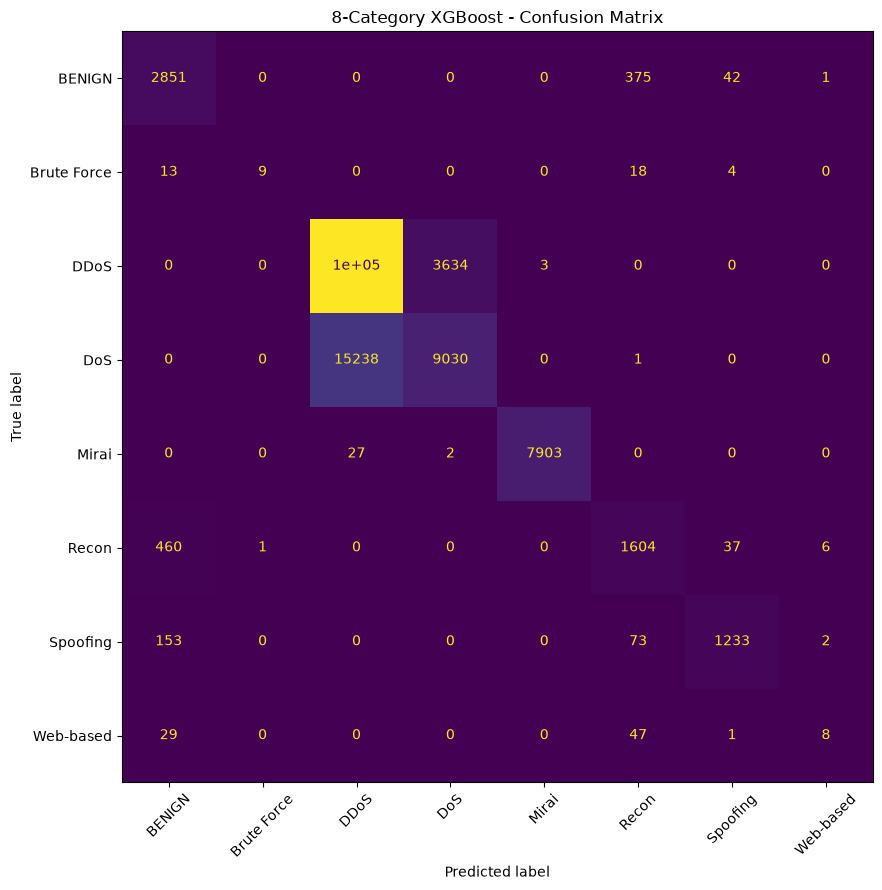

Confusion matrix saved successfully.


In [162]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = list(broad_encoder.classes_)

cm = confusion_matrix(y_full, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(11, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("8-Category XGBoost - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "../results/figures/xgboost_8class_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Confusion matrix saved successfully.")

In [163]:
from sklearn.metrics import classification_report

print(classification_report(
    y_full,
    y_pred,
    labels=list(broad_encoder.classes_),
    zero_division=0
))

print("Baseline accuracy:", round(
    accuracy_score(y_full, y_pred) * 100, 2
), "%")

              precision    recall  f1-score   support

      BENIGN       0.81      0.87      0.84      3269
 Brute Force       0.90      0.20      0.33        44
        DDoS       0.87      0.96      0.91    103295
         DoS       0.71      0.37      0.49     24269
       Mirai       1.00      1.00      1.00      7932
       Recon       0.76      0.76      0.76      2108
    Spoofing       0.94      0.84      0.89      1461
   Web-based       0.47      0.09      0.16        85

    accuracy                           0.86    142463
   macro avg       0.81      0.64      0.67    142463
weighted avg       0.85      0.86      0.84    142463

Baseline accuracy: 85.84 %


In [164]:
import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

# Give DoS more weight while preserving other classes
sample_weights = compute_sample_weight(
    class_weight={
        "BENIGN": 1.0,
        "Brute Force": 2.0,
        "DDoS": 1.0,
        "DoS": 2.0,
        "Mirai": 1.0,
        "Recon": 1.0,
        "Spoofing": 1.0,
        "Web-based": 2.0
    },
    y=y_train_broad
)

dos_weight_model = XGBClassifier(
    n_estimators=350,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

dos_weight_model.fit(
    X_train_part,
    y_train_broad,
    sample_weight=sample_weights
)

weighted_preds = dos_weight_model.predict(X_val)
weighted_pred_labels = broad_encoder.inverse_transform(
    weighted_preds.astype(int)
)

print(
    "Weighted validation accuracy:",
    round(accuracy_score(y_val_broad, weighted_pred_labels) * 100, 2),
    "%"
)

print(classification_report(
    y_val_broad,
    weighted_pred_labels,
    zero_division=0
))

ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1 2 3 4 5 6 7], got ['BENIGN' 'Brute Force' 'DDoS' 'DoS' 'Mirai' 'Recon' 'Spoofing'
 'Web-based']

In [165]:
# Convert training and validation labels into broad categories

def map_broad(label):
    label = str(label).upper()

    if label == "BENIGN":
        return "BENIGN"
    elif "DICTIONARYBRUTEFORCE" in label:
        return "Brute Force"
    elif label.startswith("DDOS-"):
        return "DDoS"
    elif label.startswith("DOS-"):
        return "DoS"
    elif label.startswith("MIRAI-"):
        return "Mirai"
    elif "SPOOF" in label or "MITM" in label:
        return "Spoofing"
    elif "RECON" in label or "VULNERABILITYSCAN" in label:
        return "Recon"
    else:
        return "Web-based"


y_train_broad = pd.Series(y_train_raw).map(map_broad)
y_val_broad = pd.Series(y_val).map(map_broad)

print("Training labels:")
print(y_train_broad.value_counts())

print("\nValidation labels:")
print(y_val_broad.value_counts())

print("\nMissing training labels:", y_train_broad.isna().sum())
print("Missing validation labels:", y_val_broad.isna().sum())

Training labels:
Label
DDoS           411825
DoS             98226
Mirai           31732
BENIGN          13308
Recon            8454
Spoofing         5867
Web-based         276
Brute Force       160
Name: count, dtype: int64

Validation labels:
Web-based    85478
Name: count, dtype: int64

Missing training labels: 0
Missing validation labels: 0


In [166]:
import pandas as pd
import numpy as np

# Load original dataset labels
df_labels = pd.read_csv(
    "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv",
    usecols=["Label"]
)

# Recreate the original ordered 80/20 split
split_index = int(len(df_labels) * 0.8)

y_train_raw = df_labels["Label"].iloc[:split_index].reset_index(drop=True)
y_test_raw = df_labels["Label"].iloc[split_index:].reset_index(drop=True)

# Recreate the validation split used earlier
from sklearn.model_selection import train_test_split

train_indices = np.arange(len(y_train_raw))

train_idx, val_idx = train_test_split(
    train_indices,
    test_size=0.15,
    random_state=42,
    stratify=y_train_raw
)

y_train_part_raw = y_train_raw.iloc[train_idx].reset_index(drop=True)
y_val_raw = y_train_raw.iloc[val_idx].reset_index(drop=True)

print("Training labels:", len(y_train_part_raw))
print("Validation labels:", len(y_val_raw))
print("Test labels:", len(y_test_raw))

Training labels: 484370
Validation labels: 85478
Test labels: 142463


In [167]:
print("X_train_part shape:", X_train_part.shape)
print("Training labels:", len(y_train_part_raw))

print("X_val shape:", X_val.shape)
print("Validation labels:", len(y_val_raw))

print("\nTraining indices sample:", train_idx[:10])
print("Validation indices sample:", val_idx[:10])

print("\nTraining labels sample:")
print(y_train_part_raw.head(10).tolist())

print("\nValidation labels sample:")
print(y_val_raw.head(10).tolist())

X_train_part shape: (484370, 39)
Training labels: 484370
X_val shape: (85478, 39)
Validation labels: 85478

Training indices sample: [158717 401067 514888 306881  26898 274370 466716 468001 465441 390465]
Validation indices sample: [358997 152387  62010 357381 448010 217985 376695  77923 292888  51313]

Training labels sample:
['DDOS-TCP_FLOOD', 'DDOS-ICMP_FLOOD', 'DDOS-UDP_FLOOD', 'DOS-SYN_FLOOD', 'DOS-UDP_FLOOD', 'DDOS-ICMP_FLOOD', 'DOS-UDP_FLOOD', 'DDOS-RSTFINFLOOD', 'DDOS-SYNONYMOUSIP_FLOOD', 'DDOS-SYN_FLOOD']

Validation labels sample:
['DDOS-RSTFINFLOOD', 'DDOS-TCP_FLOOD', 'DDOS-SYN_FLOOD', 'DDOS-UDP_FLOOD', 'DDOS-ICMP_FLOOD', 'DOS-UDP_FLOOD', 'DOS-TCP_FLOOD', 'DDOS-SYNONYMOUSIP_FLOOD', 'DDOS-UDP_FLOOD', 'MIRAI-UDPPLAIN']


In [168]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Load features and labels in original row order
df = pd.read_csv(
    "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"
)

X_all = df.drop(columns=["Label"])
y_all = df["Label"]

# Original 80/20 split
split_index = int(len(df) * 0.8)

X_train_raw = X_all.iloc[:split_index].reset_index(drop=True)
X_test_raw = X_all.iloc[split_index:].reset_index(drop=True)

y_train_raw = y_all.iloc[:split_index].reset_index(drop=True)
y_test_raw = y_all.iloc[split_index:].reset_index(drop=True)

# Same 85/15 training-validation split
all_train_indices = np.arange(len(X_train_raw))

train_idx, val_idx = train_test_split(
    all_train_indices,
    test_size=0.15,
    random_state=42,
    stratify=y_train_raw
)

X_train_part = X_train_raw.iloc[train_idx].reset_index(drop=True)
X_val = X_train_raw.iloc[val_idx].reset_index(drop=True)

y_train_part_raw = y_train_raw.iloc[train_idx].reset_index(drop=True)
y_val_raw = y_train_raw.iloc[val_idx].reset_index(drop=True)

print("Training features:", X_train_part.shape)
print("Training labels:", y_train_part_raw.shape)
print("Validation features:", X_val.shape)
print("Validation labels:", y_val_raw.shape)
print("Test features:", X_test_raw.shape)
print("Test labels:", y_test_raw.shape)

Training features: (484370, 39)
Training labels: (484370,)
Validation features: (85478, 39)
Validation labels: (85478,)
Test features: (142463, 39)
Test labels: (142463,)


In [169]:
def map_broad(label):
    label = str(label).upper()

    if label == "BENIGN":
        return "BENIGN"
    elif "DICTIONARYBRUTEFORCE" in label:
        return "Brute Force"
    elif label.startswith("DDOS-"):
        return "DDoS"
    elif label.startswith("DOS-"):
        return "DoS"
    elif label.startswith("MIRAI-"):
        return "Mirai"
    elif "SPOOF" in label or "MITM" in label:
        return "Spoofing"
    elif "RECON" in label or "VULNERABILITYSCAN" in label:
        return "Recon"
    elif label in {
        "BROWSERHIJACKING",
        "BROWSERSHIJACKING",
        "SQLINJECTION",
        "COMMANDINJECTION",
        "XSS",
        "BACKDOOR_MALWARE",
        "UPLOADING_ATTACK"
    }:
        return "Web-based"
    else:
        return "UNMAPPED"

y_train_broad = y_train_part_raw.map(map_broad)
y_val_broad = y_val_raw.map(map_broad)

print("Training category counts:")
print(y_train_broad.value_counts())

print("\nValidation category counts:")
print(y_val_broad.value_counts())

print("\nMissing training mappings:", y_train_broad.isna().sum())
print("Missing validation mappings:", y_val_broad.isna().sum())

Training category counts:
Label
DDoS           350052
DoS             83492
Mirai           26972
BENIGN          11312
Recon            7185
Spoofing         4987
Web-based         234
Brute Force       136
Name: count, dtype: int64

Validation category counts:
Label
DDoS           61773
DoS            14734
Mirai           4760
BENIGN          1996
Recon           1269
Spoofing         880
Web-based         42
Brute Force       24
Name: count, dtype: int64

Missing training mappings: 0
Missing validation mappings: 0


In [170]:
print("Unmapped training labels:")
print(
    y_train_part_raw[
        y_train_part_raw.map(map_broad) == "UNMAPPED"
    ].value_counts().to_string()
)

print("\nUnmapped validation labels:")
print(
    y_val_raw[
        y_val_raw.map(map_broad) == "UNMAPPED"
    ].value_counts().to_string()
)

Unmapped training labels:
Series([], )

Unmapped validation labels:
Series([], )


In [171]:

import pandas as pd

label_check = pd.DataFrame({
    "Original Label": y_train_part_raw.astype(str),
    "Mapped Category": y_train_part_raw.map(map_broad)
})

web_labels = (
    label_check.loc[
        label_check["Mapped Category"] == "Web-based",
        "Original Label"
    ]
    .value_counts()
)

print("Original labels mapped to Web-based:")
print(web_labels.to_string())

print("\nAll original labels and their mapped categories:")
print(
    label_check.drop_duplicates()
    .sort_values(["Mapped Category", "Original Label"])
    .to_string(index=False)
)


Original labels mapped to Web-based:
Original Label
BROWSERHIJACKING    55
SQLINJECTION        51
COMMANDINJECTION    48
XSS                 42
BACKDOOR_MALWARE    27
UPLOADING_ATTACK    11

All original labels and their mapped categories:
         Original Label Mapped Category
                 BENIGN          BENIGN
   DICTIONARYBRUTEFORCE     Brute Force
 DDOS-ACK_FRAGMENTATION            DDoS
        DDOS-HTTP_FLOOD            DDoS
        DDOS-ICMP_FLOOD            DDoS
DDOS-ICMP_FRAGMENTATION            DDoS
      DDOS-PSHACK_FLOOD            DDoS
       DDOS-RSTFINFLOOD            DDoS
         DDOS-SLOWLORIS            DDoS
DDOS-SYNONYMOUSIP_FLOOD            DDoS
         DDOS-SYN_FLOOD            DDoS
         DDOS-TCP_FLOOD            DDoS
         DDOS-UDP_FLOOD            DDoS
 DDOS-UDP_FRAGMENTATION            DDoS
         DOS-HTTP_FLOOD             DoS
          DOS-SYN_FLOOD             DoS
          DOS-TCP_FLOOD             DoS
          DOS-UDP_FLOOD             DoS


In [172]:
from sklearn.preprocessing import LabelEncoder

# Encode broad-category labels as integers 0–7
broad_encoder = LabelEncoder()

y_train_broad_encoded = broad_encoder.fit_transform(y_train_broad)
y_val_broad_encoded = broad_encoder.transform(y_val_broad)

print("Category mapping:")
for i, category in enumerate(broad_encoder.classes_):
    print(i, "->", category)

print("\nTraining labels:", len(y_train_broad_encoded))
print("Validation labels:", len(y_val_broad_encoded))
print("Unique training IDs:", sorted(set(y_train_broad_encoded)))

Category mapping:
0 -> BENIGN
1 -> Brute Force
2 -> DDoS
3 -> DoS
4 -> Mirai
5 -> Recon
6 -> Spoofing
7 -> Web-based

Training labels: 484370
Validation labels: 85478
Unique training IDs: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]


In [173]:
import xgboost as xgb
print("XGBoost version:", xgb.__version__)
print("Training feature shape:", X_train_part.shape)
print("Training label shape:", y_train_broad_encoded.shape)
print("Sample weight shape:", sample_weights.shape)
print("Feature data type:", X_train_part.dtypes.unique())
print("Any NaN in features:", X_train_part.isna().any().any())
print("Any infinity in features:", np.isinf(X_train_part.select_dtypes(include=np.number)).any().any())
print("Label IDs:", np.unique(y_train_broad_encoded))
print("Sample weights finite:", np.isfinite(sample_weights).all())

XGBoost version: 3.4.1
Training feature shape: (484370, 39)
Training label shape: (484370,)
Sample weight shape: (484370,)
Feature data type: [dtype('float64') dtype('int64')]
Any NaN in features: True
Any infinity in features: True
Label IDs: [0 1 2 3 4 5 6 7]
Sample weights finite: True


In [174]:
import numpy as np
import pandas as pd

# Replace infinity with NaN
X_train_clean = X_train_part.replace([np.inf, -np.inf], np.nan).copy()
X_val_clean = X_val.replace([np.inf, -np.inf], np.nan).copy()

# Calculate medians using training data only
train_medians = X_train_clean.median().fillna(0)

# Fill missing values using training medians
X_train_clean = X_train_clean.fillna(train_medians)
X_val_clean = X_val_clean.fillna(train_medians)

print("Training NaN values:", X_train_clean.isna().sum().sum())
print("Validation NaN values:", X_val_clean.isna().sum().sum())
print("Training infinity values:",
      np.isinf(X_train_clean.select_dtypes(include=np.number)).sum().sum())
print("Validation infinity values:",
      np.isinf(X_val_clean.select_dtypes(include=np.number)).sum().sum())

print("Clean training shape:", X_train_clean.shape)
print("Clean validation shape:", X_val_clean.shape)

Training NaN values: 0
Validation NaN values: 0
Training infinity values: 0
Validation infinity values: 0
Clean training shape: (484370, 39)
Clean validation shape: (85478, 39)


In [175]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

weighted_model = XGBClassifier(
    n_estimators=350,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

weighted_model.fit(
    X_train_clean,
    y_train_broad_encoded,
    sample_weight=sample_weights
)

weighted_preds = weighted_model.predict(X_val_clean).astype(int)

print("Weighted Validation Accuracy:",
      round(accuracy_score(y_val_broad_encoded, weighted_preds) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_val_broad_encoded,
    weighted_preds,
    labels=list(range(8)),
    target_names=broad_encoder.classes_,
    zero_division=0
))

Weighted Validation Accuracy: 82.8 %

Classification Report:
              precision    recall  f1-score   support

      BENIGN       0.81      0.86      0.83      1996
 Brute Force       0.71      0.21      0.32        24
        DDoS       0.92      0.85      0.88     61773
         DoS       0.52      0.70      0.60     14734
       Mirai       1.00      1.00      1.00      4760
       Recon       0.76      0.74      0.75      1269
    Spoofing       0.91      0.85      0.88       880
   Web-based       0.44      0.10      0.16        42

    accuracy                           0.83     85478
   macro avg       0.76      0.66      0.68     85478
weighted avg       0.85      0.83      0.84     85478



In [176]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

xgb_90_candidate = XGBClassifier(
    n_estimators=500,
    max_depth=10,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_90_candidate.fit(
    X_train_clean,
    y_train_broad_encoded,
    sample_weight=sample_weights
)

candidate_preds = xgb_90_candidate.predict(X_val_clean).astype(int)

print("Validation Accuracy:",
      round(accuracy_score(y_val_broad_encoded, candidate_preds) * 100, 2), "%")

print("Validation Macro F1:",
      round(f1_score(y_val_broad_encoded, candidate_preds,
                     average="macro", zero_division=0), 4))

print("Validation Weighted F1:",
      round(f1_score(y_val_broad_encoded, candidate_preds,
                     average="weighted", zero_division=0), 4))

Validation Accuracy: 82.74 %
Validation Macro F1: 0.6782
Validation Weighted F1: 0.8359


In [177]:
import joblib
from pathlib import Path

model_path = Path("../models/xgboost_broad_8class_weighted.pkl")
joblib.dump(weighted_model, model_path)

print("Weighted model saved to:", model_path.resolve())

Weighted model saved to: C:\Users\pranu1234\Documents\IoT-IDS\models\xgboost_broad_8class_weighted.pkl


In [178]:
from sklearn.metrics import f1_score

print("Original Macro F1:",
      round(f1_score(
          y_val_broad_encoded,
          weighted_preds,
          average="macro",
          zero_division=0
      ), 4))

print("Original Weighted F1:",
      round(f1_score(
          y_val_broad_encoded,
          weighted_preds,
          average="weighted",
          zero_division=0
      ), 4))

Original Macro F1: 0.6773
Original Weighted F1: 0.8361


In [179]:
from sklearn.metrics import accuracy_score, f1_score, recall_score
import joblib

# Load the original 8-class model
baseline_model = joblib.load("../models/xgboost_broad_8class.pkl")

# Predict on the same cleaned validation data
baseline_preds = baseline_model.predict(X_val_clean).astype(int)
weighted_preds = weighted_model.predict(X_val_clean).astype(int)

# Compare models
for name, preds in [
    ("Original XGBoost", baseline_preds),
    ("Weighted XGBoost", weighted_preds)
]:
    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_val_broad_encoded, preds) * 100, 2), "%")
    print("Macro F1:", round(f1_score(y_val_broad_encoded, preds, average="macro") * 100, 2), "%")
    print("DoS Recall:", round(
        recall_score(
            y_val_broad_encoded,
            preds,
            labels=[3],
            average=None,
            zero_division=0
        )[0] * 100, 2
    ), "%")


Original XGBoost
Accuracy: 85.62 %
Macro F1: 66.86 %
DoS Recall: 36.64 %

Weighted XGBoost
Accuracy: 82.8 %
Macro F1: 67.73 %
DoS Recall: 69.73 %


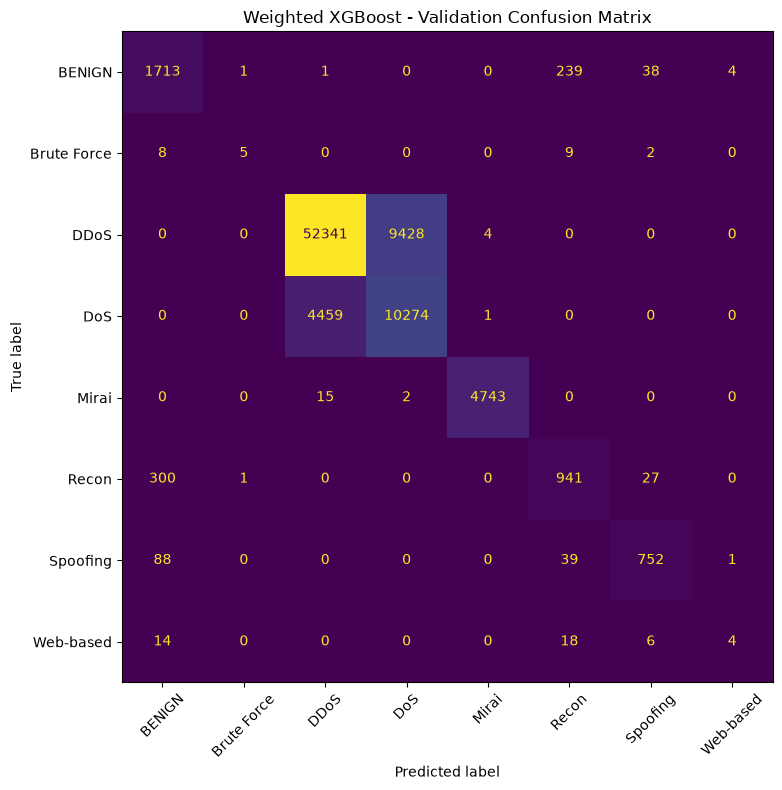

In [180]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(
    y_val_broad_encoded,
    weighted_preds,
    labels=list(range(8))
)

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=broad_encoder.classes_
)

display.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
plt.title("Weighted XGBoost - Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "../results/figures/xgboost_weighted_8class_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [181]:
import pandas as pd
from sklearn.metrics import confusion_matrix

original_cm = confusion_matrix(
    y_val_broad_encoded,
    baseline_preds,
    labels=list(range(8))
)

weighted_cm = confusion_matrix(
    y_val_broad_encoded,
    weighted_preds,
    labels=list(range(8))
)

comparison = pd.DataFrame({
    "Model": ["Original", "Original", "Weighted", "Weighted"],
    "Actual category": ["DDoS", "DoS", "DDoS", "DoS"],
    "Misclassified as opposite category": [
        original_cm[2, 3],
        original_cm[3, 2],
        weighted_cm[2, 3],
        weighted_cm[3, 2]
    ]
})

print(comparison.to_string(index=False))

   Model Actual category  Misclassified as opposite category
Original            DDoS                                2135
Original             DoS                                9335
Weighted            DDoS                                9428
Weighted             DoS                                4459


In [182]:
from sklearn.metrics import classification_report
import pandas as pd

original_report = classification_report(
    y_val_broad_encoded,
    baseline_preds,
    labels=list(range(8)),
    target_names=broad_encoder.classes_,
    output_dict=True,
    zero_division=0
)

weighted_report = classification_report(
    y_val_broad_encoded,
    weighted_preds,
    labels=list(range(8)),
    target_names=broad_encoder.classes_,
    output_dict=True,
    zero_division=0
)

rows = []

for category in broad_encoder.classes_:
    rows.append({
        "Category": category,
        "Original Recall": round(original_report[category]["recall"], 3),
        "Weighted Recall": round(weighted_report[category]["recall"], 3),
        "Original F1": round(original_report[category]["f1-score"], 3),
        "Weighted F1": round(weighted_report[category]["f1-score"], 3)
    })

print(pd.DataFrame(rows).to_string(index=False))

   Category  Original Recall  Weighted Recall  Original F1  Weighted F1
     BENIGN            0.859            0.858        0.828        0.832
Brute Force            0.250            0.208        0.375        0.323
       DDoS            0.965            0.847        0.912        0.883
        DoS            0.366            0.697        0.485        0.597
      Mirai            0.997            0.996        0.998        0.998
      Recon            0.735            0.742        0.743        0.748
   Spoofing            0.850            0.855        0.887        0.882
  Web-based            0.071            0.095        0.120        0.157


In [183]:
from pathlib import Path
import pandas as pd

results_dir = Path("../results/metrics")
results_dir.mkdir(parents=True, exist_ok=True)

comparison_df = pd.DataFrame(rows)
comparison_df.to_csv(
    results_dir / "xgboost_original_vs_weighted_comparison.csv",
    index=False
)

print("Comparison saved to:",
      (results_dir / "xgboost_original_vs_weighted_comparison.csv").resolve())

Comparison saved to: C:\Users\pranu1234\Documents\IoT-IDS\results\metrics\xgboost_original_vs_weighted_comparison.csv


In [184]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np

# Map the original test labels to the 8 broad categories
y_test_broad = y_test_raw.map(map_broad)
y_test_broad_encoded = broad_encoder.transform(y_test_broad)

# Clean test features using training-set medians only
X_test_clean = X_test_raw.replace([np.inf, -np.inf], np.nan).copy()
X_test_clean = X_test_clean.fillna(train_medians)

# Evaluate the weighted model on the held-out test set
test_preds = weighted_model.predict(X_test_clean).astype(int)

print("Weighted Model Test Accuracy:",
      round(accuracy_score(y_test_broad_encoded, test_preds) * 100, 2), "%")

print("Weighted Model Test Macro F1:",
      round(f1_score(y_test_broad_encoded, test_preds, average="macro") * 100, 2), "%")

print("\nTest Classification Report:")
print(classification_report(
    y_test_broad_encoded,
    test_preds,
    labels=list(range(8)),
    target_names=broad_encoder.classes_,
    zero_division=0
))

Weighted Model Test Accuracy: 83.11 %
Weighted Model Test Macro F1: 69.07 %

Test Classification Report:
              precision    recall  f1-score   support

      BENIGN       0.82      0.87      0.84      3269
 Brute Force       0.92      0.25      0.39        44
        DDoS       0.92      0.85      0.88    103295
         DoS       0.52      0.70      0.60     24269
       Mirai       1.00      1.00      1.00      7932
       Recon       0.76      0.77      0.77      2108
    Spoofing       0.92      0.85      0.89      1461
   Web-based       0.44      0.09      0.16        85

    accuracy                           0.83    142463
   macro avg       0.79      0.67      0.69    142463
weighted avg       0.85      0.83      0.84    142463



In [185]:
import pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, precision_score

metrics = {
    "Model": "Weighted XGBoost (8-class)",
    "Test Accuracy": accuracy_score(y_test_broad_encoded, test_preds),
    "Macro F1": f1_score(y_test_broad_encoded, test_preds, average="macro"),
    "Weighted F1": f1_score(y_test_broad_encoded, test_preds, average="weighted"),
    "Macro Precision": precision_score(
        y_test_broad_encoded, test_preds, average="macro", zero_division=0
    )
}

metrics_df = pd.DataFrame([metrics])

output_path = Path("../results/metrics/xgboost_weighted_8class_test_metrics.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
metrics_df.to_csv(output_path, index=False)

print(metrics_df.round(4).to_string(index=False))
print("\nSaved to:", output_path.resolve())

                     Model  Test Accuracy  Macro F1  Weighted F1  Macro Precision
Weighted XGBoost (8-class)         0.8311    0.6907       0.8393           0.7891

Saved to: C:\Users\pranu1234\Documents\IoT-IDS\results\metrics\xgboost_weighted_8class_test_metrics.csv


In [186]:
from sklearn.metrics import accuracy_score, f1_score, recall_score
import pandas as pd

# Predict using the original model on the same cleaned test data
original_test_preds = baseline_model.predict(X_test_clean).astype(int)

# Compare both models on the same test set
comparison_results = []

for name, preds in [
    ("Original XGBoost", original_test_preds),
    ("Weighted XGBoost", test_preds)
]:
    comparison_results.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test_broad_encoded, preds),
        "Macro F1": f1_score(
            y_test_broad_encoded, preds, average="macro"
        ),
        "Weighted F1": f1_score(
            y_test_broad_encoded, preds, average="weighted"
        ),
        "DoS Recall": recall_score(
            y_test_broad_encoded, preds,
            labels=[3], average=None, zero_division=0
        )[0]
    })

final_comparison = pd.DataFrame(comparison_results)

print(final_comparison.round(4).to_string(index=False))

final_comparison.to_csv(
    "../results/metrics/xgboost_final_test_comparison.csv",
    index=False
)

print("\nFinal comparison CSV saved.")

           Model  Test Accuracy  Macro F1  Weighted F1  DoS Recall
Original XGBoost         0.8584    0.6724       0.8410      0.3721
Weighted XGBoost         0.8311    0.6907       0.8393      0.7034

Final comparison CSV saved.


In [187]:

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

class_names = list(broad_encoder.classes_)

print("WEIGHTED XGBOOST - CLASSIFICATION REPORT")
print(
    classification_report(
        y_test_broad_encoded,
        test_preds,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test_broad_encoded,
    test_preds,
    labels=list(range(len(class_names)))
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("\nCONFUSION MATRIX")
print(cm_df)

cm_df.to_csv(
    "../results/metrics/xgboost_weighted_confusion_matrix.csv"
)

print("\nConfusion matrix saved.")


WEIGHTED XGBOOST - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      BENIGN     0.8190    0.8691    0.8433      3269
 Brute Force     0.9167    0.2500    0.3929        44
        DDoS     0.9239    0.8491    0.8849    103295
         DoS     0.5228    0.7034    0.5998     24269
       Mirai     0.9990    0.9961    0.9975      7932
       Recon     0.7622    0.7680    0.7651      2108
    Spoofing     0.9249    0.8515    0.8867      1461
   Web-based     0.4444    0.0941    0.1553        85

    accuracy                         0.8311    142463
   macro avg     0.7891    0.6727    0.6907    142463
weighted avg     0.8547    0.8311    0.8393    142463


CONFUSION MATRIX
             BENIGN  Brute Force   DDoS    DoS  Mirai  Recon  Spoofing  \
BENIGN         2841            0      0      0      0    376        52   
Brute Force      13           11      0      0      0     16         4   
DDoS              0            0  87710  15577      8      0        

In [188]:
import joblib
from pathlib import Path

model_path = Path("../models/xgboost_iot_ids_final.pkl")
encoder_path = Path("../models/xgboost_iot_ids_final_encoder.pkl")

joblib.dump(weighted_model, model_path)
joblib.dump(broad_encoder, encoder_path)

print("Final model saved:", model_path.resolve())
print("Label encoder saved:", encoder_path.resolve())

Final model saved: C:\Users\pranu1234\Documents\IoT-IDS\models\xgboost_iot_ids_final.pkl
Label encoder saved: C:\Users\pranu1234\Documents\IoT-IDS\models\xgboost_iot_ids_final_encoder.pkl


In [189]:
import joblib

broad_model = joblib.load(
    "../models/xgboost_broad_8class.pkl"
)

broad_encoder = joblib.load(
    "../models/broad_label_encoder.pkl"
)

print("Broad XGBoost model loaded successfully.")
print("Number of features:", broad_model.n_features_in_)
print("Categories:", list(broad_encoder.classes_))

Broad XGBoost model loaded successfully.
Number of features: 39
Categories: ['BENIGN', 'Brute Force', 'DDoS', 'DoS', 'Mirai', 'Recon', 'Spoofing', 'Web-based']


In [190]:

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

experiment_model = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

experiment_model.fit(
    X_train_clean,
    y_train_broad_encoded,
    sample_weight=sample_weights
)

experiment_preds = experiment_model.predict(X_val_clean).astype(int)

print("Experiment 1 — Validation Results")
print("Accuracy:", round(
    accuracy_score(y_val_broad_encoded, experiment_preds) * 100, 2
), "%")
print("Macro F1:", round(
    f1_score(y_val_broad_encoded, experiment_preds, average="macro",
             zero_division=0), 4
))
print("Weighted F1:", round(
    f1_score(y_val_broad_encoded, experiment_preds, average="weighted",
             zero_division=0), 4
))


Experiment 1 — Validation Results
Accuracy: 82.77 %
Macro F1: 0.6776
Weighted F1: 0.836


In [191]:

import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

# Use moderately balanced weights instead of full inverse-frequency weights
class_counts = np.bincount(y_train_broad_encoded)
class_weights = (len(y_train_broad_encoded) / (len(class_counts) * class_counts)) ** 0.5
sample_weights_moderate = class_weights[y_train_broad_encoded]

moderate_model = XGBClassifier(
    n_estimators=350,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

moderate_model.fit(
    X_train_clean,
    y_train_broad_encoded,
    sample_weight=sample_weights_moderate
)

moderate_preds = moderate_model.predict(X_val_clean).astype(int)

print("Moderate-weight validation accuracy:",
      round(accuracy_score(y_val_broad_encoded, moderate_preds) * 100, 2), "%")
print("Moderate-weight macro F1:",
      round(f1_score(y_val_broad_encoded, moderate_preds,
                     average="macro", zero_division=0), 4))
print("Moderate-weight weighted F1:",
      round(f1_score(y_val_broad_encoded, moderate_preds,
                     average="weighted", zero_division=0), 4))


Moderate-weight validation accuracy: 82.67 %
Moderate-weight macro F1: 0.6851
Moderate-weight weighted F1: 0.8355


In [192]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_broad_encoded,
    moderate_preds,
    labels=list(range(8)),
    target_names=broad_encoder.classes_,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

      BENIGN     0.8133    0.8512    0.8318      1996
 Brute Force     0.7500    0.2500    0.3750        24
        DDoS     0.9235    0.8428    0.8813     61773
         DoS     0.5179    0.7081    0.5983     14734
       Mirai     0.9992    0.9973    0.9982      4760
       Recon     0.7453    0.7565    0.7509      1269
    Spoofing     0.9229    0.8568    0.8886       880
   Web-based     0.4444    0.0952    0.1569        42

    accuracy                         0.8267     85478
   macro avg     0.7646    0.6697    0.6851     85478
weighted avg     0.8523    0.8267    0.8355     85478



In [193]:
import pandas as pd

class_counts = pd.Series(
    y_train_broad_encoded
).value_counts().sort_index()

distribution = pd.DataFrame({
    "Category": broad_encoder.classes_,
    "Training Samples": [
        class_counts.get(i, 0)
        for i in range(len(broad_encoder.classes_))
    ]
})

print(distribution.to_string(index=False))

   Category  Training Samples
     BENIGN             11312
Brute Force               136
       DDoS            350052
        DoS             83492
      Mirai             26972
      Recon              7185
   Spoofing              4987
  Web-based               234


In [194]:

import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

# Start with the same moderate weights from Experiment 2
class_counts = np.bincount(y_train_broad_encoded)
class_weights = (
    len(y_train_broad_encoded) /
    (len(class_counts) * class_counts)
) ** 0.5

# Give minority classes a modest additional weight
class_weights[1] *= 1.5  # Brute Force
class_weights[7] *= 1.5  # Web-based

sample_weights_extra = class_weights[y_train_broad_encoded]

extra_weight_model = XGBClassifier(
    n_estimators=350,
    max_depth=10,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

extra_weight_model.fit(
    X_train_clean,
    y_train_broad_encoded,
    sample_weight=sample_weights_extra
)

extra_weight_preds = extra_weight_model.predict(X_val_clean).astype(int)

print("Validation Accuracy:",
      round(accuracy_score(y_val_broad_encoded,
                           extra_weight_preds) * 100, 2), "%")
print("Macro F1:",
      round(f1_score(y_val_broad_encoded, extra_weight_preds,
                     average="macro", zero_division=0), 4))
print("Weighted F1:",
      round(f1_score(y_val_broad_encoded, extra_weight_preds,
                     average="weighted", zero_division=0), 4))


Validation Accuracy: 82.69 %
Macro F1: 0.687
Weighted F1: 0.8357


In [195]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_broad_encoded,
    extra_weight_preds,
    labels=list(range(8)),
    target_names=broad_encoder.classes_,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

      BENIGN     0.8110    0.8472    0.8287      1996
 Brute Force     0.6667    0.2500    0.3636        24
        DDoS     0.9238    0.8429    0.8815     61773
         DoS     0.5185    0.7089    0.5990     14734
       Mirai     0.9981    0.9977    0.9979      4760
       Recon     0.7440    0.7604    0.7521      1269
    Spoofing     0.9318    0.8545    0.8915       880
   Web-based     0.3846    0.1190    0.1818        42

    accuracy                         0.8269     85478
   macro avg     0.7473    0.6726    0.6870     85478
weighted avg     0.8525    0.8269    0.8357     85478



In [196]:

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

depth8_model = XGBClassifier(
    n_estimators=350,
    max_depth=8,
    learning_rate=0.05,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

depth8_model.fit(
    X_train_clean,
    y_train_broad_encoded,
    sample_weight=sample_weights_extra
)

depth8_preds = depth8_model.predict(X_val_clean).astype(int)

print("Depth-8 Validation Accuracy:",
      round(accuracy_score(
          y_val_broad_encoded, depth8_preds
      ) * 100, 2), "%")

print("Depth-8 Macro F1:",
      round(f1_score(
          y_val_broad_encoded, depth8_preds,
          average="macro", zero_division=0
      ), 4))

print("Depth-8 Weighted F1:",
      round(f1_score(
          y_val_broad_encoded, depth8_preds,
          average="weighted", zero_division=0
      ), 4))


Depth-8 Validation Accuracy: 82.55 %
Depth-8 Macro F1: 0.6826
Depth-8 Weighted F1: 0.8346


In [198]:

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

lr_model = XGBClassifier(
    n_estimators=700,
    max_depth=10,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

lr_model.fit(
    X_train_clean,
    y_train_broad_encoded,
    sample_weight=sample_weights_extra
)

lr_preds = lr_model.predict(X_val_clean).astype(int)

print("Lower-LR Validation Accuracy:",
      round(accuracy_score(
          y_val_broad_encoded, lr_preds
      ) * 100, 2), "%")

print("Lower-LR Macro F1:",
      round(f1_score(
          y_val_broad_encoded, lr_preds,
          average="macro", zero_division=0
      ), 4))

print("Lower-LR Weighted F1:",
      round(f1_score(
          y_val_broad_encoded, lr_preds,
          average="weighted", zero_division=0
      ), 4))


Lower-LR Validation Accuracy: 82.71 %
Lower-LR Macro F1: 0.6902
Lower-LR Weighted F1: 0.8358


In [199]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_broad_encoded,
    lr_preds,
    labels=list(range(8)),
    target_names=broad_encoder.classes_,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

      BENIGN     0.8095    0.8497    0.8291      1996
 Brute Force     0.8571    0.2500    0.3871        24
        DDoS     0.9234    0.8436    0.8817     61773
         DoS     0.5190    0.7071    0.5986     14734
       Mirai     0.9985    0.9979    0.9982      4760
       Recon     0.7457    0.7557    0.7507      1269
    Spoofing     0.9285    0.8557    0.8906       880
   Web-based     0.4167    0.1190    0.1852        42

    accuracy                         0.8271     85478
   macro avg     0.7748    0.6723    0.6902     85478
weighted avg     0.8524    0.8271    0.8358     85478



In [200]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_broad_encoded,
    extra_weight_preds,
    labels=list(range(8)),
    target_names=broad_encoder.classes_,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

      BENIGN     0.8110    0.8472    0.8287      1996
 Brute Force     0.6667    0.2500    0.3636        24
        DDoS     0.9238    0.8429    0.8815     61773
         DoS     0.5185    0.7089    0.5990     14734
       Mirai     0.9981    0.9977    0.9979      4760
       Recon     0.7440    0.7604    0.7521      1269
    Spoofing     0.9318    0.8545    0.8915       880
   Web-based     0.3846    0.1190    0.1818        42

    accuracy                         0.8269     85478
   macro avg     0.7473    0.6726    0.6870     85478
weighted avg     0.8525    0.8269    0.8357     85478



In [201]:

import pandas as pd
from sklearn.metrics import confusion_matrix

labels = list(range(len(broad_encoder.classes_)))
class_names = list(broad_encoder.classes_)

cm = confusion_matrix(
    y_val_broad_encoded,
    extra_weight_preds,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("Actual Brute Force predictions:")
print(cm_df.loc["Brute Force"])

print("\nActual Web-based predictions:")
print(cm_df.loc["Web-based"])

print("\nActual DoS predictions:")
print(cm_df.loc["DoS"])


Actual Brute Force predictions:
BENIGN         11
Brute Force     6
DDoS            0
DoS             0
Mirai           0
Recon           6
Spoofing        1
Web-based       0
Name: Brute Force, dtype: int64

Actual Web-based predictions:
BENIGN         13
Brute Force     1
DDoS            0
DoS             0
Mirai           0
Recon          18
Spoofing        5
Web-based       5
Name: Web-based, dtype: int64

Actual DoS predictions:
BENIGN             0
Brute Force        0
DDoS            4286
DoS            10445
Mirai              2
Recon              1
Spoofing           0
Web-based          0
Name: DoS, dtype: int64


In [202]:
import joblib
from pathlib import Path

save_path = Path("../models/xgboost_iot_ids_lr500_candidate.pkl")
joblib.dump(lr_model, save_path)

print("Candidate model saved to:", save_path.resolve())

Candidate model saved to: C:\Users\pranu1234\Documents\IoT-IDS\models\xgboost_iot_ids_lr500_candidate.pkl


In [203]:

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score
import joblib
from pathlib import Path

lr500_model = XGBClassifier(
    n_estimators=500,
    max_depth=10,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

lr500_model.fit(
    X_train_clean,
    y_train_broad_encoded,
    sample_weight=sample_weights_extra
)

lr500_preds = lr500_model.predict(X_val_clean).astype(int)

print("500-tree Accuracy:",
      round(accuracy_score(
          y_val_broad_encoded, lr500_preds
      ) * 100, 2), "%")

print("500-tree Macro F1:",
      round(f1_score(
          y_val_broad_encoded, lr500_preds,
          average="macro", zero_division=0
      ), 4))

print("500-tree Weighted F1:",
      round(f1_score(
          y_val_broad_encoded, lr500_preds,
          average="weighted", zero_division=0
      ), 4))

save_path = Path("../models/xgboost_iot_ids_lr500_candidate.pkl")
joblib.dump(lr500_model, save_path)

print("Candidate model saved:", save_path.resolve())


500-tree Accuracy: 82.67 %
500-tree Macro F1: 0.6935
500-tree Weighted F1: 0.8356
Candidate model saved: C:\Users\pranu1234\Documents\IoT-IDS\models\xgboost_iot_ids_lr500_candidate.pkl


In [204]:

from sklearn.metrics import accuracy_score, f1_score, classification_report
import joblib
from pathlib import Path

candidate_path = Path("../models/xgboost_iot_ids_lr500_candidate.pkl")
final_candidate = joblib.load(candidate_path)

final_test_preds = final_candidate.predict(X_test_clean).astype(int)

print("Test Accuracy:",
      round(accuracy_score(
          y_test_broad_encoded, final_test_preds
      ) * 100, 2), "%")

print("Test Macro F1:",
      round(f1_score(
          y_test_broad_encoded, final_test_preds,
          average="macro", zero_division=0
      ), 4))

print("Test Weighted F1:",
      round(f1_score(
          y_test_broad_encoded, final_test_preds,
          average="weighted", zero_division=0
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_test_broad_encoded,
    final_test_preds,
    labels=list(range(8)),
    target_names=broad_encoder.classes_,
    digits=4,
    zero_division=0
))


Test Accuracy: 82.93 %
Test Macro F1: 0.693
Test Weighted F1: 0.8384

Classification Report:
              precision    recall  f1-score   support

      BENIGN     0.8301    0.8596    0.8446      3269
 Brute Force     0.5500    0.2500    0.3438        44
        DDoS     0.9264    0.8436    0.8831    103295
         DoS     0.5183    0.7157    0.6012     24269
       Mirai     0.9982    0.9967    0.9975      7932
       Recon     0.7537    0.7898    0.7714      2108
    Spoofing     0.9329    0.8474    0.8881      1461
   Web-based     0.4444    0.1412    0.2143        85

    accuracy                         0.8293    142463
   macro avg     0.7443    0.6805    0.6930    142463
weighted avg     0.8558    0.8293    0.8384    142463



In [205]:
import joblib
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

old_model = joblib.load(
    Path("../models/xgboost_iot_ids_final.pkl")
)

old_preds = old_model.predict(X_test_clean).astype(int)
new_preds = final_candidate.predict(X_test_clean).astype(int)

for name, preds in [
    ("Existing Final Model", old_preds),
    ("500-tree Candidate", new_preds)
]:
    print(f"\n{name}")
    print("Accuracy:",
          round(accuracy_score(y_test_broad_encoded, preds) * 100, 2), "%")
    print("Macro F1:",
          round(f1_score(y_test_broad_encoded, preds,
                         average="macro", zero_division=0), 4))
    print("Weighted F1:",
          round(f1_score(y_test_broad_encoded, preds,
                         average="weighted", zero_division=0), 4))


Existing Final Model
Accuracy: 83.11 %
Macro F1: 0.6907
Weighted F1: 0.8393

500-tree Candidate
Accuracy: 82.93 %
Macro F1: 0.693
Weighted F1: 0.8384


In [206]:
from pathlib import Path

metrics_dir = Path("../results/metrics")
figures_dir = Path("../results/figures")

print("METRICS FILES")
for file in sorted(metrics_dir.glob("*")):
    print(file.name)

print("\nFIGURE FILES")
for file in sorted(figures_dir.glob("*")):
    print(file.name)

METRICS FILES
classification_report_cnn_lstm_attention.csv
feature_names.csv
final_classification_report_cnn_lstm_attention.csv
label_mapping.csv
model_validation_comparison.csv
shap_feature_importance.csv
training_history_cnn_lstm_attention.csv
xgboost_broad_8class_results.csv
xgboost_feature_importance.csv
xgboost_final_test_comparison.csv
xgboost_original_vs_weighted_comparison.csv
xgboost_weighted_8class_test_metrics.csv
xgboost_weighted_confusion_matrix.csv

FIGURE FILES
confusion_matrix_cnn_lstm_attention.png
final_confusion_matrix_cnn_lstm_attention.png
final_shap_feature_importance.png
shap_feature_importance_ddos_rstfinflood.png
shap_top10_feature_contributions.png
training_validation_accuracy.png
training_validation_loss.png
xgboost_8class_confusion_matrix.png
xgboost_top15_feature_importance.png
xgboost_weighted_8class_confusion_matrix.png
xgboost_weighted_8class_test_confusion_matrix.png


In [207]:
import pandas as pd
from pathlib import Path

file_path = Path("../results/metrics/xgboost_weighted_8class_test_metrics.csv")

df = pd.read_csv(file_path)
print(df.to_string(index=False))

                     Model  Test Accuracy  Macro F1  Weighted F1  Macro Precision
Weighted XGBoost (8-class)       0.831135  0.690699     0.839342         0.789121


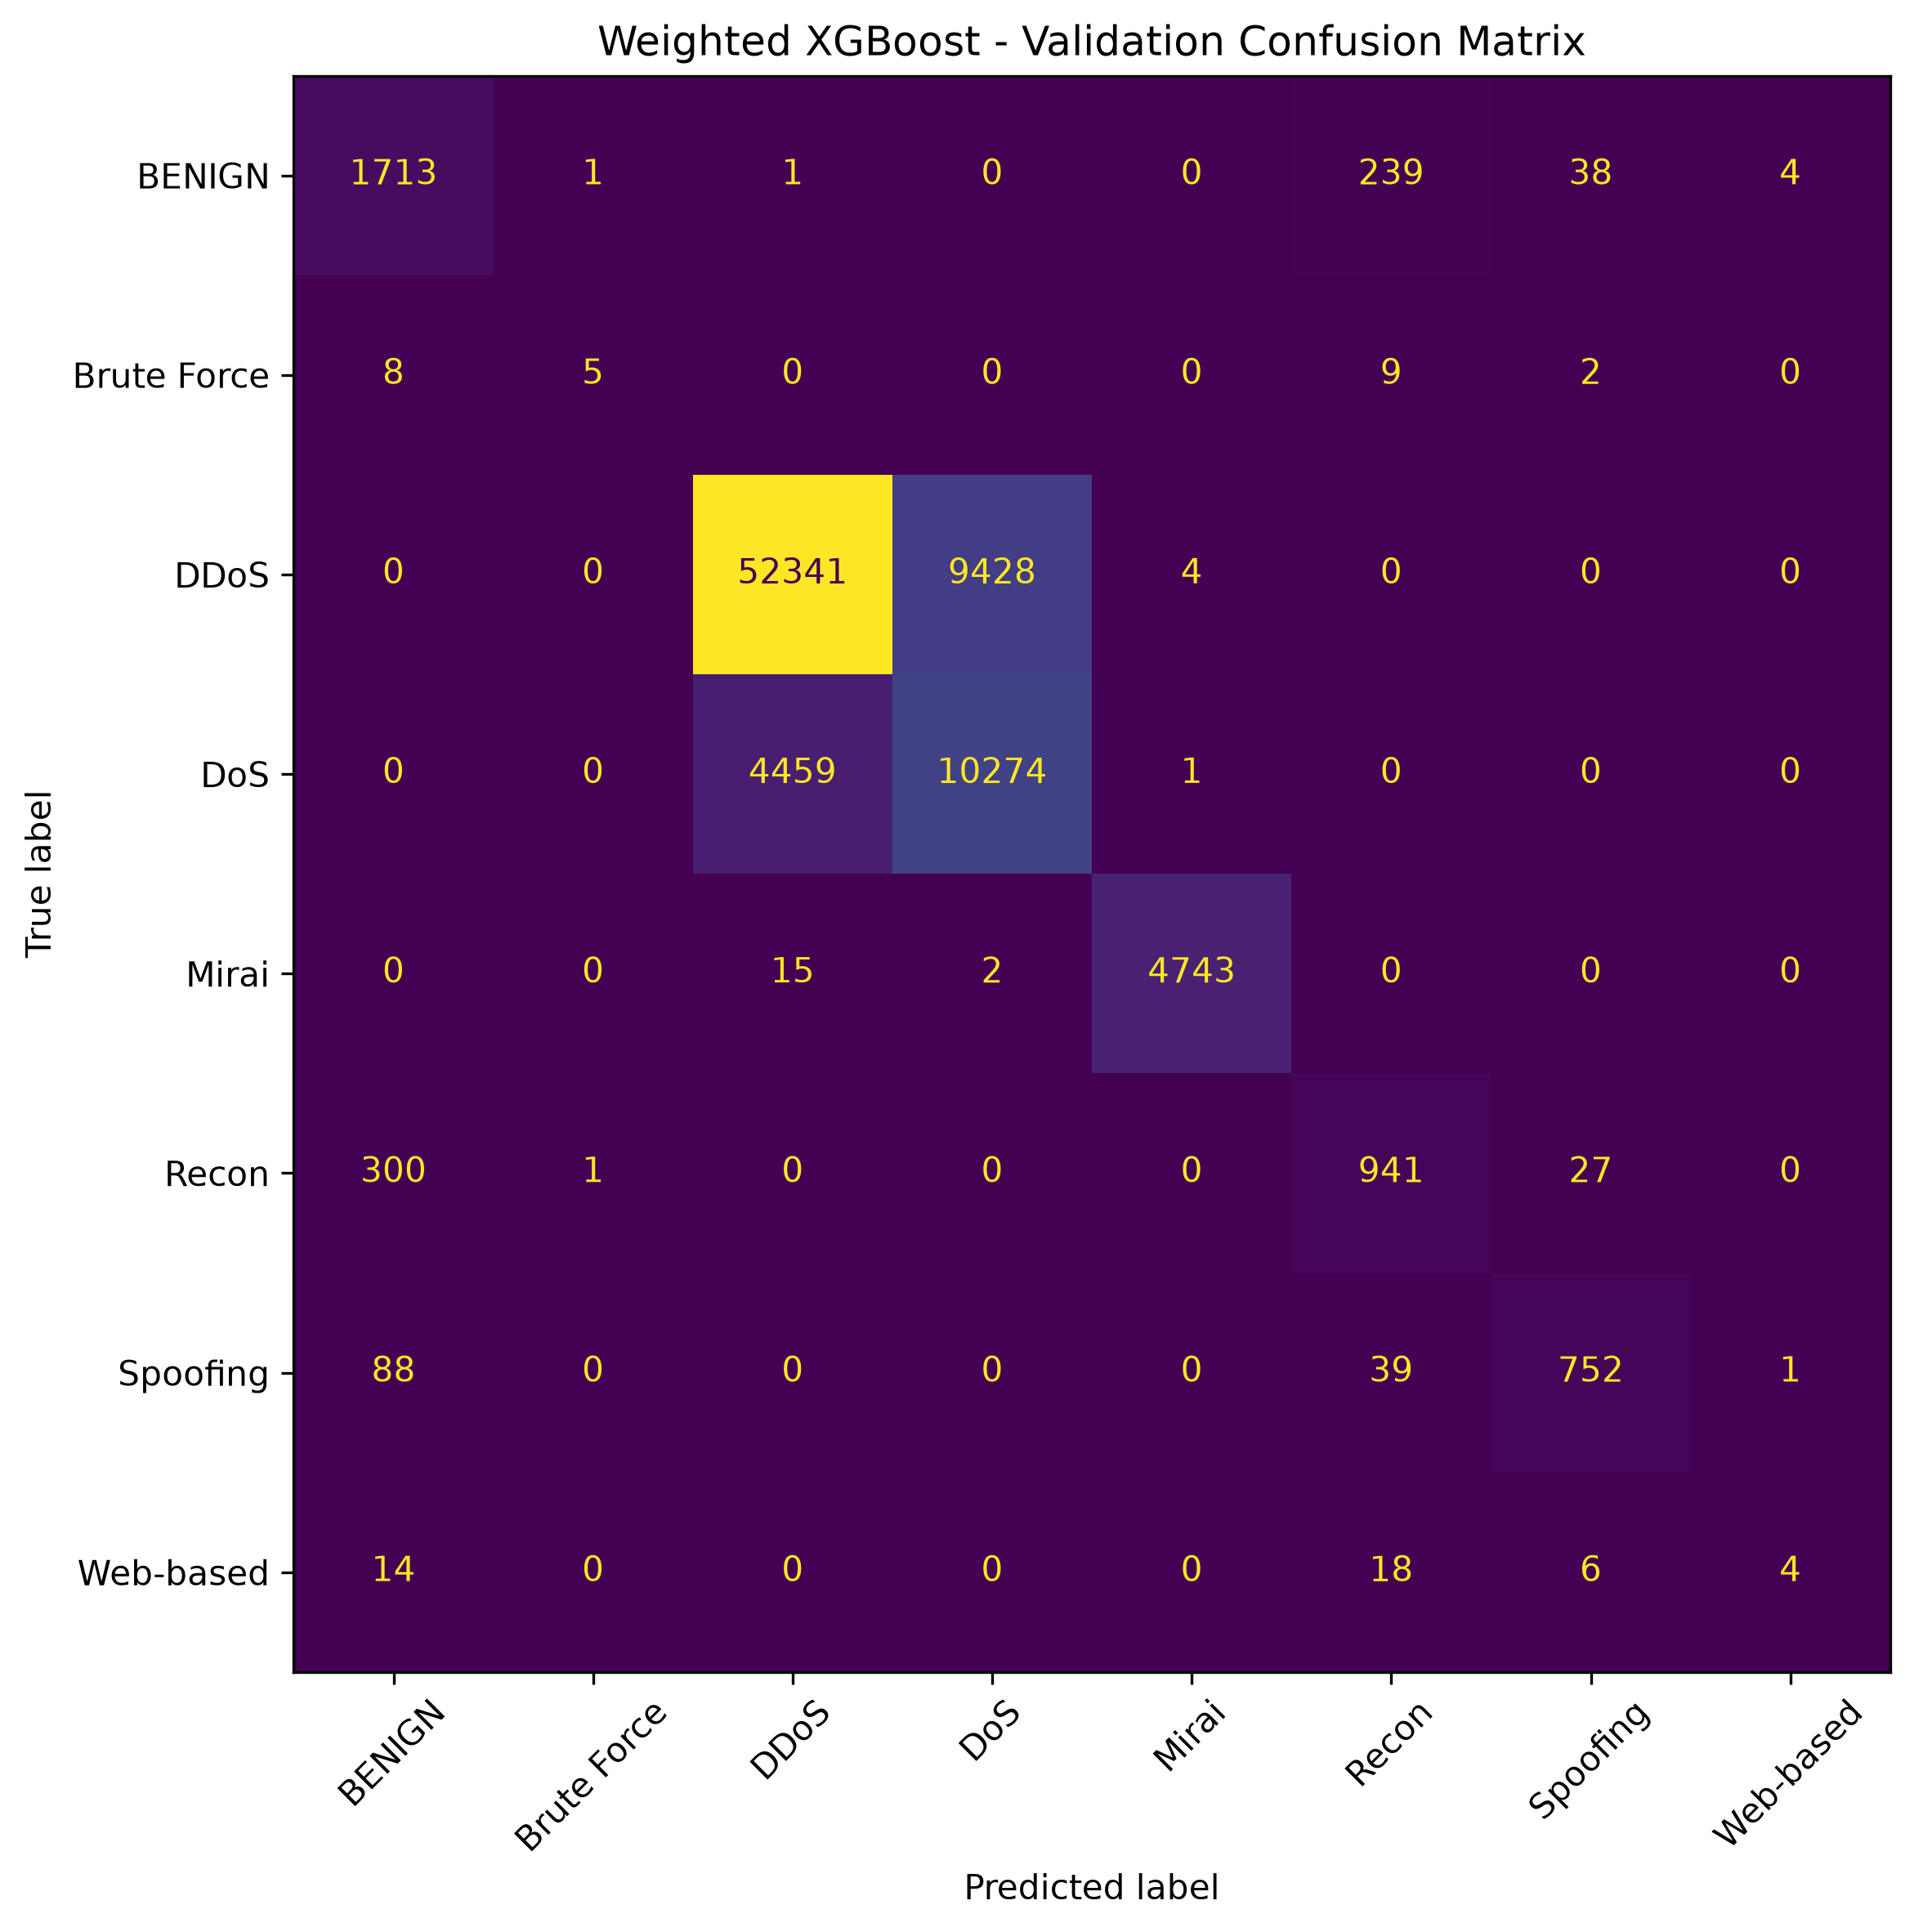

In [208]:
from IPython.display import Image, display
from pathlib import Path

cm_path = Path("../results/figures/xgboost_weighted_8class_confusion_matrix.png")
display(Image(filename=str(cm_path)))

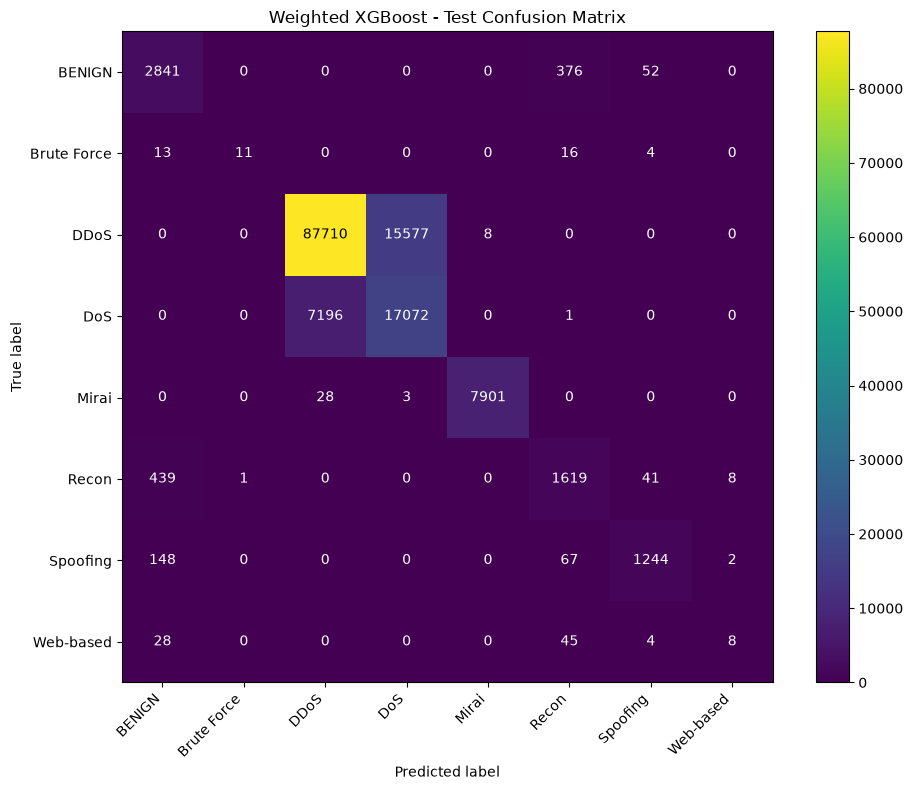

Saved to: ..\results\figures\xgboost_weighted_8class_test_confusion_matrix.png


In [209]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from pathlib import Path

test_preds = old_model.predict(X_test_clean).astype(int)

cm = confusion_matrix(
    y_test_broad_encoded,
    test_preds,
    labels=list(range(8))
)

fig, ax = plt.subplots(figsize=(10, 8))

img = ax.imshow(cm, interpolation="nearest", cmap="viridis")
fig.colorbar(img, ax=ax)

classes = broad_encoder.classes_
ax.set(
    xticks=range(8),
    yticks=range(8),
    xticklabels=classes,
    yticklabels=classes,
    xlabel="Predicted label",
    ylabel="True label",
    title="Weighted XGBoost - Test Confusion Matrix"
)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

for i in range(8):
    for j in range(8):
        ax.text(j, i, str(cm[i, j]),
                ha="center", va="center",
                color="white" if cm[i, j] < cm.max() * 0.5 else "black")

plt.tight_layout()

output_path = Path("../results/figures/xgboost_weighted_8class_test_confusion_matrix.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved to:", output_path)

In [210]:
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score
)

preds = old_model.predict(X_test_clean).astype(int)

metrics = pd.DataFrame([{
    "Model": "Weighted XGBoost (8-class)",
    "Test Accuracy": accuracy_score(y_test_broad_encoded, preds),
    "Macro F1": f1_score(
        y_test_broad_encoded, preds, average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_test_broad_encoded, preds, average="weighted", zero_division=0
    ),
    "Macro Precision": precision_score(
        y_test_broad_encoded, preds, average="macro", zero_division=0
    )
}])

output_path = Path("../results/metrics/xgboost_weighted_8class_test_metrics.csv")
metrics.to_csv(output_path, index=False)

print(metrics.to_string(index=False))
print("\nSaved to:", output_path)

                     Model  Test Accuracy  Macro F1  Weighted F1  Macro Precision
Weighted XGBoost (8-class)       0.831135  0.690699     0.839342         0.789121

Saved to: ..\results\metrics\xgboost_weighted_8class_test_metrics.csv


In [211]:
from sklearn.metrics import recall_score

dos_recall = recall_score(
    y_test_broad_encoded,
    old_model.predict(X_test_clean).astype(int),
    labels=[list(broad_encoder.classes_).index("DoS")],
    average=None,
    zero_division=0
)[0]

print("Final Test DoS Recall:", round(dos_recall * 100, 2), "%")

Final Test DoS Recall: 70.34 %


In [212]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

xgb_unweighted_candidate = XGBClassifier(
    n_estimators=500,
    max_depth=10,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_unweighted_candidate.fit(
    X_train_clean,
    y_train_broad_encoded
)

unweighted_preds = xgb_unweighted_candidate.predict(
    X_val_clean
).astype(int)

print("Validation Accuracy:",
      round(accuracy_score(y_val_broad_encoded, unweighted_preds) * 100, 2), "%")

print("Validation Macro F1:",
      round(f1_score(y_val_broad_encoded, unweighted_preds,
                     average="macro", zero_division=0), 4))

print("Validation Weighted F1:",
      round(f1_score(y_val_broad_encoded, unweighted_preds,
                     average="weighted", zero_division=0), 4))

Validation Accuracy: 85.62 %
Validation Macro F1: 0.6651
Validation Weighted F1: 0.8373


In [213]:
xgb_depth8_candidate = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_depth8_candidate.fit(
    X_train_clean,
    y_train_broad_encoded
)

depth8_preds = xgb_depth8_candidate.predict(
    X_val_clean
).astype(int)

print("Validation Accuracy:",
      round(accuracy_score(y_val_broad_encoded, depth8_preds) * 100, 2), "%")

print("Validation Macro F1:",
      round(f1_score(y_val_broad_encoded, depth8_preds,
                     average="macro", zero_division=0), 4))

print("Validation Weighted F1:",
      round(f1_score(y_val_broad_encoded, depth8_preds,
                     average="weighted", zero_division=0), 4))

Validation Accuracy: 85.63 %
Validation Macro F1: 0.6741
Validation Weighted F1: 0.8368


In [214]:
xgb_depth6_candidate = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_depth6_candidate.fit(
    X_train_clean,
    y_train_broad_encoded
)

depth6_preds = xgb_depth6_candidate.predict(
    X_val_clean
).astype(int)

print("Validation Accuracy:",
      round(accuracy_score(y_val_broad_encoded, depth6_preds) * 100, 2), "%")

print("Validation Macro F1:",
      round(f1_score(y_val_broad_encoded, depth6_preds,
                     average="macro", zero_division=0), 4))

print("Validation Weighted F1:",
      round(f1_score(y_val_broad_encoded, depth6_preds,
                     average="weighted", zero_division=0), 4))

Validation Accuracy: 85.48 %
Validation Macro F1: 0.6662
Validation Weighted F1: 0.8345


In [216]:
xgb_depth8_700 = XGBClassifier(
    n_estimators=700,
    max_depth=8,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_depth8_700.fit(
    X_train_clean,
    y_train_broad_encoded
)

preds_700 = xgb_depth8_700.predict(X_val_clean).astype(int)

print("Validation Accuracy:",
      round(accuracy_score(y_val_broad_encoded, preds_700) * 100, 2), "%")

print("Validation Macro F1:",
      round(f1_score(y_val_broad_encoded, preds_700,
                     average="macro", zero_division=0), 4))

print("Validation Weighted F1:",
      round(f1_score(y_val_broad_encoded, preds_700,
                     average="weighted", zero_division=0), 4))

Validation Accuracy: 85.64 %
Validation Macro F1: 0.6731
Validation Weighted F1: 0.8376


In [217]:
print("Training shape:", X_train_clean.shape)
print("Validation shape:", X_val_clean.shape)

print("Training labels:", y_train_broad_encoded.shape)
print("Validation labels:", y_val_broad_encoded.shape)

print("Missing values in training:",
      X_train_clean.isnull().sum().sum()
      if hasattr(X_train_clean, "isnull")
      else "Check array separately")

print("Missing values in validation:",
      X_val_clean.isnull().sum().sum()
      if hasattr(X_val_clean, "isnull")
      else "Check array separately")

Training shape: (484370, 39)
Validation shape: (85478, 39)
Training labels: (484370,)
Validation labels: (85478,)
Missing values in training: 0
Missing values in validation: 0


In [218]:
import pandas as pd

train_df = pd.DataFrame(X_train_clean)
val_df = pd.DataFrame(X_val_clean)

train_rows = set(map(tuple, train_df.to_numpy()))
val_rows = set(map(tuple, val_df.to_numpy()))

overlap = len(train_rows.intersection(val_rows))

print("Exact duplicate feature rows across splits:", overlap)
print("Validation rows:", len(val_df))
print("Overlap percentage:",
      round(overlap / len(val_df) * 100, 4), "%")

Exact duplicate feature rows across splits: 22753
Validation rows: 85478
Overlap percentage: 26.6185 %


In [219]:
import pandas as pd

feature_cols = list(range(X_train_clean.shape[1]))

train_check = pd.DataFrame(X_train_clean, columns=feature_cols)
train_check["label"] = y_train_broad_encoded

val_check = pd.DataFrame(X_val_clean, columns=feature_cols)
val_check["label"] = y_val_broad_encoded

# Keep one label for each unique training feature row
train_unique = train_check.drop_duplicates(subset=feature_cols)

train_label_map = train_unique.set_index(feature_cols)["label"]

# Find validation feature rows that also occur in training
val_index = pd.MultiIndex.from_frame(val_check[feature_cols])
train_index = train_label_map.index

common_mask = val_index.isin(train_index)
matching_val = val_check.loc[common_mask]

matching_train_labels = train_label_map.reindex(
    pd.MultiIndex.from_frame(matching_val[feature_cols])
).to_numpy()

different_labels = (
    matching_val["label"].to_numpy() != matching_train_labels
).sum()

print("Validation rows with matching training features:", common_mask.sum())
print("Matching rows with different labels:", different_labels)

Validation rows with matching training features: 85478
Matching rows with different labels: 23705


In [220]:
import pandas as pd

feature_cols = list(range(X_train_clean.shape[1]))

train_check = pd.DataFrame(X_train_clean, columns=feature_cols)
train_check["label"] = y_train_broad_encoded

val_check = pd.DataFrame(X_val_clean, columns=feature_cols)
val_check["label"] = y_val_broad_encoded

# Count distinct labels for each unique feature combination
train_label_counts = train_check.groupby(feature_cols)["label"].nunique()

# Identify feature combinations that have multiple training labels
conflicting_features = train_label_counts[train_label_counts > 1]

print("Unique training feature combinations:", len(train_label_counts))
print("Training feature combinations with conflicting labels:",
      len(conflicting_features))
print("Training rows belonging to conflicting combinations:",
      int(train_check.set_index(feature_cols).index.isin(
          conflicting_features.index
      ).sum()))

Unique training feature combinations: 0
Training feature combinations with conflicting labels: 0
Training rows belonging to conflicting combinations: 0


In [221]:
print("X_train_clean shape:", X_train_clean.shape)
print("X_val_clean shape:", X_val_clean.shape)

print("Training data type:", type(X_train_clean))
print("First 5 training rows:\n", X_train_clean[:5])

print("Training labels shape:", y_train_broad_encoded.shape)
print("Validation labels shape:", y_val_broad_encoded.shape)

X_train_clean shape: (484370, 39)
X_val_clean shape: (85478, 39)
Training data type: <class 'pandas.core.frame.DataFrame'>
First 5 training rows:
    Header_Length  Protocol Type  Time_To_Live          Rate  fin_flag_number  \
0          20.00              6         64.00  27900.645247              0.0   
1           0.00              1         63.36  15830.549160              0.0   
2           8.00             17         64.00  38864.936990              0.0   
3          20.00              6         64.00  23336.693930              0.0   
4           7.84             17         67.82  26329.591965              0.0   

   syn_flag_number  rst_flag_number  psh_flag_number  ack_flag_number  \
0              0.0              0.0              0.0              0.0   
1              0.0              0.0              0.0              0.0   
2              0.0              0.0              0.0              0.0   
3              1.0              0.0              0.0              0.0   
4      

In [222]:
import pandas as pd

feature_cols = X_train_clean.columns

train_features = X_train_clean.copy()
train_features["label"] = y_train_broad_encoded

val_features = X_val_clean.copy()
val_features["label"] = y_val_broad_encoded

# Unique training feature rows
train_unique = train_features.drop_duplicates(subset=feature_cols)

# Number of distinct labels associated with each feature combination
label_counts = train_features.groupby(
    list(feature_cols), dropna=False
)["label"].nunique()

conflicting = label_counts[label_counts > 1]

# Validation rows whose features occur in training
train_index = pd.MultiIndex.from_frame(train_unique[feature_cols])
val_index = pd.MultiIndex.from_frame(val_features[feature_cols])

print("Unique training feature combinations:", len(train_unique))
print("Training combinations with conflicting labels:", len(conflicting))
print("Validation rows with matching training features:", val_index.isin(train_index).sum())

Unique training feature combinations: 371649
Training combinations with conflicting labels: 12683
Validation rows with matching training features: 28920


In [223]:
feature_cols = X_train_clean.columns

train_check = X_train_clean.copy()
train_check["label"] = y_train_broad_encoded

label_counts = train_check.groupby(
    list(feature_cols), dropna=False
)["label"].nunique()

conflicting_features = label_counts[label_counts > 1].index

conflicting_rows = train_check.set_index(
    list(feature_cols)
).loc[conflicting_features]

print("Number of conflicting feature combinations:",
      len(conflicting_features))

print("\nLabels involved in conflicting combinations:")
print(
    conflicting_rows["label"]
    .value_counts()
    .sort_index()
)

Number of conflicting feature combinations: 12683

Labels involved in conflicting combinations:
label
0       15
2    30398
3    20700
5       11
6       67
7        1
Name: count, dtype: int64


In [224]:
feature_cols = X_train_clean.columns

train_check = X_train_clean.copy()
train_check["label"] = y_train_broad_encoded

# Count distinct labels for each feature combination
label_counts = train_check.groupby(
    list(feature_cols), dropna=False
)["label"].nunique()

conflicting_index = label_counts[label_counts > 1].index

# Select rows belonging to conflicting feature combinations
row_index = pd.MultiIndex.from_frame(train_check[feature_cols])
mask = row_index.isin(conflicting_index)

conflict_rows = train_check.loc[mask]

print("Rows belonging to conflicting combinations:", int(mask.sum()))
print("Percentage of training rows affected:",
      round(mask.mean() * 100, 2), "%")

print("\nLabels among affected rows:")
print(conflict_rows["label"].value_counts().sort_index())

Rows belonging to conflicting combinations: 51192
Percentage of training rows affected: 10.57 %

Labels among affected rows:
label
0       15
2    30398
3    20700
5       11
6       67
7        1
Name: count, dtype: int64


In [225]:
feature_cols = X_train_clean.columns

train_check = X_train_clean.copy()
train_check["label"] = y_train_broad_encoded

label_counts = train_check.groupby(
    list(feature_cols), dropna=False
)["label"].nunique()

conflicting_index = label_counts[label_counts > 1].index

conflict_rows = train_check.set_index(
    list(feature_cols)
).loc[conflicting_index]

print("First 10 conflicting feature combinations:")
print(conflict_rows.groupby(level=list(range(len(feature_cols))))["label"]
      .unique().head(10))

First 10 conflicting feature combinations:
Header_Length  Protocol Type  Time_To_Live  Rate          fin_flag_number  syn_flag_number  rst_flag_number  psh_flag_number  ack_flag_number  ece_flag_number  cwr_flag_number  ack_count  syn_count  fin_count  rst_count  HTTP  HTTPS  DNS  Telnet  SMTP  SSH  IRC  TCP  UDP   DHCP  ARP   ICMP  IGMP  IPv   LLC   Tot sum  Min  Max  AVG   Std       Tot size  IAT       Number  Variance
7.76           17             67.18         15747.931216  0.0              0.0              0.0              0.0              0.0              0.0              0.0              0          0          0          0          0.0   0.0    0.0  0.0     0.0   0.0  0.0  0.0  0.97  0.0   0.01  0.02  0.0   0.99  0.99  6020     60   70   60.2  1.407053  60.2      0.000064  100     1.979798    [3, 2]
7.92           17             63.36         10933.771278  0.0              0.0              0.0              0.0              0.0              0.0              0.0              0     

In [226]:
feature_cols = X_train_clean.columns

train_check = X_train_clean.copy()
train_check["label"] = y_train_broad_encoded

label_sets = train_check.groupby(
    list(feature_cols), dropna=False
)["label"].agg(lambda labels: set(labels))

conflicting_sets = label_sets[
    label_sets.apply(lambda labels: len(labels) > 1)
]

ddos_dos_conflicts = conflicting_sets[
    conflicting_sets.apply(lambda labels: labels == {2, 3})
]

print("Total conflicting feature combinations:", len(conflicting_sets))
print("Combinations labeled as both DDoS and DoS:", len(ddos_dos_conflicts))
print(
    "Combinations involving DDoS or DoS and other labels:",
    conflicting_sets.apply(lambda labels: 2 in labels or 3 in labels).sum()
    - len(ddos_dos_conflicts)
)

Total conflicting feature combinations: 12683
Combinations labeled as both DDoS and DoS: 12664
Combinations involving DDoS or DoS and other labels: 0


In [227]:
print("Available training variables:")
for name in ["y_train", "y_train_broad", "y_train_broad_encoded"]:
    if name in globals():
        print(name, "->", type(globals()[name]), 
              getattr(globals()[name], "shape", None))

Available training variables:
y_train_broad -> <class 'pandas.core.series.Series'> (484370,)
y_train_broad_encoded -> <class 'numpy.ndarray'> (484370,)


In [228]:
feature_cols = X_train_clean.columns

train_check = X_train_clean.copy()
train_check["label"] = y_train_broad.to_numpy()

label_sets = train_check.groupby(
    list(feature_cols), dropna=False
)["label"].agg(lambda labels: sorted(set(labels)))

conflicting_sets = label_sets[
    label_sets.apply(lambda labels: len(labels) > 1)
]

print("Conflicting feature combinations:", len(conflicting_sets))
print("\nExamples of conflicting category labels:")
print(conflicting_sets.head(10).to_string())
print("\nCategories involved in conflicts:")
print(
    sorted({
        label
        for labels in conflicting_sets
        for label in labels
    })
)

Conflicting feature combinations: 12683

Examples of conflicting category labels:
Header_Length  Protocol Type  Time_To_Live  Rate          fin_flag_number  syn_flag_number  rst_flag_number  psh_flag_number  ack_flag_number  ece_flag_number  cwr_flag_number  ack_count  syn_count  fin_count  rst_count  HTTP  HTTPS  DNS  Telnet  SMTP  SSH  IRC  TCP  UDP   DHCP  ARP   ICMP  IGMP  IPv   LLC   Tot sum  Min  Max  AVG   Std       Tot size  IAT       Number  Variance
7.76           17             67.18         15747.931216  0.0              0.0              0.0              0.0              0.0              0.0              0.0              0          0          0          0          0.0   0.0    0.0  0.0     0.0   0.0  0.0  0.0  0.97  0.0   0.01  0.02  0.0   0.99  0.99  6020     60   70   60.2  1.407053  60.2      0.000064  100     1.979798    [DDoS, DoS]
7.92           17             63.36         10933.771278  0.0              0.0              0.0              0.0              0.0          

In [229]:
print("Available variables related to original labels:")

for name in [
    "df", "data", "merged_df", "y_train_raw",
    "y_train_original", "y_train"
]:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            type(obj),
            getattr(obj, "shape", None),
            list(obj.columns)[:10]
            if isinstance(obj, pd.DataFrame)
            else ""
        )

Available variables related to original labels:
df <class 'pandas.core.frame.DataFrame'> (1, 5) ['Model', 'Test Accuracy', 'Macro F1', 'Weighted F1', 'Macro Precision']
y_train_raw <class 'pandas.core.series.Series'> (569848,) 


In [230]:
print("Raw training labels shape:", y_train_raw.shape)
print("\nFirst 10 raw labels:")
print(y_train_raw.head(10))

print("\nMost frequent raw labels:")
print(y_train_raw.value_counts().head(15))

Raw training labels shape: (569848,)

First 10 raw labels:
0    DDOS-PSHACK_FLOOD
1    MIRAI-GREIP_FLOOD
2        DOS-UDP_FLOOD
3         DNS_SPOOFING
4      DDOS-ICMP_FLOOD
5       DDOS-TCP_FLOOD
6    DDOS-PSHACK_FLOOD
7       DDOS-SYN_FLOOD
8       DDOS-UDP_FLOOD
9     MITM-ARPSPOOFING
Name: Label, dtype: object

Most frequent raw labels:
Label
DDOS-ICMP_FLOOD            86720
DDOS-UDP_FLOOD             65647
DDOS-TCP_FLOOD             54719
DDOS-PSHACK_FLOOD          49828
DDOS-RSTFINFLOOD           49301
DDOS-SYN_FLOOD             49085
DDOS-SYNONYMOUSIP_FLOOD    43540
DOS-UDP_FLOOD              40369
DOS-TCP_FLOOD              32384
DOS-SYN_FLOOD              24588
BENIGN                     13308
MIRAI-GREETH_FLOOD         12141
MIRAI-UDPPLAIN             10650
MIRAI-GREIP_FLOOD           8941
DDOS-ICMP_FRAGMENTATION     5481
Name: count, dtype: int64


In [231]:
print("Available variables that may contain cleaned raw labels:")

for name in [
    "y_train_raw_clean",
    "y_train_raw_cleaned",
    "y_train_original_clean",
    "y_train_raw_encoded",
    "y_train_broad"
]:
    if name in globals():
        obj = globals()[name]
        print(name, type(obj), getattr(obj, "shape", None))

Available variables that may contain cleaned raw labels:
y_train_broad <class 'pandas.core.series.Series'> (484370,)


In [232]:
import pandas as pd

feature_cols = X_train_part.columns

train_check = X_train_part.reset_index(drop=True).copy()
train_check["raw_label"] = y_train_part_raw.reset_index(drop=True)

# Find feature combinations associated with multiple original labels
raw_label_sets = train_check.groupby(
    list(feature_cols), dropna=False
)["raw_label"].agg(lambda labels: sorted(set(labels)))

conflicting_raw = raw_label_sets[
    raw_label_sets.apply(lambda labels: len(labels) > 1)
]

print("Conflicting feature combinations using original labels:",
      len(conflicting_raw))

print("\nFirst 10 examples:")
print(conflicting_raw.head(10).to_string())

Conflicting feature combinations using original labels: 16241

First 10 examples:
Header_Length  Protocol Type  Time_To_Live  Rate          fin_flag_number  syn_flag_number  rst_flag_number  psh_flag_number  ack_flag_number  ece_flag_number  cwr_flag_number  ack_count  syn_count  fin_count  rst_count  HTTP  HTTPS  DNS  Telnet  SMTP  SSH  IRC  TCP  UDP   DHCP  ARP   ICMP  IGMP  IPv   LLC   Tot sum  Min  Max  AVG   Std       Tot size  IAT       Number  Variance
7.76           17             67.18         15747.931216  0.0              0.0              0.0              0.0              0.0              0.0              0.0              0          0          0          0          0.0   0.0    0.0  0.0     0.0   0.0  0.0  0.0  0.97  0.0   0.01  0.02  0.0   0.99  0.99  6020     60   70   60.2  1.407053  60.2      0.000064  100     1.979798    [DDOS-UDP_FLOOD, DOS-UDP_FLOOD]
7.92           17             63.36         10933.771278  0.0              0.0              0.0              0.0       

In [233]:
from collections import Counter

raw_conflict_sizes = conflicting_raw.apply(len)

print("Conflicting combinations:", len(raw_conflict_sizes))
print("\nNumber of labels per conflicting combination:")
print(raw_conflict_sizes.value_counts().sort_index())

print("\nMost common original labels in conflicting combinations:")
print(
    train_check[
        train_check.set_index(list(feature_cols)).index.isin(
            conflicting_raw.index
        )
    ]["raw_label"].value_counts().head(10)
)

Conflicting combinations: 16241

Number of labels per conflicting combination:
raw_label
2    14562
3     1678
5        1
Name: count, dtype: int64

Most common original labels in conflicting combinations:
raw_label
DDOS-SYN_FLOOD             12680
DDOS-TCP_FLOOD             12372
DDOS-SYNONYMOUSIP_FLOOD    10988
DOS-TCP_FLOOD               8738
DDOS-UDP_FLOOD              6984
DOS-UDP_FLOOD               6199
DOS-SYN_FLOOD               5763
MITM-ARPSPOOFING              74
BENIGN                        15
DNS_SPOOFING                   9
Name: count, dtype: int64


In [234]:
feature_cols = X_train_part.columns

check = X_train_part.reset_index(drop=True).copy()
check["raw_label"] = y_train_part_raw.reset_index(drop=True)
check["broad_label"] = y_train_broad.reset_index(drop=True)

broad_label_sets = check.groupby(
    list(feature_cols), dropna=False
)["broad_label"].agg(lambda labels: set(labels))

broad_conflicts = broad_label_sets[
    broad_label_sets.apply(lambda labels: len(labels) > 1)
]

print("Feature combinations with conflicting broad labels:",
      len(broad_conflicts))
print("Total unique feature combinations:", check[feature_cols].drop_duplicates().shape[0])

Feature combinations with conflicting broad labels: 12683
Total unique feature combinations: 371649


In [235]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

feature_cols = X_train_part.columns

train_check = X_train_part.copy()
train_check["broad_label"] = y_train_broad.to_numpy()

label_counts = train_check.groupby(
    list(feature_cols), dropna=False
)["broad_label"].nunique()

conflicting_features = label_counts[label_counts > 1].index

val_index = pd.MultiIndex.from_frame(X_val[feature_cols])
conflict_mask = val_index.isin(conflicting_features)

print("Validation rows with conflicting training features:",
      int(conflict_mask.sum()))
print("Validation rows without conflicting training features:",
      int((~conflict_mask).sum()))

Validation rows with conflicting training features: 6664
Validation rows without conflicting training features: 78814


In [236]:
from sklearn.metrics import accuracy_score, f1_score

# Predict using the existing weighted XGBoost model
val_pred = xgb_weighted.predict(X_val)

y_val_array = y_val_broad_encoded

for name, mask in [
    ("Conflicting-feature rows", conflict_mask),
    ("Other validation rows", ~conflict_mask),
]:
    if mask.sum() == 0:
        print(f"\n{name}: no rows")
        continue

    print(f"\n{name}")
    print("Rows:", int(mask.sum()))
    print(
        "Accuracy:",
        round(accuracy_score(y_val_array[mask], val_pred[mask]) * 100, 2),
        "%"
    )
    print(
        "Macro F1:",
        round(f1_score(
            y_val_array[mask], val_pred[mask], average="macro",
            zero_division=0
        ), 4)
    )


Conflicting-feature rows
Rows: 6664
Accuracy: 0.0 %
Macro F1: 0.0

Other validation rows
Rows: 78814
Accuracy: 0.0 %
Macro F1: 0.0


In [237]:
print("Possible trained model variables:")

for name, obj in globals().items():
    if (
        not name.startswith("_")
        and hasattr(obj, "predict")
        and hasattr(obj, "predict_proba")
    ):
        print(name, type(obj).__name__)

Possible trained model variables:
XGBClassifier type
model_all_features XGBClassifier
RandomForestClassifier ABCMeta
rf_model RandomForestClassifier
ExtraTreesClassifier ABCMeta
extra_model ExtraTreesClassifier
rf_top15 RandomForestClassifier
HistGradientBoostingClassifier ABCMeta
hgb_model HistGradientBoostingClassifier
xgb_model XGBClassifier
xgb_tuned XGBClassifier
xgb_weighted XGBClassifier
xgb_val_model XGBClassifier
xgb_weighted_val XGBClassifier
xgb_no_protocol XGBClassifier
loaded_xgb_model XGBClassifier
xgb_selected XGBClassifier
lgb_model LGBMClassifier
xgb_sqrt XGBClassifier
xgb_early XGBClassifier
xgb_broad_model XGBClassifier
broad_model XGBClassifier
dos_weight_model XGBClassifier
weighted_model XGBClassifier
xgb_90_candidate XGBClassifier
baseline_model XGBClassifier
experiment_model XGBClassifier
moderate_model XGBClassifier
extra_weight_model XGBClassifier
depth8_model XGBClassifier
lr_model XGBClassifier
lr500_model XGBClassifier
final_candidate XGBClassifier
old_mode

In [238]:
from sklearn.metrics import accuracy_score, f1_score

# Predict with the existing weighted model
val_pred = weighted_model.predict(X_val)

y_val_array = y_val_broad_encoded

for name, mask in [
    ("Conflicting-feature rows", conflict_mask),
    ("Other validation rows", ~conflict_mask),
]:
    if mask.sum() == 0:
        print(f"\n{name}: no rows")
        continue

    print(f"\n{name}")
    print("Rows:", int(mask.sum()))
    print(
        "Accuracy:",
        round(accuracy_score(
            y_val_array[mask], val_pred[mask]
        ) * 100, 2),
        "%"
    )
    print(
        "Macro F1:",
        round(f1_score(
            y_val_array[mask],
            val_pred[mask],
            average="macro",
            zero_division=0
        ), 4)
    )


Conflicting-feature rows
Rows: 6664
Accuracy: 64.72 %
Macro F1: 0.7492

Other validation rows
Rows: 78814
Accuracy: 84.33 %
Macro F1: 0.6801


In [239]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_array[conflict_mask],
    val_pred[conflict_mask],
    labels=list(range(8)),
    target_names=[
        "BENIGN", "Brute Force", "DDoS", "DoS",
        "Mirai", "Recon", "Spoofing", "Web-based"
    ],
    zero_division=0
))

              precision    recall  f1-score   support

      BENIGN       0.00      0.00      0.00         0
 Brute Force       0.00      0.00      0.00         0
        DDoS       0.76      0.68      0.72      4385
         DoS       0.49      0.59      0.53      2269
       Mirai       0.00      0.00      0.00         0
       Recon       0.00      0.00      0.00         0
    Spoofing       1.00      1.00      1.00        10
   Web-based       0.00      0.00      0.00         0

    accuracy                           0.65      6664
   macro avg       0.28      0.28      0.28      6664
weighted avg       0.67      0.65      0.65      6664



In [240]:
from sklearn.metrics import confusion_matrix

mask = conflict_mask

cm = confusion_matrix(
    y_val_array[mask],
    val_pred[mask],
    labels=list(range(8))
)

print("Rows = actual category; columns = predicted category")
print("Category order: BENIGN, Brute Force, DDoS, DoS, Mirai, Recon, Spoofing, Web-based")
print(cm)

Rows = actual category; columns = predicted category
Category order: BENIGN, Brute Force, DDoS, DoS, Mirai, Recon, Spoofing, Web-based
[[   0    0    0    0    0    0    0    0]
 [   0    0    0    0    0    0    0    0]
 [   0    0 2973 1412    0    0    0    0]
 [   0    0  939 1330    0    0    0    0]
 [   0    0    0    0    0    0    0    0]
 [   0    0    0    0    0    0    0    0]
 [   0    0    0    0    0    0   10    0]
 [   0    0    0    0    0    0    0    0]]


In [241]:
import pandas as pd

feature_cols = X_train_part.columns

conflict_val = X_val.loc[conflict_mask].copy()
conflict_val["actual_label"] = y_val_broad.loc[conflict_mask].to_numpy()
conflict_val["predicted_label"] = val_pred[conflict_mask]

ddos_dos = conflict_val[
    conflict_val["actual_label"].isin(["DDoS", "DoS"])
]

feature_means = ddos_dos.groupby("actual_label")[feature_cols].mean().T

feature_means["absolute_difference"] = (
    feature_means["DDoS"] - feature_means["DoS"]
).abs()

print(
    feature_means.sort_values(
        "absolute_difference", ascending=False
    ).head(15)
)

actual_label             DDoS           DoS  absolute_difference
Rate             33231.667100  30360.151024          2871.516076
syn_count           38.380844     24.416042            13.964801
Header_Length       17.501482     16.398413             1.103069
Protocol Type        8.290308      9.301454             1.011147
syn_flag_number      0.383808      0.244160             0.139648
TCP                  0.791790      0.699868             0.091922
UDP                  0.208210      0.300132             0.091922
HTTPS                0.000684      0.002204             0.001519
HTTP                 0.005473      0.004848             0.000625
IAT                  0.000033      0.000036             0.000003
Time_To_Live        64.000000     64.000000             0.000000
rst_flag_number      0.000000      0.000000             0.000000
fin_flag_number      0.000000      0.000000             0.000000
cwr_flag_number      0.000000      0.000000             0.000000
psh_flag_number      0.00

In [242]:
import pandas as pd

feature_importance = pd.Series(
    weighted_model.feature_importances_,
    index=X_train_part.columns
).sort_values(ascending=False)

print("Top 15 XGBoost features:")
print(feature_importance.head(15).to_string())

Top 15 XGBoost features:
Number             0.279551
fin_count          0.087729
Tot sum            0.087713
fin_flag_number    0.074335
AVG                0.054768
ICMP               0.052520
Protocol Type      0.044540
psh_flag_number    0.030411
syn_count          0.028949
Variance           0.028818
Header_Length      0.023934
Tot size           0.022859
rst_count          0.022674
Min                0.020565
ack_count          0.019038


In [243]:
print("Number feature statistics:")
print(X_train_part["Number"].describe())

print("\nNumber values by broad category:")
print(
    pd.DataFrame({
        "Number": X_train_part["Number"],
        "Category": y_train_broad.to_numpy()
    })
    .groupby("Category")["Number"]
    .agg(["count", "mean", "std", "min", "max"])
)

Number feature statistics:
count    484370.000000
mean         95.502477
std          19.570913
min           1.000000
25%         100.000000
50%         100.000000
75%         100.000000
max         100.000000
Name: Number, dtype: float64

Number values by broad category:
              count       mean       std  min  max
Category                                          
BENIGN        11312   9.996641  0.160637    1   10
Brute Force     136  10.000000  0.000000   10   10
DDoS         350052  99.946831  1.865394    1  100
DoS           83492  99.958523  1.608178    2  100
Mirai         26972  99.649006  4.921956    1  100
Recon          7185   9.999582  0.026378    8   10
Spoofing       4987   9.995589  0.163877    2   10
Web-based       234  10.000000  0.000000   10   10


In [244]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

# Exclude only the Number feature
X_train_no_number = X_train_part.drop(columns=["Number"])
X_val_no_number = X_val.drop(columns=["Number"])

# Train a separate experimental model
no_number_model = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

no_number_model.fit(
    X_train_no_number,
    y_train_broad_encoded
)

no_number_pred = no_number_model.predict(X_val_no_number)

print("Validation accuracy without Number:",
      round(accuracy_score(y_val_broad_encoded, no_number_pred) * 100, 2), "%")

print("Validation macro F1:",
      round(f1_score(y_val_broad_encoded, no_number_pred,
                     average="macro", zero_division=0), 4))

print("Validation weighted F1:",
      round(f1_score(y_val_broad_encoded, no_number_pred,
                     average="weighted", zero_division=0), 4))

XGBoostError: [20:52:52] C:\actions-runner\_work\xgboost\xgboost\src\data\gradient_index.h:99: Check failed: valid: Input data contains `inf` or a value too large, while `missing` is not set to `inf`

In [245]:
print("Training features:", X_train_no_number.shape)
print("Training labels:", y_train_broad_encoded.shape)
print("Feature columns match:", list(X_train_no_number.columns) == list(X_val_no_number.columns))
print("Missing values:", X_train_no_number.isna().sum().sum())
print("Infinite values:", np.isinf(X_train_no_number.select_dtypes(include=np.number)).sum().sum())
print("Label classes:", np.unique(y_train_broad_encoded))

Training features: (484370, 38)
Training labels: (484370,)
Feature columns match: True
Missing values: 16
Infinite values: 10
Label classes: [0 1 2 3 4 5 6 7]


In [246]:
import numpy as np

print("Features with missing values:")
print(X_train_no_number.isna().sum()[
    X_train_no_number.isna().sum() > 0
])

print("\nFeatures with infinite values:")
numeric_train = X_train_no_number.select_dtypes(include=np.number)
infinite_counts = pd.Series(
    np.isinf(numeric_train).sum(),
    index=numeric_train.columns
)
print(infinite_counts[infinite_counts > 0])

Features with missing values:
Std         8
Variance    8
dtype: int64

Features with infinite values:
Rate    10
dtype: int64


In [247]:
import numpy as np

# Replace infinite values with NaN, then fill using training medians
X_train_no_number = X_train_no_number.replace(
    [np.inf, -np.inf], np.nan
)
X_val_no_number = X_val_no_number.replace(
    [np.inf, -np.inf], np.nan
)

train_medians = X_train_no_number.median()

X_train_no_number = X_train_no_number.fillna(train_medians)
X_val_no_number = X_val_no_number.fillna(train_medians)

print("Missing values in training:",
      X_train_no_number.isna().sum().sum())
print("Infinite values in training:",
      np.isinf(X_train_no_number).sum().sum())

print("Missing values in validation:",
      X_val_no_number.isna().sum().sum())
print("Infinite values in validation:",
      np.isinf(X_val_no_number).sum().sum())

Missing values in training: 0
Infinite values in training: 0
Missing values in validation: 0
Infinite values in validation: 0


In [248]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

no_number_model = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

no_number_model.fit(
    X_train_no_number,
    y_train_broad_encoded
)

no_number_pred = no_number_model.predict(X_val_no_number)

print("Validation accuracy:",
      round(accuracy_score(y_val_broad_encoded, no_number_pred) * 100, 2), "%")

print("Validation macro F1:",
      round(f1_score(y_val_broad_encoded, no_number_pred,
                     average="macro", zero_division=0), 4))

print("Validation weighted F1:",
      round(f1_score(y_val_broad_encoded, no_number_pred,
                     average="weighted", zero_division=0), 4))

Validation accuracy: 85.61 %
Validation macro F1: 0.6718
Validation weighted F1: 0.8367


In [249]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_broad_encoded,
    no_number_pred,
    labels=list(range(8)),
    target_names=[
        "BENIGN", "Brute Force", "DDoS", "DoS",
        "Mirai", "Recon", "Spoofing", "Web-based"
    ],
    zero_division=0
))

              precision    recall  f1-score   support

      BENIGN       0.80      0.87      0.83      1996
 Brute Force       1.00      0.21      0.34        24
        DDoS       0.86      0.97      0.91     61773
         DoS       0.72      0.35      0.48     14734
       Mirai       1.00      1.00      1.00      4760
       Recon       0.76      0.74      0.75      1269
    Spoofing       0.94      0.85      0.89       880
   Web-based       0.67      0.10      0.17        42

    accuracy                           0.86     85478
   macro avg       0.84      0.64      0.67     85478
weighted avg       0.84      0.86      0.84     85478



In [250]:
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

sample_weights_no_number = compute_sample_weight(
    class_weight="balanced",
    y=y_train_broad_encoded
)

balanced_no_number_model = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

balanced_no_number_model.fit(
    X_train_no_number,
    y_train_broad_encoded,
    sample_weight=sample_weights_no_number
)

balanced_no_number_pred = balanced_no_number_model.predict(
    X_val_no_number
)

print("Validation accuracy:",
      round(accuracy_score(
          y_val_broad_encoded, balanced_no_number_pred
      ) * 100, 2), "%")

print("Macro F1:",
      round(f1_score(
          y_val_broad_encoded, balanced_no_number_pred,
          average="macro", zero_division=0
      ), 4))

print("Weighted F1:",
      round(f1_score(
          y_val_broad_encoded, balanced_no_number_pred,
          average="weighted", zero_division=0
      ), 4))

Validation accuracy: 75.49 %
Macro F1: 0.6687
Weighted F1: 0.7793


In [251]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_broad_encoded,
    balanced_no_number_pred,
    labels=list(range(8)),
    target_names=[
        "BENIGN", "Brute Force", "DDoS", "DoS",
        "Mirai", "Recon", "Spoofing", "Web-based"
    ],
    zero_division=0
))

              precision    recall  f1-score   support

      BENIGN       0.83      0.83      0.83      1996
 Brute Force       0.33      0.21      0.26        24
        DDoS       0.97      0.70      0.81     61773
         DoS       0.42      0.91      0.57     14734
       Mirai       1.00      1.00      1.00      4760
       Recon       0.73      0.78      0.75      1269
    Spoofing       0.91      0.86      0.89       880
   Web-based       0.28      0.21      0.24        42

    accuracy                           0.75     85478
   macro avg       0.68      0.69      0.67     85478
weighted avg       0.87      0.75      0.78     85478



In [252]:
import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

# Moderate class weighting: square root of balanced weights
base_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_broad_encoded
)
moderate_weights = np.sqrt(base_weights)

moderate_no_number_model = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

moderate_no_number_model.fit(
    X_train_no_number,
    y_train_broad_encoded,
    sample_weight=moderate_weights
)

moderate_pred = moderate_no_number_model.predict(X_val_no_number)

print("Validation accuracy:",
      round(accuracy_score(y_val_broad_encoded, moderate_pred) * 100, 2), "%")
print("Macro F1:",
      round(f1_score(y_val_broad_encoded, moderate_pred,
                     average="macro", zero_division=0), 4))
print("Weighted F1:",
      round(f1_score(y_val_broad_encoded, moderate_pred,
                     average="weighted", zero_division=0), 4))

Validation accuracy: 82.52 %
Macro F1: 0.69
Weighted F1: 0.8345


In [253]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_broad_encoded,
    moderate_pred,
    labels=list(range(8)),
    target_names=[
        "BENIGN", "Brute Force", "DDoS", "DoS",
        "Mirai", "Recon", "Spoofing", "Web-based"
    ],
    zero_division=0
))

              precision    recall  f1-score   support

      BENIGN       0.82      0.85      0.83      1996
 Brute Force       0.60      0.25      0.35        24
        DDoS       0.92      0.84      0.88     61773
         DoS       0.51      0.71      0.60     14734
       Mirai       1.00      1.00      1.00      4760
       Recon       0.74      0.77      0.75      1269
    Spoofing       0.93      0.85      0.89       880
   Web-based       0.43      0.14      0.21        42

    accuracy                           0.83     85478
   macro avg       0.74      0.68      0.69     85478
weighted avg       0.85      0.83      0.83     85478



In [254]:
import pandas as pd

experiment_results = pd.DataFrame([
    {
        "Model": "Without Number - Unweighted",
        "Validation Accuracy": 0.8561,
        "Macro F1": 0.6718,
        "Weighted F1": 0.8367
    },
    {
        "Model": "Without Number - Fully Balanced",
        "Validation Accuracy": 0.7549,
        "Macro F1": 0.6687,
        "Weighted F1": 0.7793
    },
    {
        "Model": "Without Number - Moderate Weights",
        "Validation Accuracy": 0.8252,
        "Macro F1": 0.6900,
        "Weighted F1": 0.8345
    }
])

experiment_results.to_csv(
    "results/metrics/xgboost_without_number_experiments.csv",
    index=False
)

print(experiment_results.to_string(index=False))
print("\nExperiment results saved.")

                            Model  Validation Accuracy  Macro F1  Weighted F1
      Without Number - Unweighted               0.8561    0.6718       0.8367
  Without Number - Fully Balanced               0.7549    0.6687       0.7793
Without Number - Moderate Weights               0.8252    0.6900       0.8345

Experiment results saved.


In [255]:
from pathlib import Path

metrics_dir = Path("results") / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

output_path = metrics_dir / "xgboost_without_number_experiments.csv"

experiment_results.to_csv(output_path, index=False)

print("Experiment results saved to:", output_path.resolve())
print(experiment_results.to_string(index=False))

Experiment results saved to: C:\Users\pranu1234\Documents\IoT-IDS\notebooks\results\metrics\xgboost_without_number_experiments.csv
                            Model  Validation Accuracy  Macro F1  Weighted F1
      Without Number - Unweighted               0.8561    0.6718       0.8367
  Without Number - Fully Balanced               0.7549    0.6687       0.7793
Without Number - Moderate Weights               0.8252    0.6900       0.8345


In [256]:
from sklearn.metrics import classification_report
import pandas as pd

labels = [
    "BENIGN", "Brute Force", "DDoS", "DoS",
    "Mirai", "Recon", "Spoofing", "Web-based"
]

report_unweighted = classification_report(
    y_val_broad_encoded,
    no_number_pred,
    labels=list(range(8)),
    target_names=labels,
    output_dict=True,
    zero_division=0
)

report_moderate = classification_report(
    y_val_broad_encoded,
    moderate_pred,
    labels=list(range(8)),
    target_names=labels,
    output_dict=True,
    zero_division=0
)

comparison = pd.DataFrame({
    "Unweighted recall": {
        label: report_unweighted[label]["recall"] for label in labels
    },
    "Moderate-weight recall": {
        label: report_moderate[label]["recall"] for label in labels
    }
})

print(comparison.round(3))

             Unweighted recall  Moderate-weight recall
BENIGN                   0.872                   0.848
Brute Force              0.208                   0.250
DDoS                     0.968                   0.839
DoS                      0.354                   0.713
Mirai                    0.997                   0.997
Recon                    0.737                   0.766
Spoofing                 0.853                   0.855
Web-based                0.095                   0.143


In [257]:
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

base_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_broad_encoded
)

# Lighter weighting than the previous moderate experiment
light_weights = np.power(base_weights, 0.25)

light_no_number_model = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

light_no_number_model.fit(
    X_train_no_number,
    y_train_broad_encoded,
    sample_weight=light_weights
)

light_pred = light_no_number_model.predict(X_val_no_number)

print("Validation accuracy:",
      round(accuracy_score(y_val_broad_encoded, light_pred) * 100, 2), "%")
print("Macro F1:",
      round(f1_score(y_val_broad_encoded, light_pred,
                     average="macro", zero_division=0), 4))
print("Weighted F1:",
      round(f1_score(y_val_broad_encoded, light_pred,
                     average="weighted", zero_division=0), 4))

Validation accuracy: 84.93 %
Macro F1: 0.6953
Weighted F1: 0.8457


In [258]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_broad_encoded,
    light_pred,
    labels=list(range(8)),
    target_names=[
        "BENIGN", "Brute Force", "DDoS", "DoS",
        "Mirai", "Recon", "Spoofing", "Web-based"
    ],
    zero_division=0
))

              precision    recall  f1-score   support

      BENIGN       0.81      0.86      0.84      1996
 Brute Force       1.00      0.25      0.40        24
        DDoS       0.89      0.92      0.90     61773
         DoS       0.60      0.53      0.56     14734
       Mirai       1.00      1.00      1.00      4760
       Recon       0.75      0.75      0.75      1269
    Spoofing       0.93      0.85      0.89       880
   Web-based       0.46      0.14      0.22        42

    accuracy                           0.85     85478
   macro avg       0.81      0.66      0.70     85478
weighted avg       0.84      0.85      0.85     85478



In [259]:
from pathlib import Path
import pandas as pd

metrics_dir = Path("results") / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

experiment_results = pd.DataFrame([
    {
        "Model": "Without Number - Unweighted",
        "Validation Accuracy": 0.8561,
        "Macro F1": 0.6718,
        "Weighted F1": 0.8367
    },
    {
        "Model": "Without Number - Fully Balanced",
        "Validation Accuracy": 0.7549,
        "Macro F1": 0.6687,
        "Weighted F1": 0.7793
    },
    {
        "Model": "Without Number - Moderate Weights",
        "Validation Accuracy": 0.8252,
        "Macro F1": 0.6900,
        "Weighted F1": 0.8345
    },
    {
        "Model": "Without Number - Light Weights",
        "Validation Accuracy": 0.8493,
        "Macro F1": 0.6953,
        "Weighted F1": 0.8457
    }
])

output_path = metrics_dir / "xgboost_without_number_experiments.csv"
experiment_results.to_csv(output_path, index=False)

print("Saved:", output_path.resolve())
print(experiment_results.to_string(index=False))

Saved: C:\Users\pranu1234\Documents\IoT-IDS\notebooks\results\metrics\xgboost_without_number_experiments.csv
                            Model  Validation Accuracy  Macro F1  Weighted F1
      Without Number - Unweighted               0.8561    0.6718       0.8367
  Without Number - Fully Balanced               0.7549    0.6687       0.7793
Without Number - Moderate Weights               0.8252    0.6900       0.8345
   Without Number - Light Weights               0.8493    0.6953       0.8457


In [260]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(
    y_val_broad_encoded,
    light_pred,
    labels=list(range(8))
)

category_names = [
    "BENIGN", "Brute Force", "DDoS", "DoS",
    "Mirai", "Recon", "Spoofing", "Web-based"
]

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {name}" for name in category_names],
    columns=[f"Pred {name}" for name in category_names]
)

print(cm_df.loc[
    ["Actual DDoS", "Actual DoS"],
    ["Pred DDoS", "Pred DoS"]
])

             Pred DDoS  Pred DoS
Actual DDoS      56614      5157
Actual DoS        6928      7804


In [261]:
import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

# Start with the light-weighting strategy
base_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_broad_encoded
)
target_weights = np.power(base_weights, 0.25)

# Increase only the DoS training weight (class ID 3)
target_weights[y_train_broad_encoded == 3] *= 1.5

targeted_model = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=8,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

targeted_model.fit(
    X_train_no_number,
    y_train_broad_encoded,
    sample_weight=target_weights
)

targeted_pred = targeted_model.predict(X_val_no_number)

print("Validation accuracy:",
      round(accuracy_score(
          y_val_broad_encoded, targeted_pred
      ) * 100, 2), "%")
print("Macro F1:",
      round(f1_score(
          y_val_broad_encoded, targeted_pred,
          average="macro", zero_division=0
      ), 4))
print("Weighted F1:",
      round(f1_score(
          y_val_broad_encoded, targeted_pred,
          average="weighted", zero_division=0
      ), 4))

Validation accuracy: 82.28 %
Macro F1: 0.6937
Weighted F1: 0.8328


In [262]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_broad_encoded,
    targeted_pred,
    labels=list(range(8)),
    target_names=[
        "BENIGN", "Brute Force", "DDoS", "DoS",
        "Mirai", "Recon", "Spoofing", "Web-based"
    ],
    zero_division=0
))

              precision    recall  f1-score   support

      BENIGN       0.81      0.86      0.84      1996
 Brute Force       1.00      0.25      0.40        24
        DDoS       0.93      0.83      0.88     61773
         DoS       0.51      0.72      0.60     14734
       Mirai       1.00      1.00      1.00      4760
       Recon       0.75      0.76      0.75      1269
    Spoofing       0.94      0.85      0.89       880
   Web-based       0.50      0.12      0.19        42

    accuracy                           0.82     85478
   macro avg       0.80      0.67      0.69     85478
weighted avg       0.85      0.82      0.83     85478



In [263]:
print("Original dataset columns:")
print(df.columns.tolist())

print("\nOriginal Number feature values:")
print(df["Number"].value_counts(dropna=False).sort_index().head(20))

Original dataset columns:
['Model', 'Test Accuracy', 'Macro F1', 'Weighted F1', 'Macro Precision']

Original Number feature values:


KeyError: 'Number'

In [264]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv")

original_df = pd.read_csv(data_path)

print("Dataset shape:", original_df.shape)
print("Number column exists:", "Number" in original_df.columns)

if "Number" in original_df.columns:
    print("\nNumber feature values:")
    print(original_df["Number"].value_counts(dropna=False).sort_index())
else:
    print("\nAvailable columns:")
    print(original_df.columns.tolist())

Dataset shape: (712311, 40)
Number column exists: True

Number feature values:
Number
1          11
2           9
3          13
4          11
5          10
        ...  
96          6
97          5
98         11
99          9
100    676366
Name: count, Length: 100, dtype: int64


In [265]:
print("Number values by original attack label:")
print(
    pd.crosstab(
        original_df["Label"],
        original_df["Number"],
        normalize="index"
    ).round(3).to_string()
)

Number values by original attack label:
Number                   1    2    3    4    5    6    7    8      9      10   11     12   13   14   15   16   17   18   19   20   21   22   23   24   25     26   27   28   29   30   31     32   33   34   35   36   37   38   39   40   41   42   43   44   45     46   47   48   49   50   51   52   53   54   55   56   57   58   59   60   61   62   63   64   65   66   67     68   69     70   71   72   73   74   75   76   77   78   79   80   81   82   83   84   85   86   87   88   89   90   91   92   93     94   95   96   97   98   99     100
Label                                                                                                                                                                                                                                                                                                                                                                                                                           

In [266]:
print("Number feature description:")
print(original_df["Number"].describe())

print("\nNumber values for each broad category:")
number_summary = (
    original_df.assign(
        Broad_Category=original_df["Label"].map(map_broad)
    )
    .groupby("Broad_Category")["Number"]
    .agg(["count", "nunique", "min", "max", "mean"])
    .sort_values("count", ascending=False)
)

print(number_summary)

Number feature description:
count    712311.000000
mean         95.508984
std          19.556937
min           1.000000
25%         100.000000
50%         100.000000
75%         100.000000
max         100.000000
Name: Number, dtype: float64

Number values for each broad category:
                 count  nunique  min  max       mean
Broad_Category                                      
DDoS            515120      100    1  100  99.948294
DoS             122495       70    2  100  99.956578
Mirai            39664       93    1  100  99.644842
BENIGN           16577        7    1   10   9.996803
Recon            10562        3    8   10   9.999621
Spoofing          7328        6    2   10   9.996998
Web-based          361        1   10   10  10.000000
Brute Force        204        1   10   10  10.000000


In [267]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

number_only_model = DecisionTreeClassifier(random_state=42)

number_only_model.fit(
    X_train_clean[["Number"]],
    y_train_broad_encoded
)

number_only_pred = number_only_model.predict(
    X_val_clean[["Number"]]
)

print(
    "Validation accuracy using Number alone:",
    round(
        accuracy_score(y_val_broad_encoded, number_only_pred) * 100,
        2
    ),
    "%"
)

print("\nClassification report:")
print(classification_report(
    y_val_broad_encoded,
    number_only_pred,
    labels=list(range(8)),
    target_names=[
        "BENIGN", "Brute Force", "DDoS", "DoS",
        "Mirai", "Recon", "Spoofing", "Web-based"
    ],
    zero_division=0
))

Validation accuracy using Number alone: 74.59 %

Classification report:
              precision    recall  f1-score   support

      BENIGN       0.47      1.00      0.64      1996
 Brute Force       0.00      0.00      0.00        24
        DDoS       0.76      1.00      0.86     61773
         DoS       0.00      0.00      0.00     14734
       Mirai       0.10      0.00      0.00      4760
       Recon       0.00      0.00      0.00      1269
    Spoofing       0.00      0.00      0.00       880
   Web-based       0.00      0.00      0.00        42

    accuracy                           0.75     85478
   macro avg       0.17      0.25      0.19     85478
weighted avg       0.57      0.75      0.64     85478



In [268]:
print("Dataset file:", data_path)
print("\nColumn names and data types:")
print(original_df.dtypes.to_string())

print("\nFirst 10 values of Number:")
print(original_df["Number"].head(10).tolist())

Dataset file: ..\data\CICIoT2023\raw\MERGED_CSV\MERGED_CSV\Merged01.csv

Column names and data types:
Header_Length      float64
Protocol Type        int64
Time_To_Live       float64
Rate               float64
fin_flag_number    float64
syn_flag_number    float64
rst_flag_number    float64
psh_flag_number    float64
ack_flag_number    float64
ece_flag_number    float64
cwr_flag_number    float64
ack_count            int64
syn_count            int64
fin_count            int64
rst_count            int64
HTTP               float64
HTTPS              float64
DNS                float64
Telnet             float64
SMTP               float64
SSH                float64
IRC                float64
TCP                float64
UDP                float64
DHCP               float64
ARP                float64
ICMP               float64
IGMP               float64
IPv                float64
LLC                float64
Tot sum              int64
Min                  int64
Max                  int64
AVG    

In [269]:
print("CSV column position:", original_df.columns.get_loc("Number"))
print("Number unique values:", sorted(original_df["Number"].dropna().unique()))
print("\nSample rows with Number != 100:")
print(
    original_df.loc[
        original_df["Number"] != 100,
        ["Number", "Label"]
    ].head(20).to_string(index=False)
)

CSV column position: 37
Number unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.int64(68), np.int64(6

In [270]:
number_label_counts = pd.crosstab(
    original_df["Label"],
    original_df["Number"]
)

print("Number distribution for selected labels:\n")

for label in [
    "BENIGN",
    "DDOS-ICMP_FLOOD",
    "DOS-UDP_FLOOD",
    "MIRAI-GREIP_FLOOD",
    "DNS_SPOOFING",
    "MITM-ARPSPOOFING",
    "VULNERABILITYSCAN"
]:
    if label in number_label_counts.index:
        print(f"\n{label}")
        print(number_label_counts.loc[label][
            number_label_counts.loc[label] > 0
        ])

Number distribution for selected labels:


BENIGN
Number
1         3
2         1
3         1
6         2
8         1
9         1
10    16568
Name: BENIGN, dtype: int64

DDOS-ICMP_FLOOD
Number
3           1
8           1
10          3
12          1
14          1
17          2
18          2
20          1
22          2
24          1
25          1
26          3
27          1
30          3
31          1
34          2
35          1
38          1
39          1
40          3
41          3
42          2
44          1
45          1
49          2
50          2
52          1
53          1
55          2
61          2
62          1
63          1
64          1
65          1
66          1
67          4
68          1
69          1
70          2
72          1
73          2
75          2
77          1
82          1
84          2
85          2
86          1
88          1
91          2
92          1
94          2
98          1
99          1
100    108580
Name: DDOS-ICMP_FLOOD, dtype: int64

DOS-UDP_FLOOD
N

In [272]:
labels_to_check = [
    "BENIGN",
    "DDOS-ICMP_FLOOD",
    "DOS-UDP_FLOOD",
    "MIRAI-GREIP_FLOOD",
    "DNS_SPOOFING",
    "MITM-ARPSPOOFING",
    "VULNERABILITYSCAN"
]

summary = (
    original_df[original_df["Label"].isin(labels_to_check)]
    .groupby("Label")["Number"]
    .value_counts(normalize=True)
    .rename("proportion")
    .reset_index()
)

summary["percentage"] = (summary["proportion"] * 100).round(2)

for label in labels_to_check:
    rows = summary[summary["Label"] == label].sort_values(
        "proportion", ascending=False
    )
    if not rows.empty:
        print(f"\n{label}")
        print(rows[["Number", "percentage"]].head(5).to_string(index=False))


BENIGN
 Number  percentage
     10       99.95
      1        0.02
      6        0.01
      2        0.01
      3        0.01

DDOS-ICMP_FLOOD
 Number  percentage
    100       99.92
     67        0.00
     10        0.00
     26        0.00
     30        0.00

DOS-UDP_FLOOD
 Number  percentage
    100       99.89
     85        0.01
     13        0.01
     33        0.00
     53        0.00

MIRAI-GREIP_FLOOD
 Number  percentage
    100       99.28
     63        0.04
      4        0.03
     16        0.03
     51        0.03

DNS_SPOOFING
 Number  percentage
     10       99.93
      2        0.04
      8        0.04

MITM-ARPSPOOFING
 Number  percentage
     10       99.93
      3        0.02
      6        0.02
      9        0.02

VULNERABILITYSCAN
 Number  percentage
     10       99.97
      8        0.02
      9        0.02


In [273]:
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

# Same model settings for both experiments
def make_model():
    return XGBClassifier(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.03,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=8,
        eval_metric="mlogloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=42
    )

# All features
model_all_features = make_model()
model_all_features.fit(X_train_clean, y_train_broad_encoded)
pred_all_features = model_all_features.predict(X_val_clean)

# Exclude Number
feature_columns = [
    c for c in X_train_clean.columns if c != "Number"
]

model_without_number = make_model()
model_without_number.fit(
    X_train_clean[feature_columns],
    y_train_broad_encoded
)
pred_without_number = model_without_number.predict(
    X_val_clean[feature_columns]
)

for name, pred in [
    ("All features", pred_all_features),
    ("Without Number", pred_without_number)
]:
    print(f"\n{name}")
    print("Accuracy:", round(
        accuracy_score(y_val_broad_encoded, pred) * 100, 2
    ), "%")
    print("Macro F1:", round(
        f1_score(y_val_broad_encoded, pred,
                 average="macro", zero_division=0), 4
    ))
    print("Weighted F1:", round(
        f1_score(y_val_broad_encoded, pred,
                 average="weighted", zero_division=0), 4
    ))


All features
Accuracy: 85.63 %
Macro F1: 0.6741
Weighted F1: 0.8368

Without Number
Accuracy: 85.61 %
Macro F1: 0.6718
Weighted F1: 0.8367
